In [24]:
import h5py
import halotools
import os
import copy
import warnings
import numpy as np
import math
from astropy.modeling import Fittable1DModel, Parameter,models,fitting
import pickle
import warnings
import numpy.ma as ma
import pandas as pd
from scipy.interpolate import interp1d
from scipy.optimize import curve_fit
from scipy.stats import spearmanr,kendalltau,pearsonr,ks_2samp
import palettable
import deepdish as dd
import matplotlib.cm as cm
import pingouin as pg

from matplotlib.collections import LineCollection
from photutils.isophote import EllipseGeometry
from photutils.aperture import EllipticalAperture,EllipticalAnnulus
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib import rcParams
from matplotlib import colors
from astroML.stats import binned_statistic_2d
from scipy.ndimage import gaussian_filter
from sklearn.linear_model import LinearRegression

from astropy.utils.console import ProgressBar
from astropy.table import QTable,hstack
plt.rc('text', usetex=True)
rcParams.update({'axes.linewidth': 1.5})
rcParams.update({'xtick.direction': 'in'})
rcParams.update({'ytick.direction': 'in'})
rcParams.update({'xtick.minor.visible': 'True'})
rcParams.update({'ytick.minor.visible': 'True'})
rcParams.update({'xtick.major.pad': '7.0'})
rcParams.update({'xtick.major.size': '8.0'})
rcParams.update({'xtick.major.width': '1.5'})
rcParams.update({'xtick.minor.pad': '7.0'})
rcParams.update({'xtick.minor.size': '4.0'})
rcParams.update({'xtick.minor.width': '1.5'})
rcParams.update({'ytick.major.pad': '7.0'})
rcParams.update({'ytick.major.size': '8.0'})
rcParams.update({'ytick.major.width': '1.5'})
rcParams.update({'ytick.minor.pad': '7.0'})
rcParams.update({'ytick.minor.size': '4.0'})
rcParams.update({'ytick.minor.width': '1.5'})
rcParams.update({'axes.titlepad': '10.0'})
rcParams.update({'font.size': 35})

In [25]:
file_dir='/Users/xushuo/work/Submit/HistoricRichness/Data/'
with open(file_dir+"galaxies_tng300_072_hmc_13_aperture_mass.txt",'rb') as f: 
    tab=pickle.load(f)
with open(file_dir+"galaxies_tng300_072_hmc_13_richness_satellite_mass.txt",'rb') as f: 
    tab_rich0=pickle.load(f)
with open(file_dir+"galaxies_tng300_072_hmc_13_cylinder_richness_satellite_mass.txt",'rb') as f: 
    tab_rich=pickle.load(f)

In [26]:
fig_dir="/Users/xushuo/work/Papers/HistoricRichness/Figure/"

In [4]:
mask=(tab['proj']=='xy')
tab1=tab[mask]

In [5]:
data_dir='/Users/xushuo/work/Submit/HistoricRichness/Data/'
df = pd.read_csv(data_dir+'tng_snap.csv')
age_tab=np.asarray(df['age'])
z_tab=np.asarray(df['redshift'])

In [6]:
tab2=hstack([tab[mask],tab_rich0[tab_rich0.colnames[2:]],tab_rich[tab_rich.colnames[2:]]])

In [7]:
with open(file_dir+'galaxies_tng300_072_mah_hmc_new.txt','rb') as f:
    tab_mah=pickle.load(f)

In [8]:
gal_num_exl=[745, 924, 949, 1258, 1653, 1758, 1959, 2913]
mask_exl=(tab2['aper_100_gal']>0)
for i in gal_num_exl:
    mask_exl=mask_exl&(tab2['gal_num']!=i)


In [9]:
with open(file_dir+'galaxies_tng300_072_prog_halo_mass_hmc_all.txt','rb') as f:
    tab_prog_mass=pickle.load(f)

In [10]:
tab_prog_mass

gal_num,mhalo_past_25,mhalo_past_26,mhalo_past_27,mhalo_past_28,mhalo_past_29,mhalo_past_30,mhalo_past_31,mhalo_past_32,mhalo_past_33,mhalo_past_34,mhalo_past_35,mhalo_past_36,mhalo_past_37,mhalo_past_38,mhalo_past_39,mhalo_past_40,mhalo_past_41,mhalo_past_42,mhalo_past_43,mhalo_past_44,mhalo_past_45,mhalo_past_46,mhalo_past_47,mhalo_past_48,mhalo_past_49,mhalo_past_50,mhalo_past_51,mhalo_past_52,mhalo_past_53,mhalo_past_54,mhalo_past_55,mhalo_past_56,mhalo_past_57,mhalo_past_58,mhalo_past_59,mhalo_past_60,mhalo_past_61,mhalo_past_62,mhalo_past_63,mhalo_past_64,mhalo_past_65,mhalo_past_66,mhalo_past_67,mhalo_past_68,mhalo_past_69,mhalo_past_70,mhalo_past_71,mhalo_past_72,mstar_past_25,mstar_past_26,mstar_past_27,mstar_past_28,mstar_past_29,mstar_past_30,mstar_past_31,mstar_past_32,mstar_past_33,mstar_past_34,mstar_past_35,mstar_past_36,mstar_past_37,mstar_past_38,mstar_past_39,mstar_past_40,mstar_past_41,mstar_past_42,mstar_past_43,mstar_past_44,mstar_past_45,mstar_past_46,mstar_past_47,mstar_past_48,mstar_past_49,mstar_past_50,mstar_past_51,mstar_past_52,mstar_past_53,mstar_past_54,mstar_past_55,mstar_past_56,mstar_past_57,mstar_past_58,mstar_past_59,mstar_past_60,mstar_past_61,mstar_past_62,mstar_past_63,mstar_past_64,mstar_past_65,mstar_past_66,mstar_past_67,mstar_past_68,mstar_past_69,mstar_past_70,mstar_past_71,mstar_past_72,msfr_past_25,msfr_past_26,msfr_past_27,msfr_past_28,msfr_past_29,msfr_past_30,msfr_past_31,msfr_past_32,msfr_past_33,msfr_past_34,msfr_past_35,msfr_past_36,msfr_past_37,msfr_past_38,msfr_past_39,msfr_past_40,msfr_past_41,msfr_past_42,msfr_past_43,msfr_past_44,msfr_past_45,msfr_past_46,msfr_past_47,msfr_past_48,msfr_past_49,msfr_past_50,msfr_past_51,msfr_past_52,msfr_past_53,msfr_past_54,msfr_past_55,msfr_past_56,msfr_past_57,msfr_past_58,msfr_past_59,msfr_past_60,msfr_past_61,msfr_past_62,msfr_past_63,msfr_past_64,msfr_past_65,msfr_past_66,msfr_past_67,msfr_past_68,msfr_past_69,msfr_past_70,msfr_past_71,msfr_past_72,msfr_inrad_past_25,msfr_inrad_past_26,msfr_inrad_past_27,msfr_inrad_past_28,msfr_inrad_past_29,msfr_inrad_past_30,msfr_inrad_past_31,msfr_inrad_past_32,msfr_inrad_past_33,msfr_inrad_past_34,msfr_inrad_past_35,msfr_inrad_past_36,msfr_inrad_past_37,msfr_inrad_past_38,msfr_inrad_past_39,msfr_inrad_past_40,msfr_inrad_past_41,msfr_inrad_past_42,msfr_inrad_past_43,msfr_inrad_past_44,msfr_inrad_past_45,msfr_inrad_past_46,msfr_inrad_past_47,msfr_inrad_past_48,msfr_inrad_past_49,msfr_inrad_past_50,msfr_inrad_past_51,msfr_inrad_past_52,msfr_inrad_past_53,msfr_inrad_past_54,msfr_inrad_past_55,msfr_inrad_past_56,msfr_inrad_past_57,msfr_inrad_past_58,msfr_inrad_past_59,msfr_inrad_past_60,msfr_inrad_past_61,msfr_inrad_past_62,msfr_inrad_past_63,msfr_inrad_past_64,msfr_inrad_past_65,msfr_inrad_past_66,msfr_inrad_past_67,msfr_inrad_past_68,msfr_inrad_past_69,msfr_inrad_past_70,msfr_inrad_past_71,msfr_inrad_past_72,richness_past_25,richness_past_26,richness_past_27,richness_past_28,richness_past_29,richness_past_30,richness_past_31,richness_past_32,richness_past_33,richness_past_34,richness_past_35,richness_past_36,richness_past_37,richness_past_38,richness_past_39,richness_past_40,richness_past_41,richness_past_42,richness_past_43,richness_past_44,richness_past_45,richness_past_46,richness_past_47,richness_past_48,richness_past_49,richness_past_50,richness_past_51,richness_past_52,richness_past_53,richness_past_54,richness_past_55,richness_past_56,richness_past_57,richness_past_58,richness_past_59,richness_past_60,richness_past_61,richness_past_62,richness_past_63,richness_past_64,richness_past_65,richness_past_66,richness_past_67,richness_past_68,richness_past_69,richness_past_70,richness_past_71,richness_past_72,macc_past_21,macc_past_22,macc_past_23,macc_past_24,macc_past_25,macc_past_26,macc_past_27,macc_past_28,macc_past_29,macc_past_30,macc_past_31,macc_past_32,macc_past_33,macc_past_34,macc_past_35,macc_past_36,macc_past_37,macc_past_38,macc_past_39,macc_past_40,macc_past_41,macc_past_42,macc_past_

In [11]:
with open(file_dir+'galaxies_tng300_hmc_top3500_025_072.txt','rb') as f:
    tab_top=pickle.load(f)

In [12]:
mass_now=QTable([tab2['catgrp_id'].astype(int),np.log10(tab2['mass_halo'])],names=['catgrp_id','mass_halo'])
tab_top[72]=mass_now

In [13]:
def topNselect(data,name,number):
    data_meta=data.group_by(name)
    data0=data_meta[-number::]
    return data0
def topNoutselect(data,name1,name2,number):
    data_meta=data.group_by(np.log10(data[name1]-data[name2]))
    data0=data_meta[-number::]
    return data0

In [14]:
def bootstrap_corr(data1,data2,n_bootstrap=2000,method='pearson'):
    corr_tab=[]
    for _ in range(n_bootstrap):
        list0 = np.random.choice(np.arange(0,len(data1),1), size=len(data1), replace=True)
        sample1=data1[list0]
        sample2=data2[list0]
        if method == 'pearson':
            corr_tab.append(pearsonr(sample1,sample2)[0])
        elif method == 'spearman':
            corr_tab.append(spearmanr(sample1,sample2)[0])
    return np.mean(corr_tab),np.std(corr_tab,ddof=1)
def mpeakfind(tab,bin_num=30):
    numb,bins=np.histogram(tab,bins=bin_num)
    max_value=max(numb)
    max_index=list(numb).index(max_value)
    mpeak=bins[max_index]
    return mpeak

In [15]:
file = '/Users/xushuo/work/Project/HaloMassComplete/data/galaxies_stellarmaps_hmc_13.0_tng300_072.hdf5'
with h5py.File(file,'r') as f:
    print("Keys: %s" % f.keys())
    pos_x=np.asarray(f['table']['x'])
    pos_y=np.asarray(f['table']['y'])
    pos_z=np.asarray(f['table']['z'])
    mass_halo=np.asarray(f['table']['Group_M_Crit200'])
    halo_id=np.asarray(f['table']['catgrp_id'])

Keys: <KeysViewHDF5 ['table']>


In [17]:
def jackknife_fraction_3dbox(
    A,
    pos_x, pos_y, pos_z,
    A_cut,
    boxsize=205*1e3/1.4/0.6774,
    n_split=(2, 2, 2)
):
    """
    Compute fraction(A > A_cut) and its jackknife error in a 3D box.

    Parameters
    ----------
    A : array-like
        Quantity for each galaxy.
    pos_x, pos_y, pos_z : array-like
        Positions of galaxies.
    boxsize : float
        Size of the simulation box.
    A_cut : float
        Threshold for A.
    n_split : tuple
        Number of splits along (x, y, z).

    Returns
    -------
    f_all : float
        Fraction using all galaxies.
    f_jk_err : float
        Jackknife error.
    f_jk : ndarray
        Jackknife samples.
    """

    A = np.asarray(A)
    x = np.asarray(pos_x)
    y = np.asarray(pos_y)
    z = np.asarray(pos_z)

    # total fraction
    f_all = np.sum(A > A_cut) / len(A)

    nx, ny, nz = n_split
    dx = boxsize / nx
    dy = boxsize / ny
    dz = boxsize / nz

    # assign each galaxy to a cell
    ix = np.floor(x / dx).astype(int)
    iy = np.floor(y / dy).astype(int)
    iz = np.floor(z / dz).astype(int)

    # avoid boundary issues
    ix = np.clip(ix, 0, nx - 1)
    iy = np.clip(iy, 0, ny - 1)
    iz = np.clip(iz, 0, nz - 1)

    cell_id = ix + nx * (iy + ny * iz)
    n_cell = nx * ny * nz

    f_jk = []

    for cid in range(n_cell):
        mask = cell_id != cid
        if np.sum(mask) == 0:
            continue

        f_i = np.sum(A[mask] >= A_cut) / np.sum(mask)
        f_jk.append(f_i)

    f_jk = np.asarray(f_jk)
    f_mean = np.mean(f_jk)

    f_jk_err = np.sqrt((len(f_jk) - 1) / len(f_jk)
                       * np.sum((f_jk - f_mean)**2))

    return f_mean, f_jk_err


In [22]:
def massive_halo_fraction_evolve(ax,N,pos_x,pos_y,pos_z,mask_num,snap_list,color='black',label=r'$M_{\rm halo}$',lw=3,alpha1=0.6,alpha2=0.2,fmt='h-',max_index=None):
    frac_list=[]
    frac_err_list=[]
    for i in range(len(snap_list)):
        snap=snap_list[i]
        prog_subset_mass=tab_prog_mass[mask_num]['mhalo_past_'+str(snap)]
        topNhalo=topNselect(tab_top[snap],'mass_halo',N)
        minmass=np.min(topNhalo['mass_halo'])
        frac,frac_error=jackknife_fraction_3dbox(
            prog_subset_mass,
            pos_x[mask_num], pos_y[mask_num], pos_z[mask_num],
            minmass,
            boxsize=205*1e3/1.4/0.6774,
            n_split=(3, 2, 2)
        )
        frac_list.append(frac)
        frac_err_list.append(frac_error)
    # ax.errorbar(age_tab[snap_list],frac_list,yerr=frac_err_list, alpha=alpha, fmt=fmt, color=color, label=label,
    #                 capsize=3, capthick=1, elinewidth=1, markersize=9)
    ax.plot(age_tab[snap_list],frac_list,color=color, alpha=alpha1, label=label,lw=lw)
    if max_index is not None:
        ax.scatter(age_tab[snap_list][max_index],frac_list[max_index],color=color, s=200, marker='*', edgecolors='black', zorder=5)
    ax.fill_between(age_tab[snap_list],np.array(frac_list)-np.array(frac_err_list),np.array(frac_list)+np.array(frac_err_list),color=color, alpha=alpha2)

In [18]:
def bootstrap_partial_corr(tab_pd,xdata,ydata,listm,method='spearman',times=3000):
    corrs = []
    for i in range(times):
        data=tab_pd.sample(n=len(tab_pd), replace=True)
        corr=pg.partial_corr(data=data,x=xdata,y=ydata,covar=listm,method=method)
        corrs.append(corr['r'][0])
    corrs=np.asarray(corrs)
    mean_corr = np.mean(corrs)
    conf_down = np.percentile(corrs, 16)
    conf_up= np.percentile(corrs, 84)
    return mean_corr, conf_up,conf_down

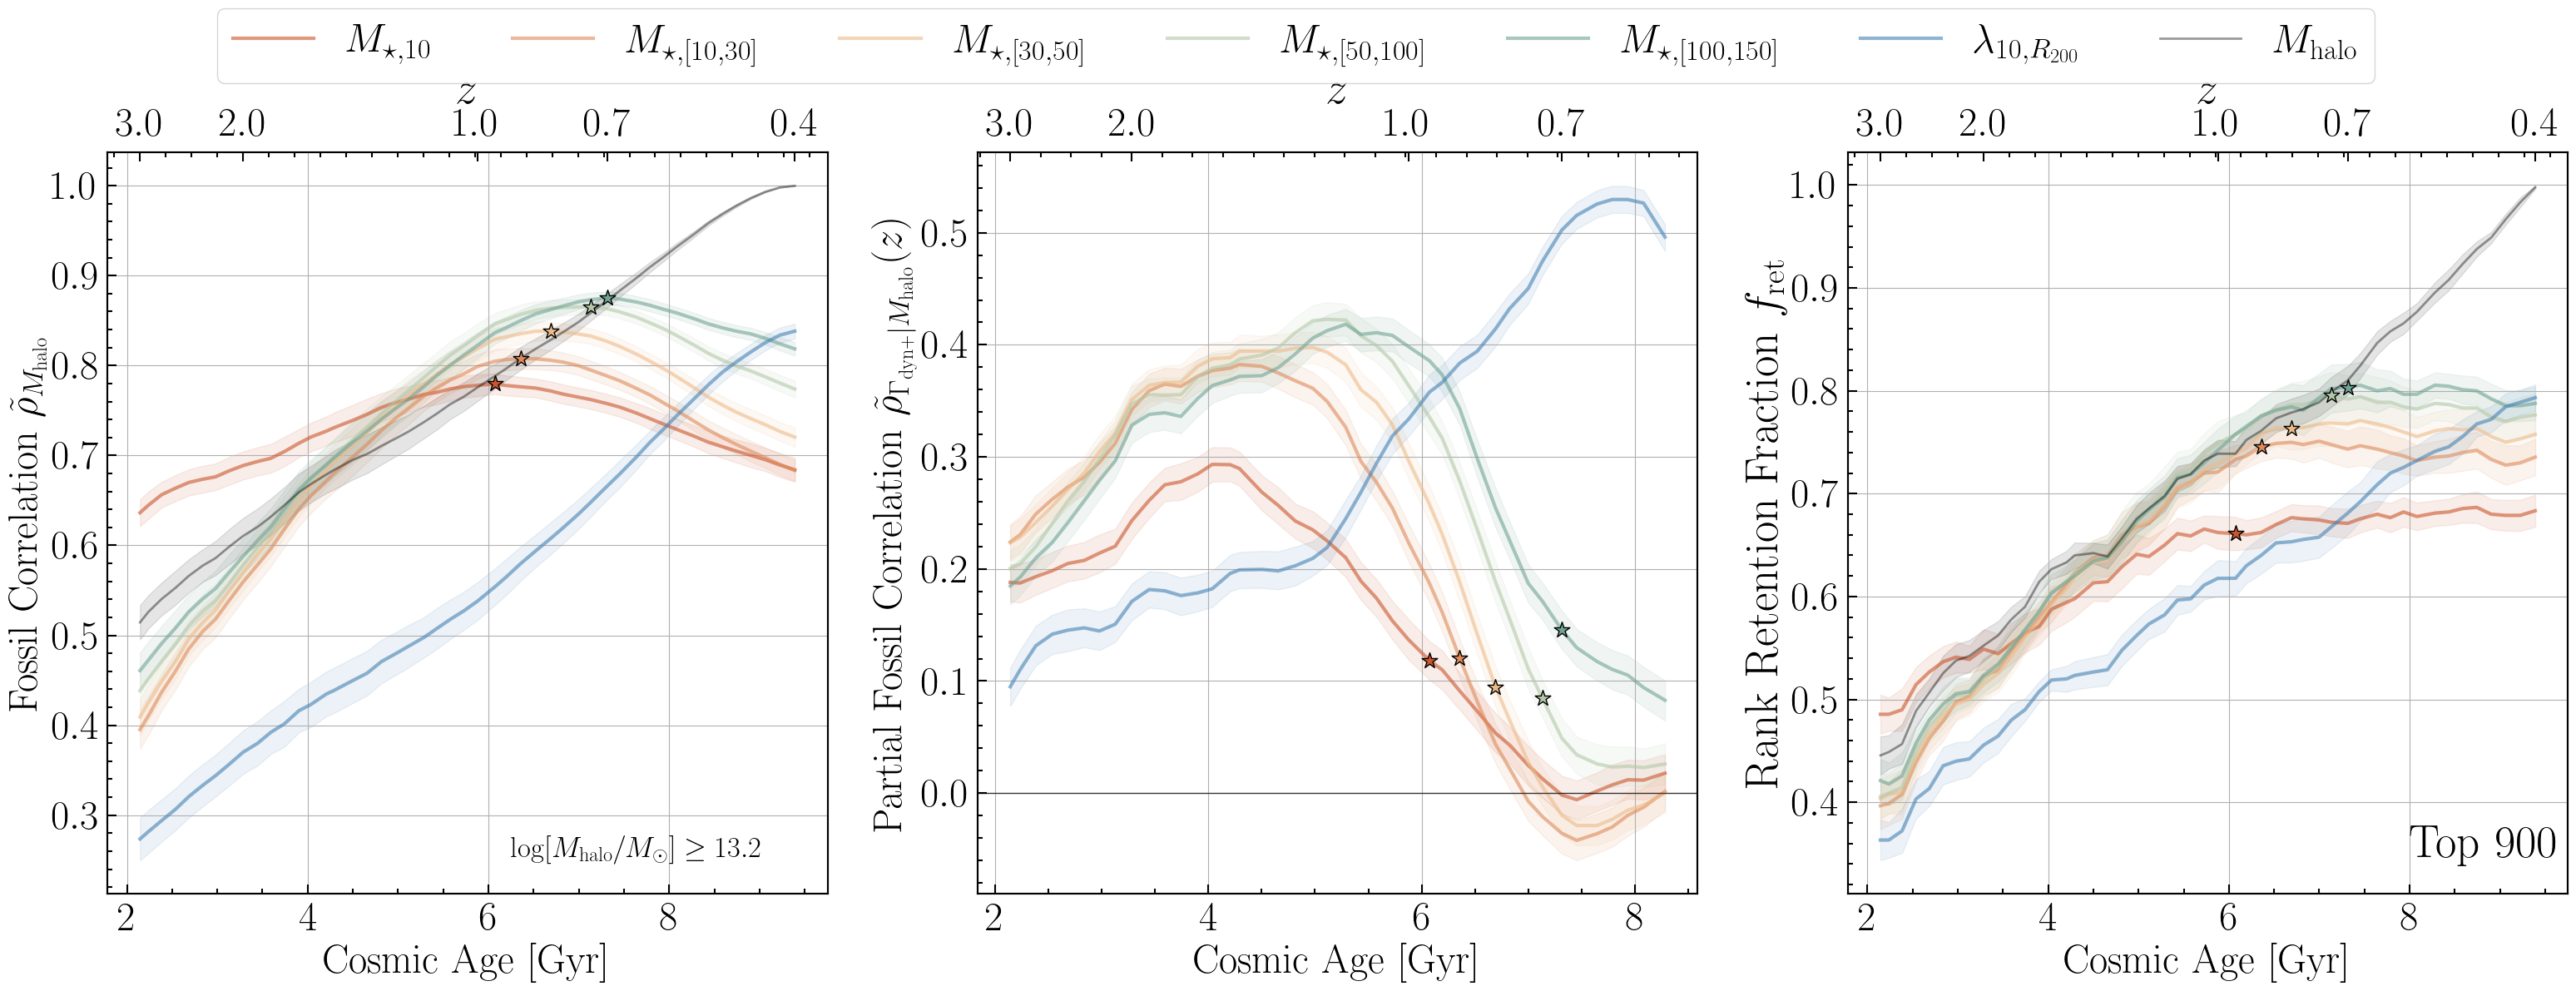

In [23]:
snap_list=np.arange(25,73,1)
fig, axlist = plt.subplots(1, 3, figsize=(32, 12),facecolor='none')
plt.subplots_adjust(hspace=0)
ax1=axlist[0]
sma_list=[10,30,50,100,150]
color_list = palettable.cartocolors.diverging.Geyser_6.mpl_colors[::-1]
max_index_list=[]
for i in range(len(sma_list)):
    sma=sma_list[i]
    if i>0:
        sma0=sma_list[i-1]
    color=color_list[i]
    snapnum_tab=[]
    corr_tab=[]
    corr_err_tab=[]
    mask1=(tab2[mask_exl]['mass_halo']>10**13.2)
    if i>0:
        xdata=np.log10(tab2[mask_exl][mask1]['aper_'+str(sma)+'_gal']-tab2[mask_exl][mask1]['aper_'+str(sma0)+'_gal'])
        label=r'$M_{\star,['+str(sma0)+','+str(sma)+']}$'
    else:
        xdata=np.log10(tab2[mask_exl][mask1]['aper_'+str(sma)+'_gal'])
        label=r'$M_{\star,'+str(sma)+'}$'
    for snapnum in range(25,73,1):
        ydata=np.log10(tab_prog_mass[mask1]['mhalo_past_'+str(snapnum)])
        mask_pk=(xdata>0)
        corr,corr_err=bootstrap_corr(xdata[mask_pk],ydata[mask_pk])
        corr_tab.append(corr)
        corr_err_tab.append(corr_err)
        snapnum_tab.append(snapnum)
    # ax1.errorbar(age_tab[25:73],corr_tab,yerr=corr_err_tab, alpha=0.7, fmt='h-', color=color,
    #             capsize=3, capthick=1, elinewidth=1, markersize=9,label=label) 
    max_index=np.where(corr_tab==max(corr_tab))[0][0]
    max_index_list.append(max_index)
    ax1.scatter(age_tab[25:73][max_index],corr_tab[max_index],color=color, s=200, marker='*', edgecolors='black', zorder=5)
    ax1.plot(age_tab[25:73],corr_tab,color=color, alpha=0.6, label=label,lw=3)
    ax1.fill_between(age_tab[25:73],np.array(corr_tab)-np.array(corr_err_tab),np.array(corr_tab)+np.array(corr_err_tab),color=color, alpha=0.1)
snapnum_tab=[]
corr_tab=[]
corr_err_tab=[]
for snapnum in range(25,73,1):
    ydata=np.log10(tab_prog_mass[mask1]['mhalo_past_'+str(snapnum)])
    xdata=np.log10(tab2[mask_exl][mask1]['richness_cut_r200_10']+1)
    mask_pk=(xdata>=0)
    corr,corr_err=bootstrap_corr(xdata[mask_pk],ydata[mask_pk])
    corr_tab.append(corr)
    corr_err_tab.append(corr_err)
    snapnum_tab.append(snapnum)
# ax1.errorbar(age_tab[25:73],corr_tab,yerr=corr_err_tab,color='steelblue', alpha=0.25, fmt='h--',
#             capsize=3, capthick=1, elinewidth=1, markersize=9,label=r'$\lambda_{10,R_{200}}$')
ax1.plot(age_tab[25:73],corr_tab,color='steelblue', alpha=0.6, label=r'$\lambda_{10,R_{200}}$', lw=3)
ax1.fill_between(age_tab[25:73],np.array(corr_tab)-np.array(corr_err_tab),np.array(corr_tab)+np.array(corr_err_tab),color='steelblue', alpha=0.1)
# snapnum_tab=[]
# corr_tab=[]
# corr_err_tab=[]
# for snapnum in range(25,73,1):
#     ydata=np.log10(tab_prog_mass[mask1]['mhalo_past_'+str(snapnum)])
#     xdata=np.log10(tab2[mask_exl][mask1]['mass_halo'])
#     mask_pk=(xdata>0)
#     corr,corr_err=bootstrap_corr(xdata[mask_pk],ydata[mask_pk])
#     corr_tab.append(corr)
#     corr_err_tab.append(corr_err)
#     snapnum_tab.append(snapnum)
# ax1.errorbar(age_tab[25:73],corr_tab,yerr=corr_err_tab,color='black', alpha=0.6, fmt='h-',
#             capsize=3, capthick=1, elinewidth=1, markersize=9,label=r'$M_{\rm halo}$')
snapnum_tab=[]
corr_halo_tab=[]
corr_halo_err_tab=[]
for snapnum in range(25,73,1):
    ydata=np.log10(tab_prog_mass[mask1]['mhalo_past_'+str(snapnum)])
    xdata=np.log10(tab2[mask_exl][mask1]['mass_halo'])
    mask_pk=(xdata>0)
    corr,corr_err=bootstrap_corr(xdata[mask_pk],ydata[mask_pk])
    corr_halo_tab.append(corr)
    corr_halo_err_tab.append(corr_err)
    snapnum_tab.append(snapnum)
ax1.plot(age_tab[25:73],corr_halo_tab,color='black', alpha=0.4, lw=2,
            label=r'$M_{\rm halo}$')
ax1.fill_between(age_tab[25:73],np.array(corr_halo_tab)-np.array(corr_halo_err_tab),np.array(corr_halo_tab)+np.array(corr_halo_err_tab),color='black', alpha=0.1)   
ax1.text(0.56,0.05,r'$\log[M_{\rm halo}/M_\odot]\geq13.2$',transform=ax1.transAxes,fontsize=25)
ax1.set_ylabel(r'{\rm Fossil\ Correlation} $\tilde{\rho}_{M_{\rm halo}}$ ')
ax2=ax1.twiny()
x1,x2=ax1.get_xlim()
ax2.set_xlim(x1,x2)
ax2.set_xticks(age_tab[[25,33,50,59,72]],[r'$3.0$',r'$2.0$',r'$1.0$',r'$0.7$',r'$0.4$'])
ax2.set_xlabel(r'$z$', fontsize=40)
ax1.set_facecolor('white')
ax1.grid()
ax1.set_xlabel(r'\rm Cosmic Age [Gyr]')
ax1=axlist[2]
N=900
for i in range(len(sma_list)):
    sma=sma_list[i]
    name1='aper_'+str(sma)+'_gal'
    if i>0:
        sma0=sma_list[i-1]
        label=r'$M_{\star,['+str(sma0)+','+str(sma)+r']}$'
        name2='aper_'+str(sma0)+'_gal'
        mass_halo=topNoutselect(tab2[mask_exl],name1,name2,N)
    else:
        label=r'$M_{\star,'+str(sma)+r'}$'
        mass_halo=topNselect(tab2[mask_exl],name1,N)
    gal_num_list=mass_halo['gal_num'].astype(int)
    mask_num = np.isin(tab2[mask_exl]['gal_num'], gal_num_list)
    color=color_list[i]
    massive_halo_fraction_evolve(ax1,N,pos_x[mask_exl],pos_y[mask_exl],pos_z[mask_exl],mask_num,snap_list,color=color,label=label,alpha2=0.1,max_index=max_index_list[i])
# mass_halo=topNselect(tab2[mask_exl],'mass_halo',N)
# gal_num_list=mass_halo['gal_num'].astype(int)
# mask_num = np.isin(tab2[mask_exl]['gal_num'], gal_num_list)
# color='black'
# massive_halo_fraction_evolve(ax1,N,pos_x[mask_exl],pos_y[mask_exl],pos_z[mask_exl],mask_num,snap_list,color=color,label=r'$M_{\rm halo}$')
name='richness_cut_r200_10'
xdata=np.log10(tab2[mask_exl][name]+1)
mask_h1=(xdata>np.min(np.log10(topNselect(tab2[mask_exl],name,N)[name]+1)))
mask_h2=(xdata==np.min(np.log10(topNselect(tab2[mask_exl],name,N)[name]+1)))
index_list=np.where(mask_h2==True)[0]
true_num=N-len(xdata[mask_h1])
array=np.zeros(len(index_list))
array[:true_num]=1
np.random.shuffle(array)
for j in range(len(index_list)):
    index=index_list[j]
    mask_h2[index]=mask_h2[index]&bool(array[j])
mask_h=mask_h1|mask_h2
mask_num=mask_h
color='steelblue'
label=r'$\lambda_{10,R_{200}}$'
massive_halo_fraction_evolve(ax1,N,pos_x[mask_exl],pos_y[mask_exl],pos_z[mask_exl],mask_num,snap_list,color=color,label=label,fmt='h--',alpha2=0.1)
name='mass_halo'
xdata=np.log10(tab2[mask_exl][name])
mass_halo=topNselect(tab2[mask_exl],name,N)
gal_num_list=mass_halo['gal_num'].astype(int)
mask_num = np.isin(tab2[mask_exl]['gal_num'], gal_num_list)
color='black'
massive_halo_fraction_evolve(ax1,N,pos_x[mask_exl],pos_y[mask_exl],pos_z[mask_exl],mask_num,snap_list,color=color,label=r'$M_{\rm halo}$',alpha1=0.4,alpha2=0.1,fmt='h--',lw=2)
ax1.set_ylabel(r'\rm Rank Retention Fraction $f_{\rm ret}$',fontsize=40)
handles, labels = ax1.get_legend_handles_labels()
ax1.text(0.78,0.05,r'\rm Top %d'%N,transform=ax1.transAxes,fontsize=40)
ax1.grid()
ax1.set_xlabel(r'\rm Cosmic Age [Gyr]')
ax2=ax1.twiny()
x1,x2=ax1.get_xlim()
ax2.set_xlim(x1,x2)
ax2.set_xticks(age_tab[[25,33,50,59,72]],[r'$3.0$',r'$2.0$',r'$1.0$',r'$0.7$',r'$0.4$'])
ax2.set_xlabel(r'$z$', fontsize=40)
snap_list=np.arange(25,66,1)
colorlist=palettable.cartocolors.diverging.Geyser_6.mpl_colors[::-1]
sma_list=[10,30,50,100,150]
ax=axlist[1]
for i in range(len(sma_list)):
    sma=sma_list[i]
    if i>0:
        sma0=sma_list[i-1]
        xdata=np.log10(tab2[mask_exl]['aper_'+str(sma)+'_gal']-tab2[mask_exl]['aper_'+str(sma0)+'_gal'])
        label=r'$M_{\star,['+str(sma0)+','+str(sma)+r']~{\rm kpc}}$'
    else:
        xdata=np.log10(tab2[mask_exl]['aper_'+str(sma)+'_gal'])
        label=r'$M_{\star,'+str(sma)+r'~{\rm kpc}}$'
    partial_corr=[]
    partial_corr_up=[]
    partial_corr_down=[]
    for snap in snap_list:
        ydata=tab_prog_mass['mhalo_past_'+str(snap)]
        zdata=tab_prog_mass['macc_new3_past_'+str(snap)]
        tab_x=QTable([xdata,ydata,zdata],names=['proxy','mhalo','macc'])
        tab_pd=tab_x.to_pandas()
        mean_corr, conf_up,conf_down=bootstrap_partial_corr(tab_pd,'proxy','macc',['mhalo'],method='spearman',times=1000)
        partial_corr.append(mean_corr)
        partial_corr_up.append(conf_up)
        partial_corr_down.append(conf_down)
    # ax.errorbar(age_tab[snap_list],partial_corr,yerr=[np.asarray(partial_corr)-np.asarray(partial_corr_down),np.asarray(partial_corr_up)-np.asarray(partial_corr)],
    #             color=colorlist[i],alpha=0.6, fmt='h-',capsize=3, capthick=1, elinewidth=1, markersize=9,label=label)
    ax.scatter(age_tab[snap_list][max_index_list[i]],partial_corr[max_index_list[i]],color=colorlist[i], s=200, marker='*', edgecolors='black', zorder=5)
    ax.plot(age_tab[snap_list],partial_corr,color=colorlist[i], alpha=0.6, label=label,lw=3)
    ax.fill_between(age_tab[snap_list],np.array(partial_corr_down),np.array(partial_corr_up),color=colorlist[i], alpha=0.1)
xdata=np.log10(tab2[mask_exl]['richness_cut_r200_10']+1)
partial_corr=[]
partial_corr_up=[]
partial_corr_down=[]
for snap in snap_list:
    ydata=tab_prog_mass['mhalo_past_'+str(snap)]
    zdata=tab_prog_mass['macc_new3_past_'+str(snap)]
    tab_x=QTable([xdata,ydata,zdata],names=['proxy','mhalo','macc'])
    tab_pd=tab_x.to_pandas()
    mean_corr, conf_up,conf_down=bootstrap_partial_corr(tab_pd,'proxy','macc',['mhalo'],method='spearman',times=1000)
    partial_corr.append(mean_corr)
    partial_corr_up.append(conf_up)
    partial_corr_down.append(conf_down)
# ax.errorbar(age_tab[snap_list],partial_corr,yerr=[np.asarray(partial_corr)-np.asarray(partial_corr_down),np.asarray(partial_corr_up)-np.asarray(partial_corr)],
#             color='steelblue', fmt='o--',capsize=3, capthick=1, elinewidth=1, markersize=9,label=r'$\lambda_{10,R_{200}}$')
ax.plot(age_tab[snap_list],partial_corr,color='steelblue', alpha=0.6, label=r'$\lambda_{10,R_{200}}$', lw=3)
ax.fill_between(age_tab[snap_list],np.array(partial_corr_down),np.array(partial_corr_up),color='steelblue', alpha=0.1)
ax.set_xlabel(r'\rm Cosmic Age [Gyr]')
ax.set_ylabel(r'{\rm Partial Fossil Correlation} $\tilde{\rho}_{\Gamma_{\rm dyn+}|M_{\rm halo}}(z)$')
ax.grid()
ax.axhline(0, color='black', linestyle='-', linewidth=1, alpha=0.7)
ax2=ax.twiny()
x1,x2=ax.get_xlim()
ax2.set_xlim(x1,x2)
ax2.set_xticks(age_tab[[25,33,50,59]],[r'$3.0$',r'$2.0$',r'$1.0$',r'$0.7$'])
ax2.set_xlabel(r'$z$', fontsize=40)
plt.tight_layout()
plt.subplots_adjust(hspace=0)
for ax in axlist:
    ax.set_facecolor('white')
fig.legend(handles, labels, loc='upper center', bbox_to_anchor=(0.5, 1.04), 
           ncol=len(handles), fontsize=35)
fig.savefig(fig_dir+'Fig2.pdf',dpi=100,bbox_inches='tight',transparent=True)

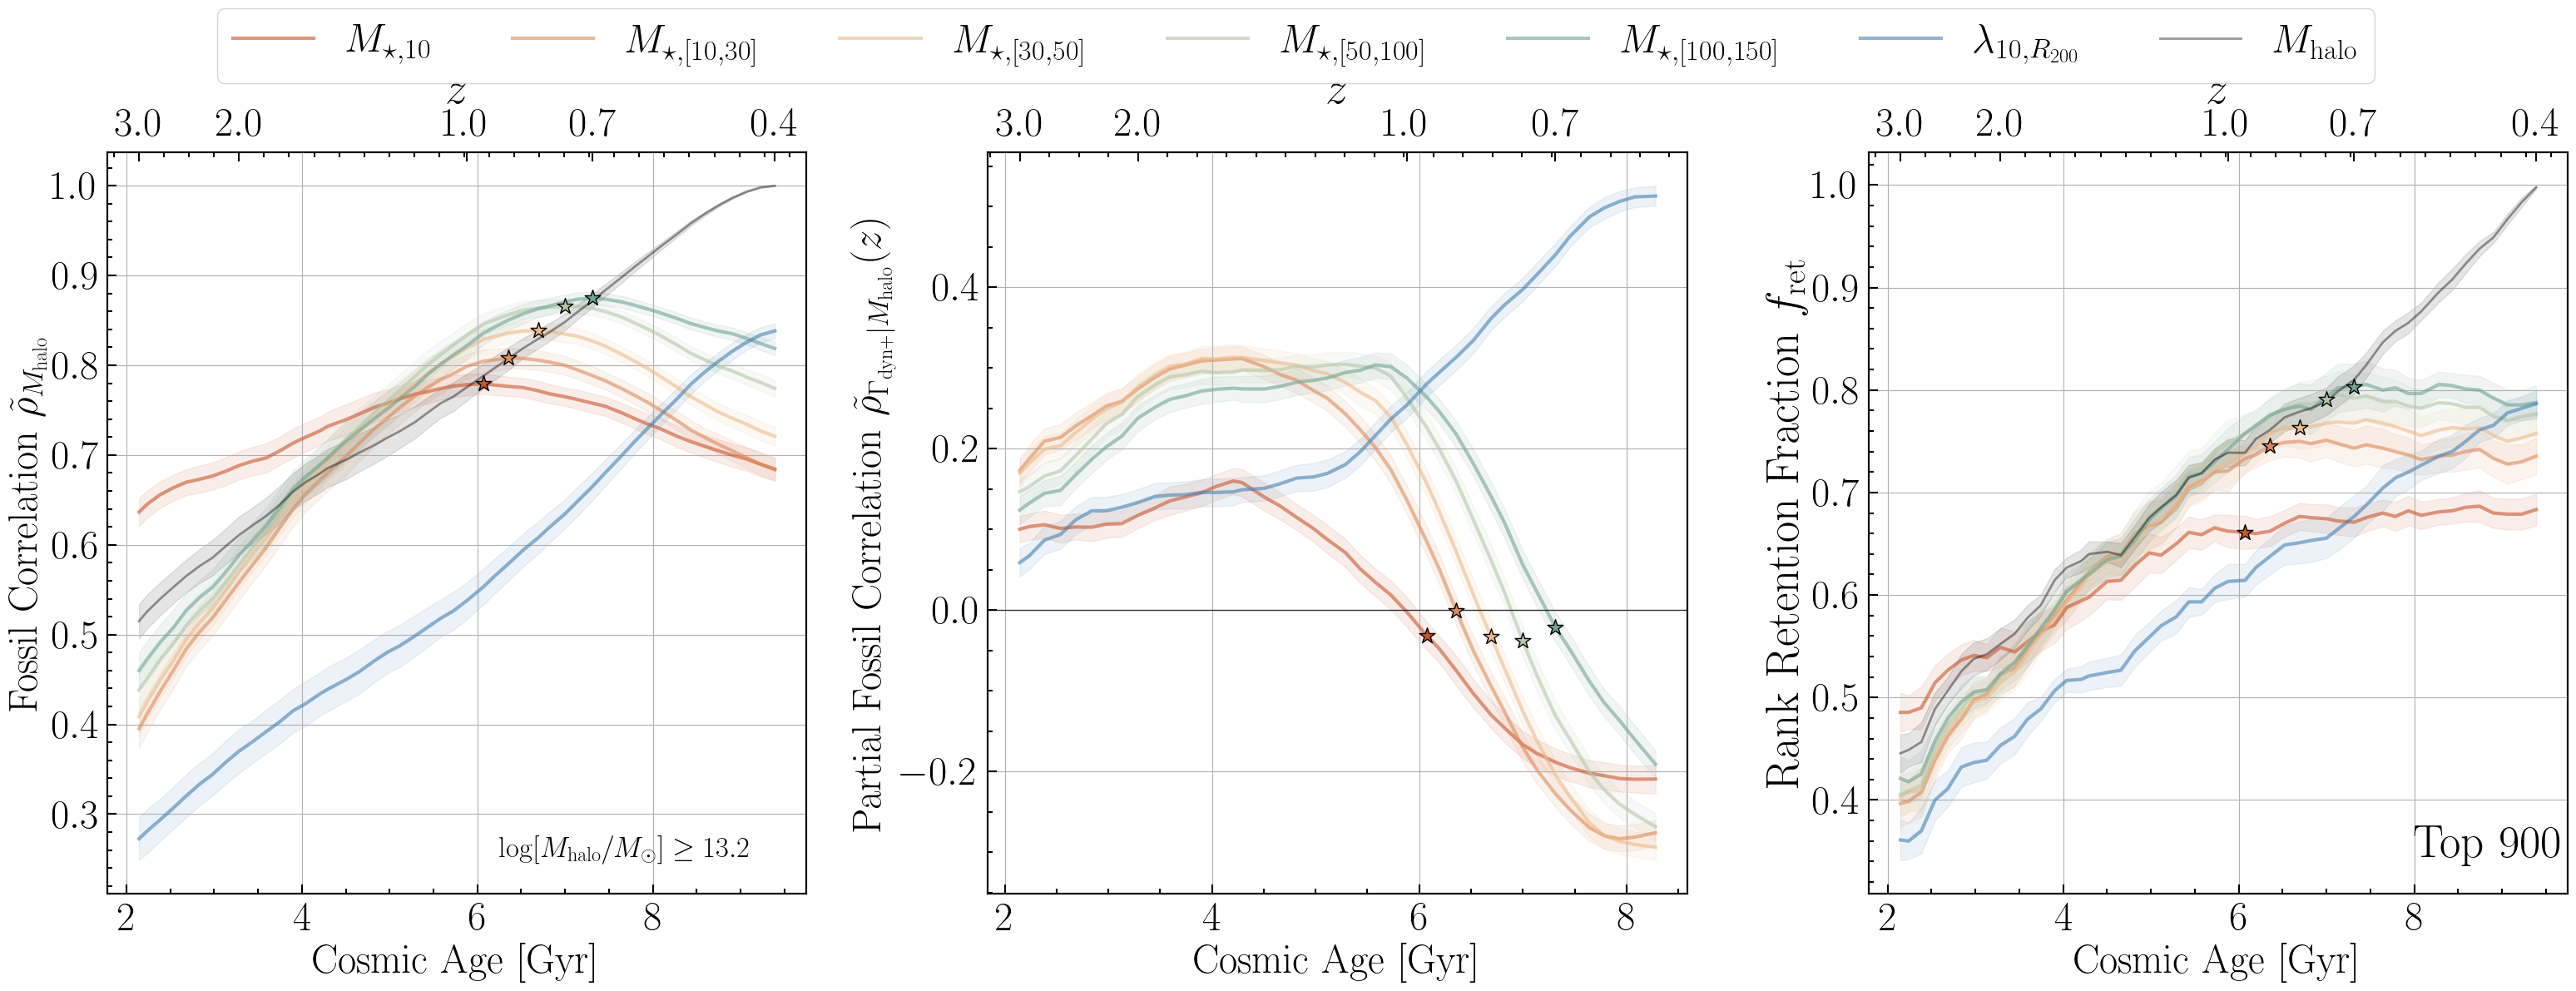

In [30]:
snap_list=np.arange(25,73,1)
fig, axlist = plt.subplots(1, 3, figsize=(32, 12),facecolor='none')
plt.subplots_adjust(hspace=0)
ax1=axlist[0]
sma_list=[10,30,50,100,150]
color_list = palettable.cartocolors.diverging.Geyser_6.mpl_colors[::-1]
max_index_list=[]
for i in range(len(sma_list)):
    sma=sma_list[i]
    if i>0:
        sma0=sma_list[i-1]
    color=color_list[i]
    snapnum_tab=[]
    corr_tab=[]
    corr_err_tab=[]
    mask1=(tab2[mask_exl]['mass_halo']>10**13.2)
    if i>0:
        xdata=np.log10(tab2[mask_exl][mask1]['aper_'+str(sma)+'_gal']-tab2[mask_exl][mask1]['aper_'+str(sma0)+'_gal'])
        label=r'$M_{\star,['+str(sma0)+','+str(sma)+']}$'
    else:
        xdata=np.log10(tab2[mask_exl][mask1]['aper_'+str(sma)+'_gal'])
        label=r'$M_{\star,'+str(sma)+'}$'
    for snapnum in range(25,73,1):
        ydata=np.log10(tab_prog_mass[mask1]['mhalo_past_'+str(snapnum)])
        mask_pk=(xdata>0)
        corr,corr_err=bootstrap_corr(xdata[mask_pk],ydata[mask_pk])
        corr_tab.append(corr)
        corr_err_tab.append(corr_err)
        snapnum_tab.append(snapnum)
    # ax1.errorbar(age_tab[25:73],corr_tab,yerr=corr_err_tab, alpha=0.7, fmt='h-', color=color,
    #             capsize=3, capthick=1, elinewidth=1, markersize=9,label=label) 
    max_index=np.where(corr_tab==max(corr_tab))[0][0]
    max_index_list.append(max_index)
    ax1.scatter(age_tab[25:73][max_index],corr_tab[max_index],color=color, s=200, marker='*', edgecolors='black', zorder=5)
    ax1.plot(age_tab[25:73],corr_tab,color=color, alpha=0.6, label=label,lw=3)
    ax1.fill_between(age_tab[25:73],np.array(corr_tab)-np.array(corr_err_tab),np.array(corr_tab)+np.array(corr_err_tab),color=color, alpha=0.1)
snapnum_tab=[]
corr_tab=[]
corr_err_tab=[]
for snapnum in range(25,73,1):
    ydata=np.log10(tab_prog_mass[mask1]['mhalo_past_'+str(snapnum)])
    xdata=np.log10(tab2[mask_exl][mask1]['richness_cut_r200_10']+1)
    mask_pk=(xdata>=0)
    corr,corr_err=bootstrap_corr(xdata[mask_pk],ydata[mask_pk])
    corr_tab.append(corr)
    corr_err_tab.append(corr_err)
    snapnum_tab.append(snapnum)
# ax1.errorbar(age_tab[25:73],corr_tab,yerr=corr_err_tab,color='steelblue', alpha=0.25, fmt='h--',
#             capsize=3, capthick=1, elinewidth=1, markersize=9,label=r'$\lambda_{10,R_{200}}$')
ax1.plot(age_tab[25:73],corr_tab,color='steelblue', alpha=0.6, label=r'$\lambda_{10,R_{200}}$', lw=3)
ax1.fill_between(age_tab[25:73],np.array(corr_tab)-np.array(corr_err_tab),np.array(corr_tab)+np.array(corr_err_tab),color='steelblue', alpha=0.1)
# snapnum_tab=[]
# corr_tab=[]
# corr_err_tab=[]
# for snapnum in range(25,73,1):
#     ydata=np.log10(tab_prog_mass[mask1]['mhalo_past_'+str(snapnum)])
#     xdata=np.log10(tab2[mask_exl][mask1]['mass_halo'])
#     mask_pk=(xdata>0)
#     corr,corr_err=bootstrap_corr(xdata[mask_pk],ydata[mask_pk])
#     corr_tab.append(corr)
#     corr_err_tab.append(corr_err)
#     snapnum_tab.append(snapnum)
# ax1.errorbar(age_tab[25:73],corr_tab,yerr=corr_err_tab,color='black', alpha=0.6, fmt='h-',
#             capsize=3, capthick=1, elinewidth=1, markersize=9,label=r'$M_{\rm halo}$')
snapnum_tab=[]
corr_halo_tab=[]
corr_halo_err_tab=[]
for snapnum in range(25,73,1):
    ydata=np.log10(tab_prog_mass[mask1]['mhalo_past_'+str(snapnum)])
    xdata=np.log10(tab2[mask_exl][mask1]['mass_halo'])
    mask_pk=(xdata>0)
    corr,corr_err=bootstrap_corr(xdata[mask_pk],ydata[mask_pk])
    corr_halo_tab.append(corr)
    corr_halo_err_tab.append(corr_err)
    snapnum_tab.append(snapnum)
ax1.plot(age_tab[25:73],corr_halo_tab,color='black', alpha=0.4, lw=2,
            label=r'$M_{\rm halo}$')
ax1.fill_between(age_tab[25:73],np.array(corr_halo_tab)-np.array(corr_halo_err_tab),np.array(corr_halo_tab)+np.array(corr_halo_err_tab),color='black', alpha=0.1)   
ax1.text(0.56,0.05,r'$\log[M_{\rm halo}/M_\odot]\geq13.2$',transform=ax1.transAxes,fontsize=25)
ax1.set_ylabel(r'{\rm Fossil\ Correlation} $\tilde{\rho}_{M_{\rm halo}}$ ')
ax2=ax1.twiny()
x1,x2=ax1.get_xlim()
ax2.set_xlim(x1,x2)
ax2.set_xticks(age_tab[[25,33,50,59,72]],[r'$3.0$',r'$2.0$',r'$1.0$',r'$0.7$',r'$0.4$'])
ax2.set_xlabel(r'$z$', fontsize=40)
ax1.set_facecolor('white')
ax1.grid()
ax1.set_xlabel(r'\rm Cosmic Age [Gyr]')
ax1=axlist[2]
N=900
for i in range(len(sma_list)):
    sma=sma_list[i]
    name1='aper_'+str(sma)+'_gal'
    if i>0:
        sma0=sma_list[i-1]
        label=r'$M_{\star,['+str(sma0)+','+str(sma)+r']}$'
        name2='aper_'+str(sma0)+'_gal'
        mass_halo=topNoutselect(tab2[mask_exl],name1,name2,N)
    else:
        label=r'$M_{\star,'+str(sma)+r'}$'
        mass_halo=topNselect(tab2[mask_exl],name1,N)
    gal_num_list=mass_halo['gal_num'].astype(int)
    mask_num = np.isin(tab2[mask_exl]['gal_num'], gal_num_list)
    color=color_list[i]
    massive_halo_fraction_evolve(ax1,N,pos_x[mask_exl],pos_y[mask_exl],pos_z[mask_exl],mask_num,snap_list,color=color,label=label,alpha2=0.1,max_index=max_index_list[i])
# mass_halo=topNselect(tab2[mask_exl],'mass_halo',N)
# gal_num_list=mass_halo['gal_num'].astype(int)
# mask_num = np.isin(tab2[mask_exl]['gal_num'], gal_num_list)
# color='black'
# massive_halo_fraction_evolve(ax1,N,pos_x[mask_exl],pos_y[mask_exl],pos_z[mask_exl],mask_num,snap_list,color=color,label=r'$M_{\rm halo}$')
name='richness_cut_r200_10'
xdata=np.log10(tab2[mask_exl][name]+1)
mask_h1=(xdata>np.min(np.log10(topNselect(tab2[mask_exl],name,N)[name]+1)))
mask_h2=(xdata==np.min(np.log10(topNselect(tab2[mask_exl],name,N)[name]+1)))
index_list=np.where(mask_h2==True)[0]
true_num=N-len(xdata[mask_h1])
array=np.zeros(len(index_list))
array[:true_num]=1
np.random.shuffle(array)
for j in range(len(index_list)):
    index=index_list[j]
    mask_h2[index]=mask_h2[index]&bool(array[j])
mask_h=mask_h1|mask_h2
mask_num=mask_h
color='steelblue'
label=r'$\lambda_{10,R_{200}}$'
massive_halo_fraction_evolve(ax1,N,pos_x[mask_exl],pos_y[mask_exl],pos_z[mask_exl],mask_num,snap_list,color=color,label=label,fmt='h--',alpha2=0.1)
name='mass_halo'
xdata=np.log10(tab2[mask_exl][name])
mass_halo=topNselect(tab2[mask_exl],name,N)
gal_num_list=mass_halo['gal_num'].astype(int)
mask_num = np.isin(tab2[mask_exl]['gal_num'], gal_num_list)
color='black'
massive_halo_fraction_evolve(ax1,N,pos_x[mask_exl],pos_y[mask_exl],pos_z[mask_exl],mask_num,snap_list,color=color,label=r'$M_{\rm halo}$',alpha1=0.4,alpha2=0.1,fmt='h--',lw=2)
ax1.set_ylabel(r'\rm Rank Retention Fraction $f_{\rm ret}$',fontsize=40)
handles, labels = ax1.get_legend_handles_labels()
ax1.text(0.78,0.05,r'\rm Top %d'%N,transform=ax1.transAxes,fontsize=40)
ax1.grid()
ax1.set_xlabel(r'\rm Cosmic Age [Gyr]')
ax2=ax1.twiny()
x1,x2=ax1.get_xlim()
ax2.set_xlim(x1,x2)
ax2.set_xticks(age_tab[[25,33,50,59,72]],[r'$3.0$',r'$2.0$',r'$1.0$',r'$0.7$',r'$0.4$'])
ax2.set_xlabel(r'$z$', fontsize=40)
snap_list=np.arange(25,66,1)
colorlist=palettable.cartocolors.diverging.Geyser_6.mpl_colors[::-1]
sma_list=[10,30,50,100,150]
ax=axlist[1]
for i in range(len(sma_list)):
    sma=sma_list[i]
    if i>0:
        sma0=sma_list[i-1]
        xdata=np.log10(tab2[mask_exl]['aper_'+str(sma)+'_gal']-tab2[mask_exl]['aper_'+str(sma0)+'_gal'])
        label=r'$M_{\star,['+str(sma0)+','+str(sma)+r']~{\rm kpc}}$'
    else:
        xdata=np.log10(tab2[mask_exl]['aper_'+str(sma)+'_gal'])
        label=r'$M_{\star,'+str(sma)+r'~{\rm kpc}}$'
    partial_corr=[]
    partial_corr_up=[]
    partial_corr_down=[]
    for snap in snap_list:
        ydata=tab_prog_mass['mhalo_past_'+str(snap)]
        zdata=tab_prog_mass['macc_new2_past_'+str(snap)]
        tab_x=QTable([xdata,ydata,zdata],names=['proxy','mhalo','macc'])
        tab_pd=tab_x.to_pandas()
        mean_corr, conf_up,conf_down=bootstrap_partial_corr(tab_pd,'proxy','macc',['mhalo'],method='spearman',times=1000)
        partial_corr.append(mean_corr)
        partial_corr_up.append(conf_up)
        partial_corr_down.append(conf_down)
    # ax.errorbar(age_tab[snap_list],partial_corr,yerr=[np.asarray(partial_corr)-np.asarray(partial_corr_down),np.asarray(partial_corr_up)-np.asarray(partial_corr)],
    #             color=colorlist[i],alpha=0.6, fmt='h-',capsize=3, capthick=1, elinewidth=1, markersize=9,label=label)
    ax.scatter(age_tab[snap_list][max_index_list[i]],partial_corr[max_index_list[i]],color=colorlist[i], s=200, marker='*', edgecolors='black', zorder=5)
    ax.plot(age_tab[snap_list],partial_corr,color=colorlist[i], alpha=0.6, label=label,lw=3)
    ax.fill_between(age_tab[snap_list],np.array(partial_corr_down),np.array(partial_corr_up),color=colorlist[i], alpha=0.1)
xdata=np.log10(tab2[mask_exl]['richness_cut_r200_10']+1)
partial_corr=[]
partial_corr_up=[]
partial_corr_down=[]
for snap in snap_list:
    ydata=tab_prog_mass['mhalo_past_'+str(snap)]
    zdata=tab_prog_mass['macc_new2_past_'+str(snap)]
    tab_x=QTable([xdata,ydata,zdata],names=['proxy','mhalo','macc'])
    tab_pd=tab_x.to_pandas()
    mean_corr, conf_up,conf_down=bootstrap_partial_corr(tab_pd,'proxy','macc',['mhalo'],method='spearman',times=1000)
    partial_corr.append(mean_corr)
    partial_corr_up.append(conf_up)
    partial_corr_down.append(conf_down)
# ax.errorbar(age_tab[snap_list],partial_corr,yerr=[np.asarray(partial_corr)-np.asarray(partial_corr_down),np.asarray(partial_corr_up)-np.asarray(partial_corr)],
#             color='steelblue', fmt='o--',capsize=3, capthick=1, elinewidth=1, markersize=9,label=r'$\lambda_{10,R_{200}}$')
ax.plot(age_tab[snap_list],partial_corr,color='steelblue', alpha=0.6, label=r'$\lambda_{10,R_{200}}$', lw=3)
ax.fill_between(age_tab[snap_list],np.array(partial_corr_down),np.array(partial_corr_up),color='steelblue', alpha=0.1)
ax.set_xlabel(r'\rm Cosmic Age [Gyr]')
ax.set_ylabel(r'{\rm Partial Fossil Correlation} $\tilde{\rho}_{\Gamma_{\rm dyn+}|M_{\rm halo}}(z)$')
ax.grid()
ax.axhline(0, color='black', linestyle='-', linewidth=1, alpha=0.7)
ax2=ax.twiny()
x1,x2=ax.get_xlim()
ax2.set_xlim(x1,x2)
ax2.set_xticks(age_tab[[25,33,50,59]],[r'$3.0$',r'$2.0$',r'$1.0$',r'$0.7$'])
ax2.set_xlabel(r'$z$', fontsize=40)
plt.tight_layout()
plt.subplots_adjust(hspace=0)
for ax in axlist:
    ax.set_facecolor('white')
fig.legend(handles, labels, loc='upper center', bbox_to_anchor=(0.5, 1.04), 
           ncol=len(handles), fontsize=35)

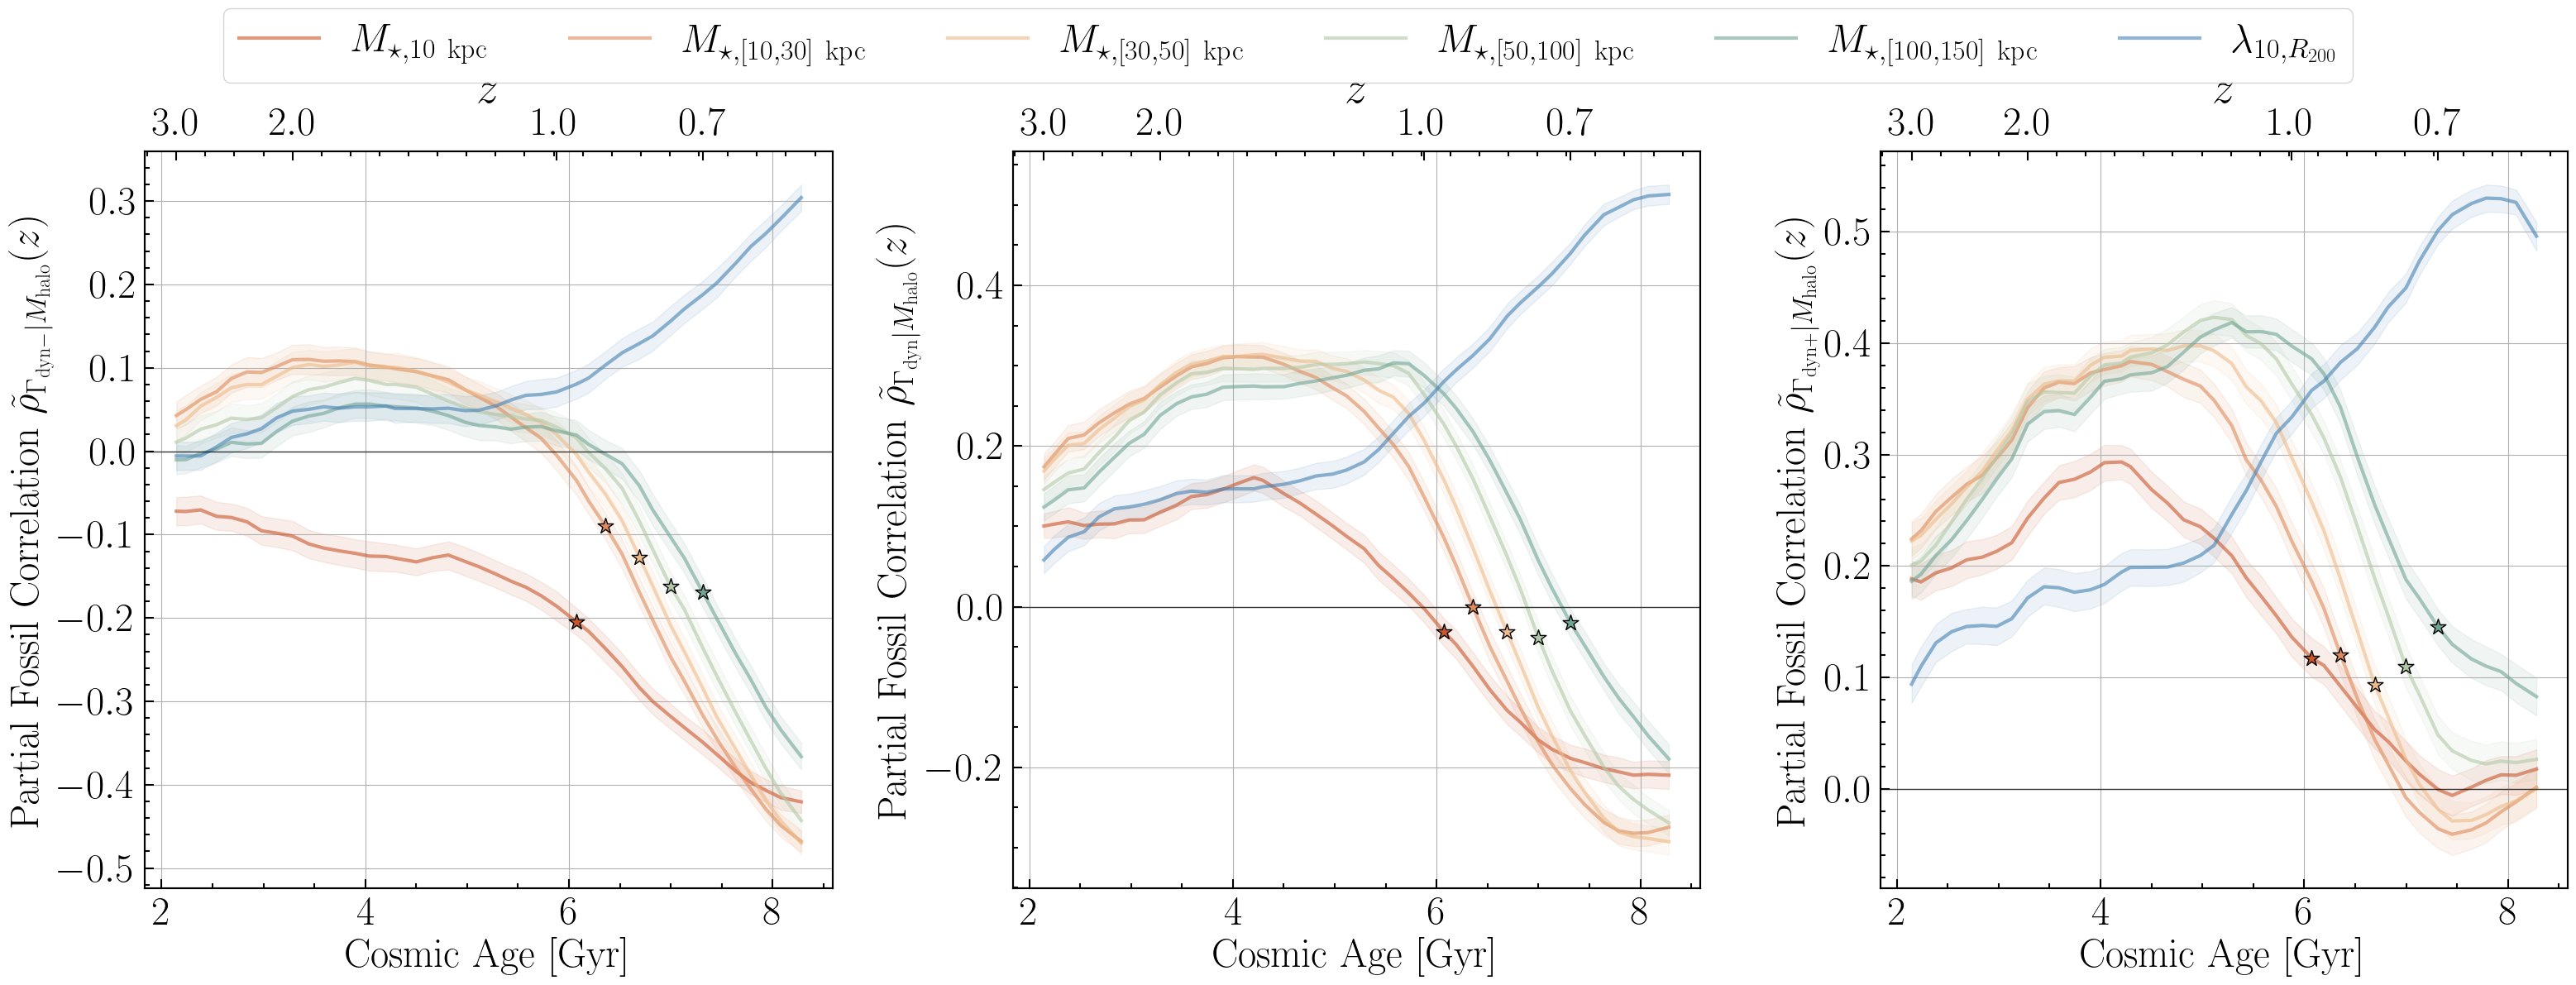

In [36]:
snap_list=np.arange(25,73,1)
fig, axlist = plt.subplots(1, 3, figsize=(32, 12),facecolor='none')
plt.subplots_adjust(hspace=0)
snap_list=np.arange(25,66,1)
colorlist=palettable.cartocolors.diverging.Geyser_6.mpl_colors[::-1]
sma_list=[10,30,50,100,150]
ax=axlist[0]
for i in range(len(sma_list)):
    sma=sma_list[i]
    if i>0:
        sma0=sma_list[i-1]
        xdata=np.log10(tab2[mask_exl]['aper_'+str(sma)+'_gal']-tab2[mask_exl]['aper_'+str(sma0)+'_gal'])
        label=r'$M_{\star,['+str(sma0)+','+str(sma)+r']~{\rm kpc}}$'
    else:
        xdata=np.log10(tab2[mask_exl]['aper_'+str(sma)+'_gal'])
        label=r'$M_{\star,'+str(sma)+r'~{\rm kpc}}$'
    partial_corr=[]
    partial_corr_up=[]
    partial_corr_down=[]
    for snap in snap_list:
        ydata=tab_prog_mass['mhalo_past_'+str(snap)]
        zdata=tab_prog_mass['macc_new_past_'+str(snap)]
        tab_x=QTable([xdata,ydata,zdata],names=['proxy','mhalo','macc'])
        tab_pd=tab_x.to_pandas()
        mean_corr, conf_up,conf_down=bootstrap_partial_corr(tab_pd,'proxy','macc',['mhalo'],method='spearman',times=1000)
        partial_corr.append(mean_corr)
        partial_corr_up.append(conf_up)
        partial_corr_down.append(conf_down)
    # ax.errorbar(age_tab[snap_list],partial_corr,yerr=[np.asarray(partial_corr)-np.asarray(partial_corr_down),np.asarray(partial_corr_up)-np.asarray(partial_corr)],
    #             color=colorlist[i],alpha=0.6, fmt='h-',capsize=3, capthick=1, elinewidth=1, markersize=9,label=label)
    ax.scatter(age_tab[snap_list][max_index_list[i]],partial_corr[max_index_list[i]],color=colorlist[i], s=200, marker='*', edgecolors='black', zorder=5)
    ax.plot(age_tab[snap_list],partial_corr,color=colorlist[i], alpha=0.6, label=label,lw=3)
    ax.fill_between(age_tab[snap_list],np.array(partial_corr_down),np.array(partial_corr_up),color=colorlist[i], alpha=0.1)
xdata=np.log10(tab2[mask_exl]['richness_cut_r200_10']+1)
partial_corr=[]
partial_corr_up=[]
partial_corr_down=[]
for snap in snap_list:
    ydata=tab_prog_mass['mhalo_past_'+str(snap)]
    zdata=tab_prog_mass['macc_new_past_'+str(snap)]
    tab_x=QTable([xdata,ydata,zdata],names=['proxy','mhalo','macc'])
    tab_pd=tab_x.to_pandas()
    mean_corr, conf_up,conf_down=bootstrap_partial_corr(tab_pd,'proxy','macc',['mhalo'],method='spearman',times=1000)
    partial_corr.append(mean_corr)
    partial_corr_up.append(conf_up)
    partial_corr_down.append(conf_down)
# ax.errorbar(age_tab[snap_list],partial_corr,yerr=[np.asarray(partial_corr)-np.asarray(partial_corr_down),np.asarray(partial_corr_up)-np.asarray(partial_corr)],
#             color='steelblue', fmt='o--',capsize=3, capthick=1, elinewidth=1, markersize=9,label=r'$\lambda_{10,R_{200}}$')
ax.plot(age_tab[snap_list],partial_corr,color='steelblue', alpha=0.6, label=r'$\lambda_{10,R_{200}}$', lw=3)
ax.fill_between(age_tab[snap_list],np.array(partial_corr_down),np.array(partial_corr_up),color='steelblue', alpha=0.1)
ax.set_xlabel(r'\rm Cosmic Age [Gyr]')
ax.set_ylabel(r'{\rm Partial Fossil Correlation} $\tilde{\rho}_{\Gamma_{\rm dyn-}|M_{\rm halo}}(z)$')
ax.grid()
ax.axhline(0, color='black', linestyle='-', linewidth=1, alpha=0.7)
ax2=ax.twiny()
x1,x2=ax.get_xlim()
ax2.set_xlim(x1,x2)
ax2.set_xticks(age_tab[[25,33,50,59]],[r'$3.0$',r'$2.0$',r'$1.0$',r'$0.7$'])
ax2.set_xlabel(r'$z$', fontsize=40)
snap_list=np.arange(25,66,1)
colorlist=palettable.cartocolors.diverging.Geyser_6.mpl_colors[::-1]
sma_list=[10,30,50,100,150]
ax=axlist[2]
for i in range(len(sma_list)):
    sma=sma_list[i]
    if i>0:
        sma0=sma_list[i-1]
        xdata=np.log10(tab2[mask_exl]['aper_'+str(sma)+'_gal']-tab2[mask_exl]['aper_'+str(sma0)+'_gal'])
        label=r'$M_{\star,['+str(sma0)+','+str(sma)+r']~{\rm kpc}}$'
    else:
        xdata=np.log10(tab2[mask_exl]['aper_'+str(sma)+'_gal'])
        label=r'$M_{\star,'+str(sma)+r'~{\rm kpc}}$'
    partial_corr=[]
    partial_corr_up=[]
    partial_corr_down=[]
    for snap in snap_list:
        ydata=tab_prog_mass['mhalo_past_'+str(snap)]
        zdata=tab_prog_mass['macc_new3_past_'+str(snap)]
        tab_x=QTable([xdata,ydata,zdata],names=['proxy','mhalo','macc'])
        tab_pd=tab_x.to_pandas()
        mean_corr, conf_up,conf_down=bootstrap_partial_corr(tab_pd,'proxy','macc',['mhalo'],method='spearman',times=1000)
        partial_corr.append(mean_corr)
        partial_corr_up.append(conf_up)
        partial_corr_down.append(conf_down)
    # ax.errorbar(age_tab[snap_list],partial_corr,yerr=[np.asarray(partial_corr)-np.asarray(partial_corr_down),np.asarray(partial_corr_up)-np.asarray(partial_corr)],
    #             color=colorlist[i],alpha=0.6, fmt='h-',capsize=3, capthick=1, elinewidth=1, markersize=9,label=label)
    ax.scatter(age_tab[snap_list][max_index_list[i]],partial_corr[max_index_list[i]],color=colorlist[i], s=200, marker='*', edgecolors='black', zorder=5)
    ax.plot(age_tab[snap_list],partial_corr,color=colorlist[i], alpha=0.6, label=label,lw=3)
    ax.fill_between(age_tab[snap_list],np.array(partial_corr_down),np.array(partial_corr_up),color=colorlist[i], alpha=0.1)
xdata=np.log10(tab2[mask_exl]['richness_cut_r200_10']+1)
partial_corr=[]
partial_corr_up=[]
partial_corr_down=[]
for snap in snap_list:
    ydata=tab_prog_mass['mhalo_past_'+str(snap)]
    zdata=tab_prog_mass['macc_new3_past_'+str(snap)]
    tab_x=QTable([xdata,ydata,zdata],names=['proxy','mhalo','macc'])
    tab_pd=tab_x.to_pandas()
    mean_corr, conf_up,conf_down=bootstrap_partial_corr(tab_pd,'proxy','macc',['mhalo'],method='spearman',times=1000)
    partial_corr.append(mean_corr)
    partial_corr_up.append(conf_up)
    partial_corr_down.append(conf_down)
# ax.errorbar(age_tab[snap_list],partial_corr,yerr=[np.asarray(partial_corr)-np.asarray(partial_corr_down),np.asarray(partial_corr_up)-np.asarray(partial_corr)],
#             color='steelblue', fmt='o--',capsize=3, capthick=1, elinewidth=1, markersize=9,label=r'$\lambda_{10,R_{200}}$')
ax.plot(age_tab[snap_list],partial_corr,color='steelblue', alpha=0.6, label=r'$\lambda_{10,R_{200}}$', lw=3)
ax.fill_between(age_tab[snap_list],np.array(partial_corr_down),np.array(partial_corr_up),color='steelblue', alpha=0.1)
ax.set_xlabel(r'\rm Cosmic Age [Gyr]')
ax.set_ylabel(r'{\rm Partial Fossil Correlation} $\tilde{\rho}_{\Gamma_{\rm dyn+}|M_{\rm halo}}(z)$')
ax.grid()
ax.axhline(0, color='black', linestyle='-', linewidth=1, alpha=0.7)
ax2=ax.twiny()
x1,x2=ax.get_xlim()
ax2.set_xlim(x1,x2)
ax2.set_xticks(age_tab[[25,33,50,59]],[r'$3.0$',r'$2.0$',r'$1.0$',r'$0.7$'])
ax2.set_xlabel(r'$z$', fontsize=40)
snap_list=np.arange(25,66,1)
colorlist=palettable.cartocolors.diverging.Geyser_6.mpl_colors[::-1]
sma_list=[10,30,50,100,150]
ax=axlist[1]
for i in range(len(sma_list)):
    sma=sma_list[i]
    if i>0:
        sma0=sma_list[i-1]
        xdata=np.log10(tab2[mask_exl]['aper_'+str(sma)+'_gal']-tab2[mask_exl]['aper_'+str(sma0)+'_gal'])
        label=r'$M_{\star,['+str(sma0)+','+str(sma)+r']~{\rm kpc}}$'
    else:
        xdata=np.log10(tab2[mask_exl]['aper_'+str(sma)+'_gal'])
        label=r'$M_{\star,'+str(sma)+r'~{\rm kpc}}$'
    partial_corr=[]
    partial_corr_up=[]
    partial_corr_down=[]
    for snap in snap_list:
        ydata=tab_prog_mass['mhalo_past_'+str(snap)]
        zdata=tab_prog_mass['macc_new2_past_'+str(snap)]
        tab_x=QTable([xdata,ydata,zdata],names=['proxy','mhalo','macc'])
        tab_pd=tab_x.to_pandas()
        mean_corr, conf_up,conf_down=bootstrap_partial_corr(tab_pd,'proxy','macc',['mhalo'],method='spearman',times=1000)
        partial_corr.append(mean_corr)
        partial_corr_up.append(conf_up)
        partial_corr_down.append(conf_down)
    # ax.errorbar(age_tab[snap_list],partial_corr,yerr=[np.asarray(partial_corr)-np.asarray(partial_corr_down),np.asarray(partial_corr_up)-np.asarray(partial_corr)],
    #             color=colorlist[i],alpha=0.6, fmt='h-',capsize=3, capthick=1, elinewidth=1, markersize=9,label=label)
    ax.scatter(age_tab[snap_list][max_index_list[i]],partial_corr[max_index_list[i]],color=colorlist[i], s=200, marker='*', edgecolors='black', zorder=5)
    ax.plot(age_tab[snap_list],partial_corr,color=colorlist[i], alpha=0.6, label=label,lw=3)
    ax.fill_between(age_tab[snap_list],np.array(partial_corr_down),np.array(partial_corr_up),color=colorlist[i], alpha=0.1)
xdata=np.log10(tab2[mask_exl]['richness_cut_r200_10']+1)
partial_corr=[]
partial_corr_up=[]
partial_corr_down=[]
for snap in snap_list:
    ydata=tab_prog_mass['mhalo_past_'+str(snap)]
    zdata=tab_prog_mass['macc_new2_past_'+str(snap)]
    tab_x=QTable([xdata,ydata,zdata],names=['proxy','mhalo','macc'])
    tab_pd=tab_x.to_pandas()
    mean_corr, conf_up,conf_down=bootstrap_partial_corr(tab_pd,'proxy','macc',['mhalo'],method='spearman',times=1000)
    partial_corr.append(mean_corr)
    partial_corr_up.append(conf_up)
    partial_corr_down.append(conf_down)
# ax.errorbar(age_tab[snap_list],partial_corr,yerr=[np.asarray(partial_corr)-np.asarray(partial_corr_down),np.asarray(partial_corr_up)-np.asarray(partial_corr)],
#             color='steelblue', fmt='o--',capsize=3, capthick=1, elinewidth=1, markersize=9,label=r'$\lambda_{10,R_{200}}$')
ax.plot(age_tab[snap_list],partial_corr,color='steelblue', alpha=0.6, label=r'$\lambda_{10,R_{200}}$', lw=3)
ax.fill_between(age_tab[snap_list],np.array(partial_corr_down),np.array(partial_corr_up),color='steelblue', alpha=0.1)
ax.set_xlabel(r'\rm Cosmic Age [Gyr]')
ax.set_ylabel(r'{\rm Partial Fossil Correlation} $\tilde{\rho}_{\Gamma_{\rm dyn}|M_{\rm halo}}(z)$')
ax.grid()
ax.axhline(0, color='black', linestyle='-', linewidth=1, alpha=0.7)
ax2=ax.twiny()
x1,x2=ax.get_xlim()
ax2.set_xlim(x1,x2)
ax2.set_xticks(age_tab[[25,33,50,59]],[r'$3.0$',r'$2.0$',r'$1.0$',r'$0.7$'])
ax2.set_xlabel(r'$z$', fontsize=40)
plt.tight_layout()
plt.subplots_adjust(hspace=0)
for ax in axlist:
    ax.set_facecolor('white')
handles, labels = ax.get_legend_handles_labels()
fig.legend(handles, labels, loc='upper center', bbox_to_anchor=(0.5, 1.04), 
           ncol=len(handles), fontsize=35)

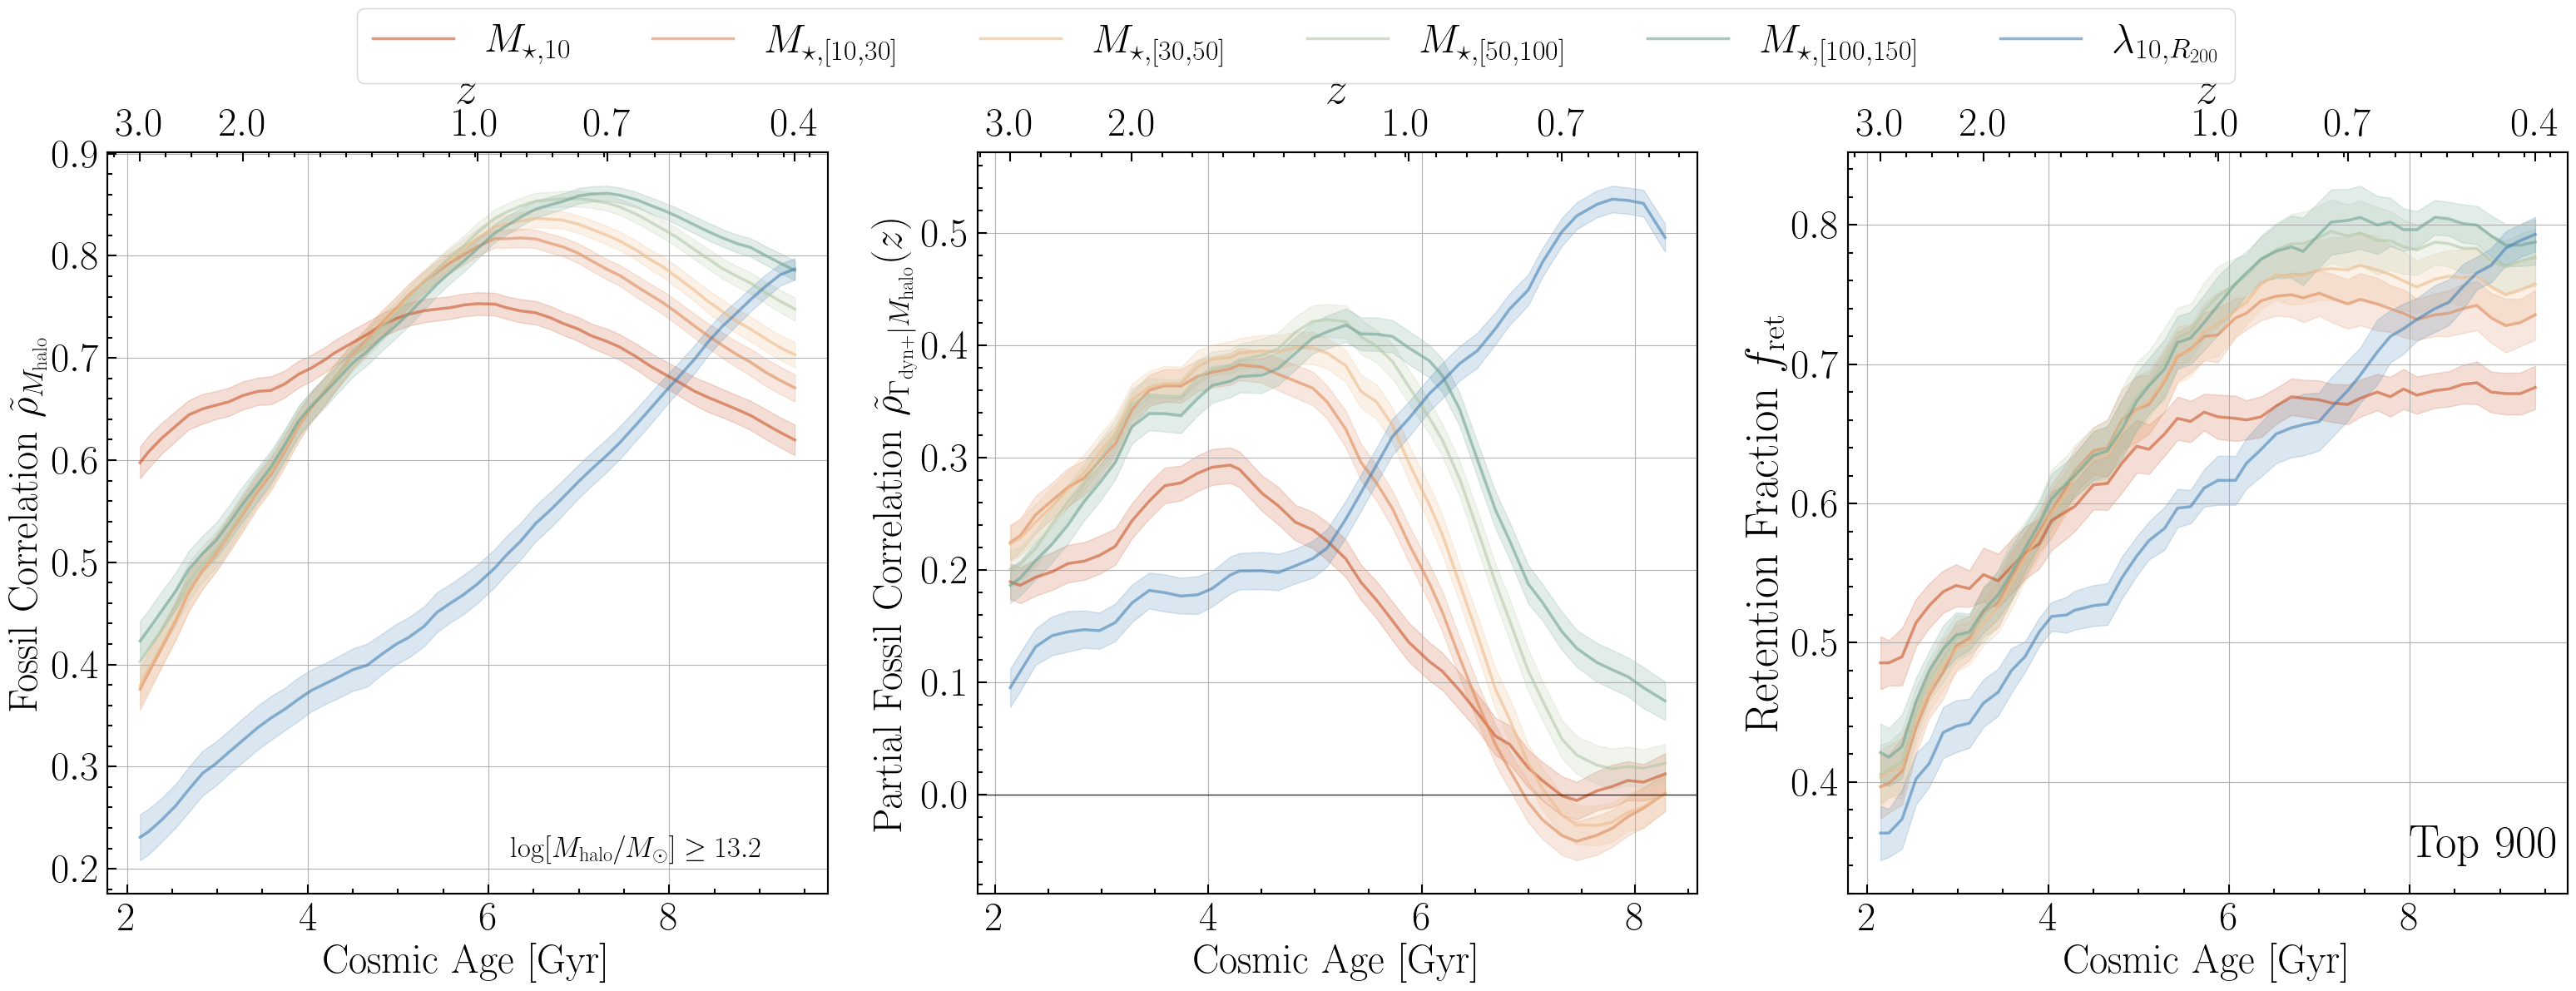

In [ ]:
snap_list=np.arange(25,73,1)
fig, axlist = plt.subplots(1, 3, figsize=(32, 12),facecolor='none')
plt.subplots_adjust(hspace=0)
ax1=axlist[0]
sma_list=[10,30,50,100,150]
color_list = palettable.cartocolors.diverging.Geyser_6.mpl_colors[::-1]
for i in range(len(sma_list)):
    sma=sma_list[i]
    if i>0:
        sma0=sma_list[i-1]
    color=color_list[i]
    snapnum_tab=[]
    corr_tab=[]
    corr_err_tab=[]
    mask1=(tab2[mask_exl]['mass_halo']>10**13.2)
    if i>0:
        xdata=np.log10(tab2[mask_exl][mask1]['aper_'+str(sma)+'_gal']-tab2[mask_exl][mask1]['aper_'+str(sma0)+'_gal'])
        label=r'$M_{\star,['+str(sma0)+','+str(sma)+']}$'
    else:
        xdata=np.log10(tab2[mask_exl][mask1]['aper_'+str(sma)+'_gal'])
        label=r'$M_{\star,'+str(sma)+'}$'
    for snapnum in range(25,73,1):
        ydata=np.log10(tab_prog_mass[mask1]['mhalo_past_'+str(snapnum)])
        mask_pk=(xdata>0)
        corr,corr_err=bootstrap_corr(xdata[mask_pk],ydata[mask_pk],method='spearman')
        corr_tab.append(corr)
        corr_err_tab.append(corr_err)
        snapnum_tab.append(snapnum)
    # ax1.errorbar(age_tab[25:73],corr_tab,yerr=corr_err_tab, alpha=0.7, fmt='h-', color=color,
    #             capsize=3, capthick=1, elinewidth=1, markersize=9,label=label) 
    ax1.plot(age_tab[25:73],corr_tab,color=color, alpha=0.6, label=label,lw=2.5)
    ax1.fill_between(age_tab[25:73],np.array(corr_tab)-np.array(corr_err_tab),np.array(corr_tab)+np.array(corr_err_tab),color=color, alpha=0.2)
corr_tab=[]
corr_err_tab=[]
for snapnum in range(25,73,1):
    ydata=np.log10(tab_prog_mass[mask1]['mhalo_past_'+str(snapnum)])
    xdata=np.log10(tab2[mask_exl][mask1]['richness_cut_r200_10']+1)
    mask_pk=(xdata>=0)
    corr,corr_err=bootstrap_corr(xdata[mask_pk],ydata[mask_pk],method='spearman')
    corr_tab.append(corr)
    corr_err_tab.append(corr_err)
    snapnum_tab.append(snapnum)
# ax1.errorbar(age_tab[25:73],corr_tab,yerr=corr_err_tab,color='steelblue', alpha=0.25, fmt='h--',
#             capsize=3, capthick=1, elinewidth=1, markersize=9,label=r'$\lambda_{10,R_{200}}$')
ax1.plot(age_tab[25:73],corr_tab,color='steelblue', alpha=0.6, label=r'$\lambda_{10,R_{200}}$', lw=2.5)
ax1.fill_between(age_tab[25:73],np.array(corr_tab)-np.array(corr_err_tab),np.array(corr_tab)+np.array(corr_err_tab),color='steelblue', alpha=0.2)
# snapnum_tab=[]
# corr_tab=[]
# corr_err_tab=[]
# for snapnum in range(25,73,1):
#     ydata=np.log10(tab_prog_mass[mask1]['mhalo_past_'+str(snapnum)])
#     xdata=np.log10(tab2[mask_exl][mask1]['mass_halo'])
#     mask_pk=(xdata>0)
#     corr,corr_err=bootstrap_corr(xdata[mask_pk],ydata[mask_pk])
#     corr_tab.append(corr)
#     corr_err_tab.append(corr_err)
#     snapnum_tab.append(snapnum)
# ax1.errorbar(age_tab[25:73],corr_tab,yerr=corr_err_tab,color='black', alpha=0.6, fmt='h-',
#             capsize=3, capthick=1, elinewidth=1, markersize=9,label=r'$M_{\rm halo}$')
ax1.text(0.56,0.05,r'$\log[M_{\rm halo}/M_\odot]\geq13.2$',transform=ax1.transAxes,fontsize=25)
ax1.set_ylabel(r'{\rm Fossil\ Correlation} $\tilde{\rho}_{M_{\rm halo}}$ ')
ax2=ax1.twiny()
x1,x2=ax1.get_xlim()
ax2.set_xlim(x1,x2)
ax2.set_xticks(age_tab[[25,33,50,59,72]],[r'$3.0$',r'$2.0$',r'$1.0$',r'$0.7$',r'$0.4$'])
ax2.set_xlabel(r'$z$', fontsize=40)
ax1.set_facecolor('white')
ax1.grid()
ax1.set_xlabel(r'\rm Cosmic Age [Gyr]')
ax1=axlist[2]
N=900
for i in range(len(sma_list)):
    sma=sma_list[i]
    name1='aper_'+str(sma)+'_gal'
    if i>0:
        sma0=sma_list[i-1]
        label=r'$M_{\star,['+str(sma0)+','+str(sma)+r']}$'
        name2='aper_'+str(sma0)+'_gal'
        mass_halo=topNoutselect(tab2[mask_exl],name1,name2,N)
    else:
        label=r'$M_{\star,'+str(sma)+r'}$'
        mass_halo=topNselect(tab2[mask_exl],name1,N)
    gal_num_list=mass_halo['gal_num'].astype(int)
    mask_num = np.isin(tab2[mask_exl]['gal_num'], gal_num_list)
    color=color_list[i]
    massive_halo_fraction_evolve(ax1,N,pos_x[mask_exl],pos_y[mask_exl],pos_z[mask_exl],mask_num,snap_list,color=color,label=label)
# mass_halo=topNselect(tab2[mask_exl],'mass_halo',N)
# gal_num_list=mass_halo['gal_num'].astype(int)
# mask_num = np.isin(tab2[mask_exl]['gal_num'], gal_num_list)
# color='black'
# massive_halo_fraction_evolve(ax1,N,pos_x[mask_exl],pos_y[mask_exl],pos_z[mask_exl],mask_num,snap_list,color=color,label=r'$M_{\rm halo}$')
name='richness_cut_r200_10'
xdata=np.log10(tab2[mask_exl][name]+1)
mask_h1=(xdata>np.min(np.log10(topNselect(tab2[mask_exl],name,N)[name]+1)))
mask_h2=(xdata==np.min(np.log10(topNselect(tab2[mask_exl],name,N)[name]+1)))
index_list=np.where(mask_h2==True)[0]
true_num=N-len(xdata[mask_h1])
array=np.zeros(len(index_list))
array[:true_num]=1
np.random.shuffle(array)
for j in range(len(index_list)):
    index=index_list[j]
    mask_h2[index]=mask_h2[index]&bool(array[j])
mask_h=mask_h1|mask_h2
mask_num=mask_h
color='steelblue'
label=r'$\lambda_{10,R_{200}}$'
massive_halo_fraction_evolve(ax1,N,pos_x[mask_exl],pos_y[mask_exl],pos_z[mask_exl],mask_num,snap_list,color=color,label=label,alpha=0.25,fmt='h--')
ax1.set_ylabel(r'\rm Retention Fraction $f_{\rm ret}$',fontsize=40)
handles, labels = ax1.get_legend_handles_labels()
ax1.text(0.78,0.05,r'\rm Top %d'%N,transform=ax1.transAxes,fontsize=40)
ax1.grid()
ax1.set_xlabel(r'\rm Cosmic Age [Gyr]')
ax2=ax1.twiny()
x1,x2=ax1.get_xlim()
ax2.set_xlim(x1,x2)
ax2.set_xticks(age_tab[[25,33,50,59,72]],[r'$3.0$',r'$2.0$',r'$1.0$',r'$0.7$',r'$0.4$'])
ax2.set_xlabel(r'$z$', fontsize=40)
snap_list=np.arange(25,66,1)
colorlist=palettable.cartocolors.diverging.Geyser_6.mpl_colors[::-1]
sma_list=[10,30,50,100,150]
ax=axlist[1]
for i in range(len(sma_list)):
    sma=sma_list[i]
    if i>0:
        sma0=sma_list[i-1]
        xdata=np.log10(tab2[mask_exl]['aper_'+str(sma)+'_gal']-tab2[mask_exl]['aper_'+str(sma0)+'_gal'])
        label=r'$M_{\star,['+str(sma0)+','+str(sma)+r']~{\rm kpc}}$'
    else:
        xdata=np.log10(tab2[mask_exl]['aper_'+str(sma)+'_gal'])
        label=r'$M_{\star,'+str(sma)+r'~{\rm kpc}}$'
    partial_corr=[]
    partial_corr_up=[]
    partial_corr_down=[]
    for snap in snap_list:
        ydata=tab_prog_mass['mhalo_past_'+str(snap)]
        zdata=tab_prog_mass['macc_new3_past_'+str(snap)]
        tab_x=QTable([xdata,ydata,zdata],names=['proxy','mhalo','macc'])
        tab_pd=tab_x.to_pandas()
        mean_corr, conf_up,conf_down=bootstrap_partial_corr(tab_pd,'proxy','macc',['mhalo'],method='spearman',times=1000)
        partial_corr.append(mean_corr)
        partial_corr_up.append(conf_up)
        partial_corr_down.append(conf_down)
    # ax.errorbar(age_tab[snap_list],partial_corr,yerr=[np.asarray(partial_corr)-np.asarray(partial_corr_down),np.asarray(partial_corr_up)-np.asarray(partial_corr)],
    #             color=colorlist[i],alpha=0.6, fmt='h-',capsize=3, capthick=1, elinewidth=1, markersize=9,label=label)
    ax.plot(age_tab[snap_list],partial_corr,color=colorlist[i], alpha=0.6, label=label,lw=2.5)
    ax.fill_between(age_tab[snap_list],np.array(partial_corr_down),np.array(partial_corr_up),color=colorlist[i], alpha=0.1)
xdata=np.log10(tab2[mask_exl]['richness_cut_r200_10']+1)
partial_corr=[]
partial_corr_up=[]
partial_corr_down=[]
for snap in snap_list:
    ydata=tab_prog_mass['mhalo_past_'+str(snap)]
    zdata=tab_prog_mass['macc_new3_past_'+str(snap)]
    tab_x=QTable([xdata,ydata,zdata],names=['proxy','mhalo','macc'])
    tab_pd=tab_x.to_pandas()
    mean_corr, conf_up,conf_down=bootstrap_partial_corr(tab_pd,'proxy','macc',['mhalo'],method='spearman',times=1000)
    partial_corr.append(mean_corr)
    partial_corr_up.append(conf_up)
    partial_corr_down.append(conf_down)
# ax.errorbar(age_tab[snap_list],partial_corr,yerr=[np.asarray(partial_corr)-np.asarray(partial_corr_down),np.asarray(partial_corr_up)-np.asarray(partial_corr)],
#             color='steelblue', fmt='o--',capsize=3, capthick=1, elinewidth=1, markersize=9,label=r'$\lambda_{10,R_{200}}$')
ax.plot(age_tab[snap_list],partial_corr,color='steelblue', alpha=0.6, label=r'$\lambda_{10,R_{200}}$', lw=2.5)
ax.fill_between(age_tab[snap_list],np.array(partial_corr_down),np.array(partial_corr_up),color='steelblue', alpha=0.1)
ax.set_xlabel(r'\rm Cosmic Age [Gyr]')
ax.set_ylabel(r'{\rm Partial Fossil Correlation} $\tilde{\rho}_{\Gamma_{\rm dyn+}|M_{\rm halo}}(z)$')
ax.grid()
ax.axhline(0, color='black', linestyle='-', linewidth=1, alpha=0.7)
ax2=ax.twiny()
x1,x2=ax.get_xlim()
ax2.set_xlim(x1,x2)
ax2.set_xticks(age_tab[[25,33,50,59]],[r'$3.0$',r'$2.0$',r'$1.0$',r'$0.7$'])
ax2.set_xlabel(r'$z$', fontsize=40)
plt.tight_layout()
plt.subplots_adjust(hspace=0)
for ax in axlist:
    ax.set_facecolor('white')
fig.legend(handles, labels, loc='upper center', bbox_to_anchor=(0.5, 1.04), 
           ncol=len(handles), fontsize=35)

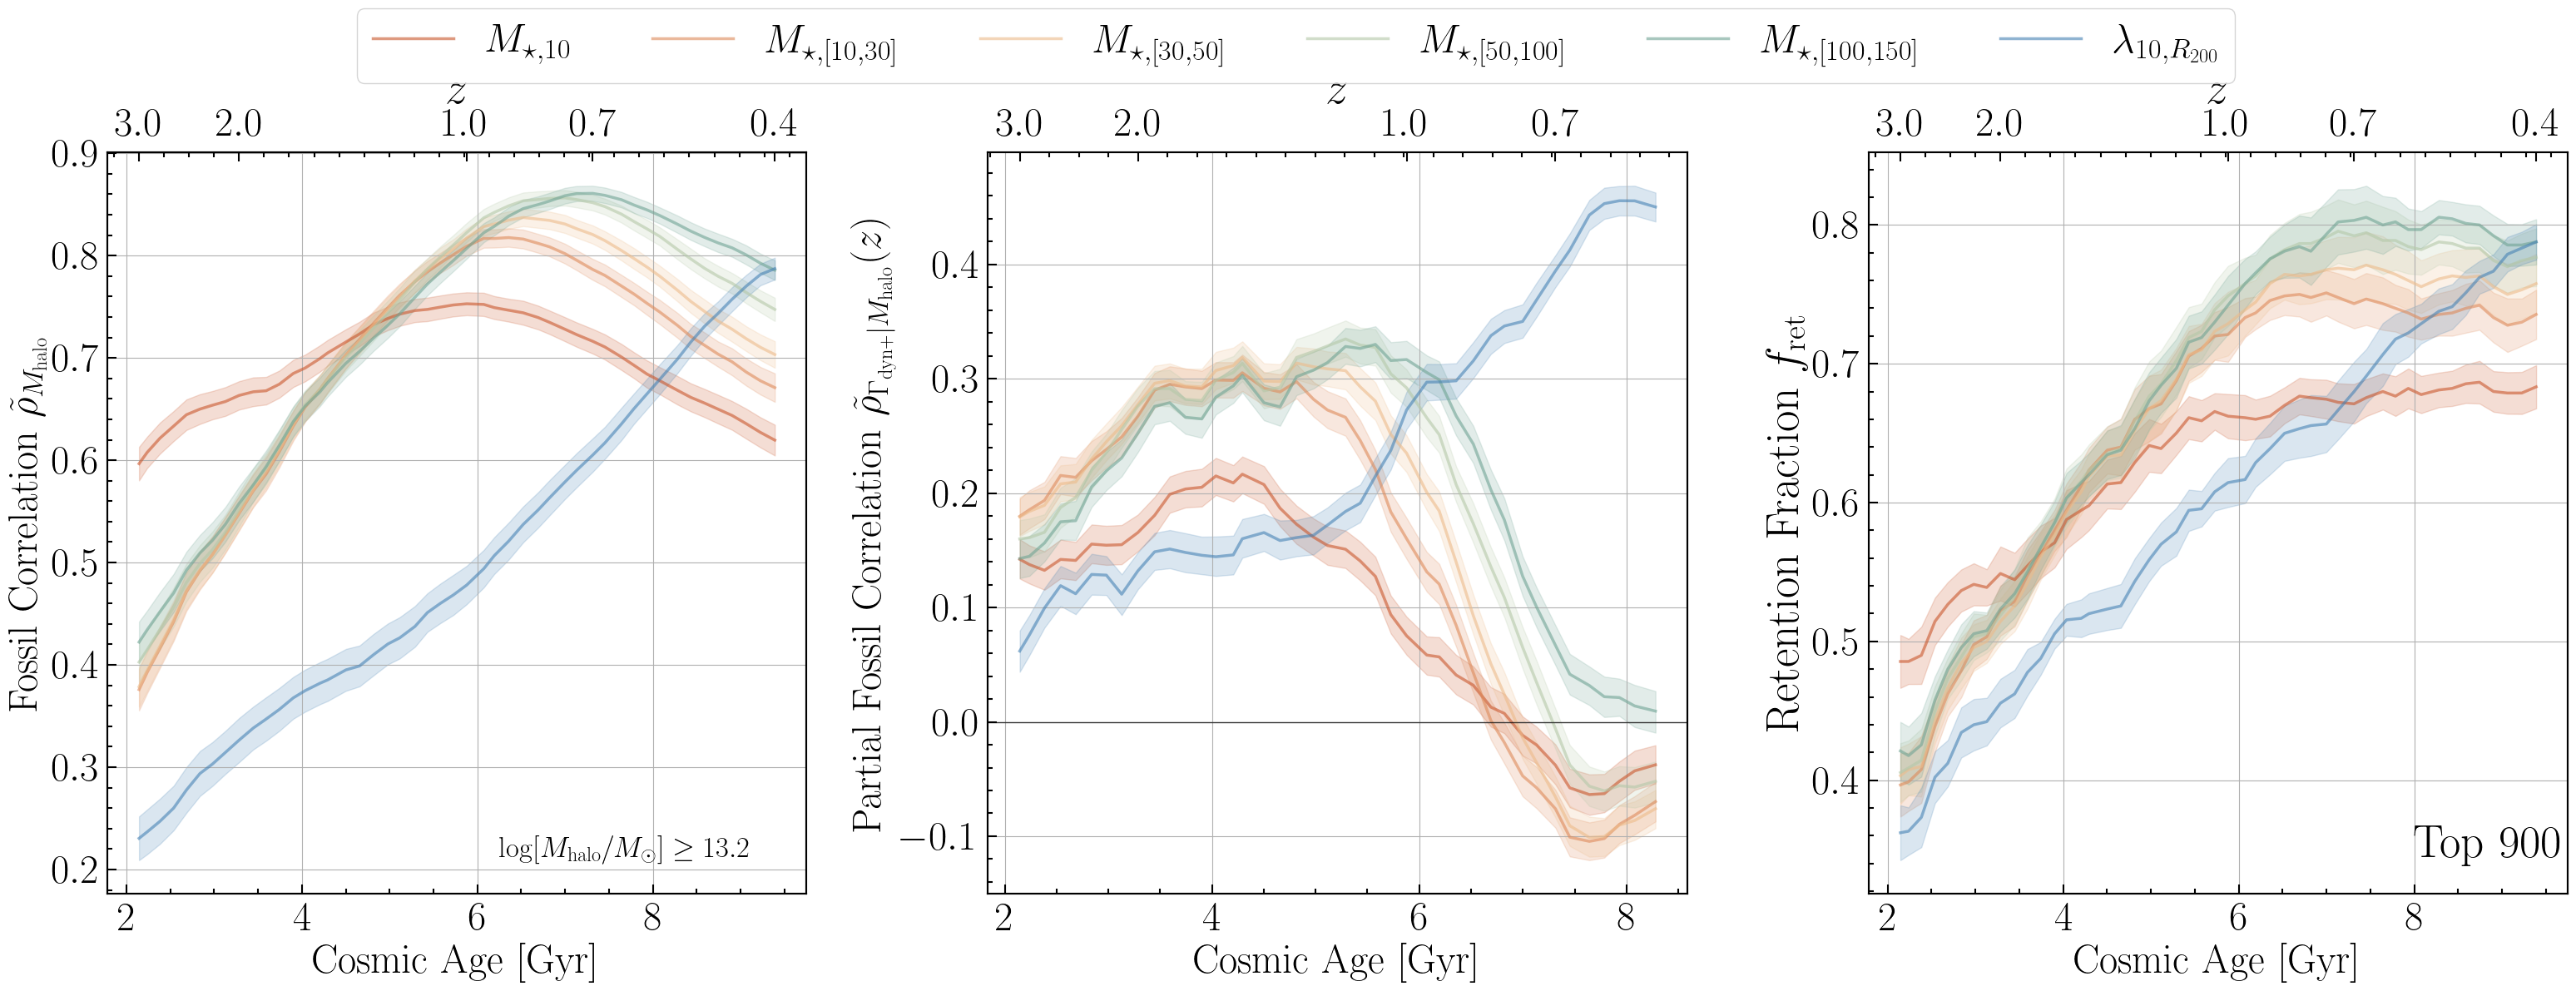

In [40]:
snap_list=np.arange(25,73,1)
fig, axlist = plt.subplots(1, 3, figsize=(32, 12),facecolor='none')
plt.subplots_adjust(hspace=0)
ax1=axlist[0]
sma_list=[10,30,50,100,150]
color_list = palettable.cartocolors.diverging.Geyser_6.mpl_colors[::-1]
for i in range(len(sma_list)):
    sma=sma_list[i]
    if i>0:
        sma0=sma_list[i-1]
    color=color_list[i]
    snapnum_tab=[]
    corr_tab=[]
    corr_err_tab=[]
    mask1=(tab2[mask_exl]['mass_halo']>10**13.2)
    if i>0:
        xdata=np.log10(tab2[mask_exl][mask1]['aper_'+str(sma)+'_gal']-tab2[mask_exl][mask1]['aper_'+str(sma0)+'_gal'])
        label=r'$M_{\star,['+str(sma0)+','+str(sma)+']}$'
    else:
        xdata=np.log10(tab2[mask_exl][mask1]['aper_'+str(sma)+'_gal'])
        label=r'$M_{\star,'+str(sma)+'}$'
    for snapnum in range(25,73,1):
        ydata=np.log10(tab_prog_mass[mask1]['mhalo_past_'+str(snapnum)])
        mask_pk=(xdata>0)
        corr,corr_err=bootstrap_corr(xdata[mask_pk],ydata[mask_pk],method='spearman')
        corr_tab.append(corr)
        corr_err_tab.append(corr_err)
        snapnum_tab.append(snapnum)
    # ax1.errorbar(age_tab[25:73],corr_tab,yerr=corr_err_tab, alpha=0.7, fmt='h-', color=color,
    #             capsize=3, capthick=1, elinewidth=1, markersize=9,label=label) 
    ax1.plot(age_tab[25:73],corr_tab,color=color, alpha=0.6, label=label,lw=2.5)
    ax1.fill_between(age_tab[25:73],np.array(corr_tab)-np.array(corr_err_tab),np.array(corr_tab)+np.array(corr_err_tab),color=color, alpha=0.2)
corr_tab=[]
corr_err_tab=[]
for snapnum in range(25,73,1):
    ydata=np.log10(tab_prog_mass[mask1]['mhalo_past_'+str(snapnum)])
    xdata=np.log10(tab2[mask_exl][mask1]['richness_cut_r200_10']+1)
    mask_pk=(xdata>=0)
    corr,corr_err=bootstrap_corr(xdata[mask_pk],ydata[mask_pk],method='spearman')
    corr_tab.append(corr)
    corr_err_tab.append(corr_err)
    snapnum_tab.append(snapnum)
# ax1.errorbar(age_tab[25:73],corr_tab,yerr=corr_err_tab,color='steelblue', alpha=0.25, fmt='h--',
#             capsize=3, capthick=1, elinewidth=1, markersize=9,label=r'$\lambda_{10,R_{200}}$')
ax1.plot(age_tab[25:73],corr_tab,color='steelblue', alpha=0.6, label=r'$\lambda_{10,R_{200}}$', lw=2.5)
ax1.fill_between(age_tab[25:73],np.array(corr_tab)-np.array(corr_err_tab),np.array(corr_tab)+np.array(corr_err_tab),color='steelblue', alpha=0.2)
# snapnum_tab=[]
# corr_tab=[]
# corr_err_tab=[]
# for snapnum in range(25,73,1):
#     ydata=np.log10(tab_prog_mass[mask1]['mhalo_past_'+str(snapnum)])
#     xdata=np.log10(tab2[mask_exl][mask1]['mass_halo'])
#     mask_pk=(xdata>0)
#     corr,corr_err=bootstrap_corr(xdata[mask_pk],ydata[mask_pk])
#     corr_tab.append(corr)
#     corr_err_tab.append(corr_err)
#     snapnum_tab.append(snapnum)
# ax1.errorbar(age_tab[25:73],corr_tab,yerr=corr_err_tab,color='black', alpha=0.6, fmt='h-',
#             capsize=3, capthick=1, elinewidth=1, markersize=9,label=r'$M_{\rm halo}$')
ax1.text(0.56,0.05,r'$\log[M_{\rm halo}/M_\odot]\geq13.2$',transform=ax1.transAxes,fontsize=25)
ax1.set_ylabel(r'{\rm Fossil\ Correlation} $\tilde{\rho}_{M_{\rm halo}}$ ')
ax2=ax1.twiny()
x1,x2=ax1.get_xlim()
ax2.set_xlim(x1,x2)
ax2.set_xticks(age_tab[[25,33,50,59,72]],[r'$3.0$',r'$2.0$',r'$1.0$',r'$0.7$',r'$0.4$'])
ax2.set_xlabel(r'$z$', fontsize=40)
ax1.set_facecolor('white')
ax1.grid()
ax1.set_xlabel(r'\rm Cosmic Age [Gyr]')
ax1=axlist[2]
N=900
for i in range(len(sma_list)):
    sma=sma_list[i]
    name1='aper_'+str(sma)+'_gal'
    if i>0:
        sma0=sma_list[i-1]
        label=r'$M_{\star,['+str(sma0)+','+str(sma)+r']}$'
        name2='aper_'+str(sma0)+'_gal'
        mass_halo=topNoutselect(tab2[mask_exl],name1,name2,N)
    else:
        label=r'$M_{\star,'+str(sma)+r'}$'
        mass_halo=topNselect(tab2[mask_exl],name1,N)
    gal_num_list=mass_halo['gal_num'].astype(int)
    mask_num = np.isin(tab2[mask_exl]['gal_num'], gal_num_list)
    color=color_list[i]
    massive_halo_fraction_evolve(ax1,N,pos_x[mask_exl],pos_y[mask_exl],pos_z[mask_exl],mask_num,snap_list,color=color,label=label)
# mass_halo=topNselect(tab2[mask_exl],'mass_halo',N)
# gal_num_list=mass_halo['gal_num'].astype(int)
# mask_num = np.isin(tab2[mask_exl]['gal_num'], gal_num_list)
# color='black'
# massive_halo_fraction_evolve(ax1,N,pos_x[mask_exl],pos_y[mask_exl],pos_z[mask_exl],mask_num,snap_list,color=color,label=r'$M_{\rm halo}$')
name='richness_cut_r200_10'
xdata=np.log10(tab2[mask_exl][name]+1)
mask_h1=(xdata>np.min(np.log10(topNselect(tab2[mask_exl],name,N)[name]+1)))
mask_h2=(xdata==np.min(np.log10(topNselect(tab2[mask_exl],name,N)[name]+1)))
index_list=np.where(mask_h2==True)[0]
true_num=N-len(xdata[mask_h1])
array=np.zeros(len(index_list))
array[:true_num]=1
np.random.shuffle(array)
for j in range(len(index_list)):
    index=index_list[j]
    mask_h2[index]=mask_h2[index]&bool(array[j])
mask_h=mask_h1|mask_h2
mask_num=mask_h
color='steelblue'
label=r'$\lambda_{10,R_{200}}$'
massive_halo_fraction_evolve(ax1,N,pos_x[mask_exl],pos_y[mask_exl],pos_z[mask_exl],mask_num,snap_list,color=color,label=label,alpha=0.25,fmt='h--')
ax1.set_ylabel(r'\rm Retention Fraction $f_{\rm ret}$',fontsize=40)
handles, labels = ax1.get_legend_handles_labels()
ax1.text(0.78,0.05,r'\rm Top %d'%N,transform=ax1.transAxes,fontsize=40)
ax1.grid()
ax1.set_xlabel(r'\rm Cosmic Age [Gyr]')
ax2=ax1.twiny()
x1,x2=ax1.get_xlim()
ax2.set_xlim(x1,x2)
ax2.set_xticks(age_tab[[25,33,50,59,72]],[r'$3.0$',r'$2.0$',r'$1.0$',r'$0.7$',r'$0.4$'])
ax2.set_xlabel(r'$z$', fontsize=40)
snap_list=np.arange(25,66,1)
colorlist=palettable.cartocolors.diverging.Geyser_6.mpl_colors[::-1]
sma_list=[10,30,50,100,150]
ax=axlist[1]
for i in range(len(sma_list)):
    sma=sma_list[i]
    if i>0:
        sma0=sma_list[i-1]
        xdata=np.log10(tab2[mask_exl]['aper_'+str(sma)+'_gal']-tab2[mask_exl]['aper_'+str(sma0)+'_gal'])
        label=r'$M_{\star,['+str(sma0)+','+str(sma)+r']~{\rm kpc}}$'
    else:
        xdata=np.log10(tab2[mask_exl]['aper_'+str(sma)+'_gal'])
        label=r'$M_{\star,'+str(sma)+r'~{\rm kpc}}$'
    partial_corr=[]
    partial_corr_up=[]
    partial_corr_down=[]
    for snap in snap_list:
        ydata=tab_prog_mass['mhalo_past_'+str(snap)]
        zdata=tab_prog_mass['macc_new4_past_'+str(snap)]
        tab_x=QTable([xdata,ydata,zdata],names=['proxy','mhalo','macc'])
        tab_pd=tab_x.to_pandas()
        mean_corr, conf_up,conf_down=bootstrap_partial_corr(tab_pd,'proxy','macc',['mhalo'],method='spearman',times=1000)
        partial_corr.append(mean_corr)
        partial_corr_up.append(conf_up)
        partial_corr_down.append(conf_down)
    # ax.errorbar(age_tab[snap_list],partial_corr,yerr=[np.asarray(partial_corr)-np.asarray(partial_corr_down),np.asarray(partial_corr_up)-np.asarray(partial_corr)],
    #             color=colorlist[i],alpha=0.6, fmt='h-',capsize=3, capthick=1, elinewidth=1, markersize=9,label=label)
    ax.plot(age_tab[snap_list],partial_corr,color=colorlist[i], alpha=0.6, label=label,lw=2.5)
    ax.fill_between(age_tab[snap_list],np.array(partial_corr_down),np.array(partial_corr_up),color=colorlist[i], alpha=0.2)
xdata=np.log10(tab2[mask_exl]['richness_cut_r200_10']+1)
partial_corr=[]
partial_corr_up=[]
partial_corr_down=[]
for snap in snap_list:
    ydata=tab_prog_mass['mhalo_past_'+str(snap)]
    zdata=tab_prog_mass['macc_new4_past_'+str(snap)]
    tab_x=QTable([xdata,ydata,zdata],names=['proxy','mhalo','macc'])
    tab_pd=tab_x.to_pandas()
    mean_corr, conf_up,conf_down=bootstrap_partial_corr(tab_pd,'proxy','macc',['mhalo'],method='spearman',times=1000)
    partial_corr.append(mean_corr)
    partial_corr_up.append(conf_up)
    partial_corr_down.append(conf_down)
# ax.errorbar(age_tab[snap_list],partial_corr,yerr=[np.asarray(partial_corr)-np.asarray(partial_corr_down),np.asarray(partial_corr_up)-np.asarray(partial_corr)],
#             color='steelblue', fmt='o--',capsize=3, capthick=1, elinewidth=1, markersize=9,label=r'$\lambda_{10,R_{200}}$')
ax.plot(age_tab[snap_list],partial_corr,color='steelblue', alpha=0.6, label=r'$\lambda_{10,R_{200}}$', lw=2.5)
ax.fill_between(age_tab[snap_list],np.array(partial_corr_down),np.array(partial_corr_up),color='steelblue', alpha=0.2)
ax.set_xlabel(r'\rm Cosmic Age [Gyr]')
ax.set_ylabel(r'{\rm Partial Fossil Correlation} $\tilde{\rho}_{\Gamma_{\rm dyn+}|M_{\rm halo}}(z)$')
ax.grid()
ax.axhline(0, color='black', linestyle='-', linewidth=1, alpha=0.7)
ax2=ax.twiny()
x1,x2=ax.get_xlim()
ax2.set_xlim(x1,x2)
ax2.set_xticks(age_tab[[25,33,50,59]],[r'$3.0$',r'$2.0$',r'$1.0$',r'$0.7$'])
ax2.set_xlabel(r'$z$', fontsize=40)
plt.tight_layout()
plt.subplots_adjust(hspace=0)
for ax in axlist:
    ax.set_facecolor('white')
fig.legend(handles, labels, loc='upper center', bbox_to_anchor=(0.5, 1.04), 
           ncol=len(handles), fontsize=35)

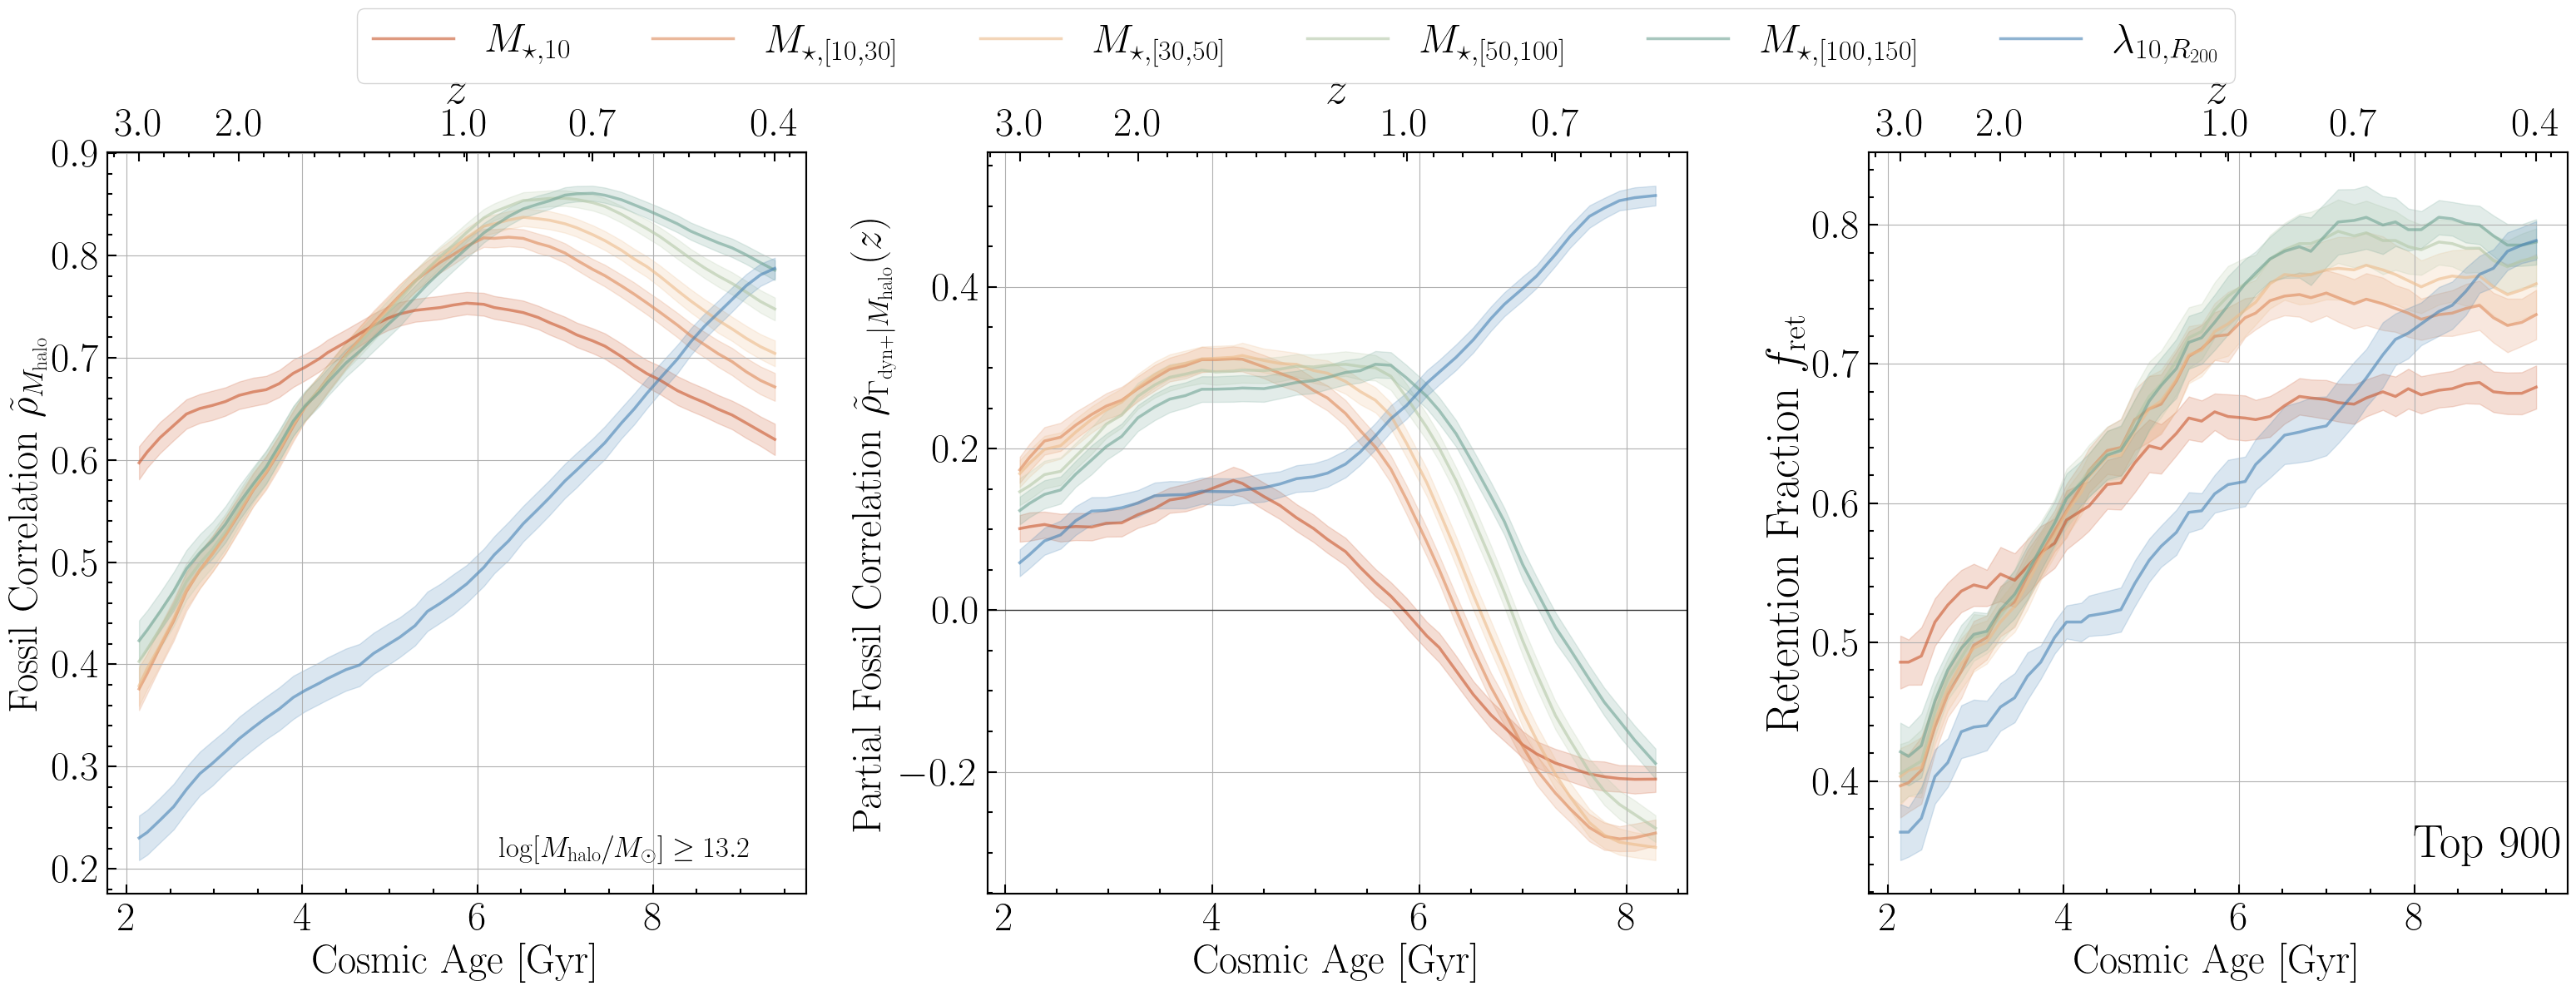

In [22]:
snap_list=np.arange(25,73,1)
fig, axlist = plt.subplots(1, 3, figsize=(32, 12),facecolor='none')
plt.subplots_adjust(hspace=0)
ax1=axlist[0]
sma_list=[10,30,50,100,150]
color_list = palettable.cartocolors.diverging.Geyser_6.mpl_colors[::-1]
for i in range(len(sma_list)):
    sma=sma_list[i]
    if i>0:
        sma0=sma_list[i-1]
    color=color_list[i]
    snapnum_tab=[]
    corr_tab=[]
    corr_err_tab=[]
    mask1=(tab2[mask_exl]['mass_halo']>10**13.2)
    if i>0:
        xdata=np.log10(tab2[mask_exl][mask1]['aper_'+str(sma)+'_gal']-tab2[mask_exl][mask1]['aper_'+str(sma0)+'_gal'])
        label=r'$M_{\star,['+str(sma0)+','+str(sma)+']}$'
    else:
        xdata=np.log10(tab2[mask_exl][mask1]['aper_'+str(sma)+'_gal'])
        label=r'$M_{\star,'+str(sma)+'}$'
    for snapnum in range(25,73,1):
        ydata=np.log10(tab_prog_mass[mask1]['mhalo_past_'+str(snapnum)])
        mask_pk=(xdata>0)
        corr,corr_err=bootstrap_corr(xdata[mask_pk],ydata[mask_pk],method='spearman')
        corr_tab.append(corr)
        corr_err_tab.append(corr_err)
        snapnum_tab.append(snapnum)
    # ax1.errorbar(age_tab[25:73],corr_tab,yerr=corr_err_tab, alpha=0.7, fmt='h-', color=color,
    #             capsize=3, capthick=1, elinewidth=1, markersize=9,label=label) 
    ax1.plot(age_tab[25:73],corr_tab,color=color, alpha=0.6, label=label,lw=2.5)
    ax1.fill_between(age_tab[25:73],np.array(corr_tab)-np.array(corr_err_tab),np.array(corr_tab)+np.array(corr_err_tab),color=color, alpha=0.2)
corr_tab=[]
corr_err_tab=[]
for snapnum in range(25,73,1):
    ydata=np.log10(tab_prog_mass[mask1]['mhalo_past_'+str(snapnum)])
    xdata=np.log10(tab2[mask_exl][mask1]['richness_cut_r200_10']+1)
    mask_pk=(xdata>=0)
    corr,corr_err=bootstrap_corr(xdata[mask_pk],ydata[mask_pk],method='spearman')
    corr_tab.append(corr)
    corr_err_tab.append(corr_err)
    snapnum_tab.append(snapnum)
# ax1.errorbar(age_tab[25:73],corr_tab,yerr=corr_err_tab,color='steelblue', alpha=0.25, fmt='h--',
#             capsize=3, capthick=1, elinewidth=1, markersize=9,label=r'$\lambda_{10,R_{200}}$')
ax1.plot(age_tab[25:73],corr_tab,color='steelblue', alpha=0.6, label=r'$\lambda_{10,R_{200}}$', lw=2.5)
ax1.fill_between(age_tab[25:73],np.array(corr_tab)-np.array(corr_err_tab),np.array(corr_tab)+np.array(corr_err_tab),color='steelblue', alpha=0.2)
# snapnum_tab=[]
# corr_tab=[]
# corr_err_tab=[]
# for snapnum in range(25,73,1):
#     ydata=np.log10(tab_prog_mass[mask1]['mhalo_past_'+str(snapnum)])
#     xdata=np.log10(tab2[mask_exl][mask1]['mass_halo'])
#     mask_pk=(xdata>0)
#     corr,corr_err=bootstrap_corr(xdata[mask_pk],ydata[mask_pk])
#     corr_tab.append(corr)
#     corr_err_tab.append(corr_err)
#     snapnum_tab.append(snapnum)
# ax1.errorbar(age_tab[25:73],corr_tab,yerr=corr_err_tab,color='black', alpha=0.6, fmt='h-',
#             capsize=3, capthick=1, elinewidth=1, markersize=9,label=r'$M_{\rm halo}$')
ax1.text(0.56,0.05,r'$\log[M_{\rm halo}/M_\odot]\geq13.2$',transform=ax1.transAxes,fontsize=25)
ax1.set_ylabel(r'{\rm Fossil\ Correlation} $\tilde{\rho}_{M_{\rm halo}}$ ')
ax2=ax1.twiny()
x1,x2=ax1.get_xlim()
ax2.set_xlim(x1,x2)
ax2.set_xticks(age_tab[[25,33,50,59,72]],[r'$3.0$',r'$2.0$',r'$1.0$',r'$0.7$',r'$0.4$'])
ax2.set_xlabel(r'$z$', fontsize=40)
ax1.set_facecolor('white')
ax1.grid()
ax1.set_xlabel(r'\rm Cosmic Age [Gyr]')
ax1=axlist[2]
N=900
for i in range(len(sma_list)):
    sma=sma_list[i]
    name1='aper_'+str(sma)+'_gal'
    if i>0:
        sma0=sma_list[i-1]
        label=r'$M_{\star,['+str(sma0)+','+str(sma)+r']}$'
        name2='aper_'+str(sma0)+'_gal'
        mass_halo=topNoutselect(tab2[mask_exl],name1,name2,N)
    else:
        label=r'$M_{\star,'+str(sma)+r'}$'
        mass_halo=topNselect(tab2[mask_exl],name1,N)
    gal_num_list=mass_halo['gal_num'].astype(int)
    mask_num = np.isin(tab2[mask_exl]['gal_num'], gal_num_list)
    color=color_list[i]
    massive_halo_fraction_evolve(ax1,N,pos_x[mask_exl],pos_y[mask_exl],pos_z[mask_exl],mask_num,snap_list,color=color,label=label)
# mass_halo=topNselect(tab2[mask_exl],'mass_halo',N)
# gal_num_list=mass_halo['gal_num'].astype(int)
# mask_num = np.isin(tab2[mask_exl]['gal_num'], gal_num_list)
# color='black'
# massive_halo_fraction_evolve(ax1,N,pos_x[mask_exl],pos_y[mask_exl],pos_z[mask_exl],mask_num,snap_list,color=color,label=r'$M_{\rm halo}$')
name='richness_cut_r200_10'
xdata=np.log10(tab2[mask_exl][name]+1)
mask_h1=(xdata>np.min(np.log10(topNselect(tab2[mask_exl],name,N)[name]+1)))
mask_h2=(xdata==np.min(np.log10(topNselect(tab2[mask_exl],name,N)[name]+1)))
index_list=np.where(mask_h2==True)[0]
true_num=N-len(xdata[mask_h1])
array=np.zeros(len(index_list))
array[:true_num]=1
np.random.shuffle(array)
for j in range(len(index_list)):
    index=index_list[j]
    mask_h2[index]=mask_h2[index]&bool(array[j])
mask_h=mask_h1|mask_h2
mask_num=mask_h
color='steelblue'
label=r'$\lambda_{10,R_{200}}$'
massive_halo_fraction_evolve(ax1,N,pos_x[mask_exl],pos_y[mask_exl],pos_z[mask_exl],mask_num,snap_list,color=color,label=label,alpha=0.25,fmt='h--')
ax1.set_ylabel(r'\rm Retention Fraction $f_{\rm ret}$',fontsize=40)
handles, labels = ax1.get_legend_handles_labels()
ax1.text(0.78,0.05,r'\rm Top %d'%N,transform=ax1.transAxes,fontsize=40)
ax1.grid()
ax1.set_xlabel(r'\rm Cosmic Age [Gyr]')
ax2=ax1.twiny()
x1,x2=ax1.get_xlim()
ax2.set_xlim(x1,x2)
ax2.set_xticks(age_tab[[25,33,50,59,72]],[r'$3.0$',r'$2.0$',r'$1.0$',r'$0.7$',r'$0.4$'])
ax2.set_xlabel(r'$z$', fontsize=40)
snap_list=np.arange(25,66,1)
colorlist=palettable.cartocolors.diverging.Geyser_6.mpl_colors[::-1]
sma_list=[10,30,50,100,150]
ax=axlist[1]
for i in range(len(sma_list)):
    sma=sma_list[i]
    if i>0:
        sma0=sma_list[i-1]
        xdata=np.log10(tab2[mask_exl]['aper_'+str(sma)+'_gal']-tab2[mask_exl]['aper_'+str(sma0)+'_gal'])
        label=r'$M_{\star,['+str(sma0)+','+str(sma)+r']~{\rm kpc}}$'
    else:
        xdata=np.log10(tab2[mask_exl]['aper_'+str(sma)+'_gal'])
        label=r'$M_{\star,'+str(sma)+r'~{\rm kpc}}$'
    partial_corr=[]
    partial_corr_up=[]
    partial_corr_down=[]
    for snap in snap_list:
        ydata=tab_prog_mass['mhalo_past_'+str(snap)]
        zdata=tab_prog_mass['macc_new2_past_'+str(snap)]
        tab_x=QTable([xdata,ydata,zdata],names=['proxy','mhalo','macc'])
        tab_pd=tab_x.to_pandas()
        mean_corr, conf_up,conf_down=bootstrap_partial_corr(tab_pd,'proxy','macc',['mhalo'],method='spearman',times=1000)
        partial_corr.append(mean_corr)
        partial_corr_up.append(conf_up)
        partial_corr_down.append(conf_down)
    # ax.errorbar(age_tab[snap_list],partial_corr,yerr=[np.asarray(partial_corr)-np.asarray(partial_corr_down),np.asarray(partial_corr_up)-np.asarray(partial_corr)],
    #             color=colorlist[i],alpha=0.6, fmt='h-',capsize=3, capthick=1, elinewidth=1, markersize=9,label=label)
    ax.plot(age_tab[snap_list],partial_corr,color=colorlist[i], alpha=0.6, label=label,lw=2.5)
    ax.fill_between(age_tab[snap_list],np.array(partial_corr_down),np.array(partial_corr_up),color=colorlist[i], alpha=0.2)
xdata=np.log10(tab2[mask_exl]['richness_cut_r200_10']+1)
partial_corr=[]
partial_corr_up=[]
partial_corr_down=[]
for snap in snap_list:
    ydata=tab_prog_mass['mhalo_past_'+str(snap)]
    zdata=tab_prog_mass['macc_new2_past_'+str(snap)]
    tab_x=QTable([xdata,ydata,zdata],names=['proxy','mhalo','macc'])
    tab_pd=tab_x.to_pandas()
    mean_corr, conf_up,conf_down=bootstrap_partial_corr(tab_pd,'proxy','macc',['mhalo'],method='spearman',times=1000)
    partial_corr.append(mean_corr)
    partial_corr_up.append(conf_up)
    partial_corr_down.append(conf_down)
# ax.errorbar(age_tab[snap_list],partial_corr,yerr=[np.asarray(partial_corr)-np.asarray(partial_corr_down),np.asarray(partial_corr_up)-np.asarray(partial_corr)],
#             color='steelblue', fmt='o--',capsize=3, capthick=1, elinewidth=1, markersize=9,label=r'$\lambda_{10,R_{200}}$')
ax.plot(age_tab[snap_list],partial_corr,color='steelblue', alpha=0.6, label=r'$\lambda_{10,R_{200}}$', lw=2.5)
ax.fill_between(age_tab[snap_list],np.array(partial_corr_down),np.array(partial_corr_up),color='steelblue', alpha=0.2)
ax.set_xlabel(r'\rm Cosmic Age [Gyr]')
ax.set_ylabel(r'{\rm Partial Fossil Correlation} $\tilde{\rho}_{\Gamma_{\rm dyn+}|M_{\rm halo}}(z)$')
ax.grid()
ax.axhline(0, color='black', linestyle='-', linewidth=1, alpha=0.7)
ax2=ax.twiny()
x1,x2=ax.get_xlim()
ax2.set_xlim(x1,x2)
ax2.set_xticks(age_tab[[25,33,50,59]],[r'$3.0$',r'$2.0$',r'$1.0$',r'$0.7$'])
ax2.set_xlabel(r'$z$', fontsize=40)
plt.tight_layout()
plt.subplots_adjust(hspace=0)
for ax in axlist:
    ax.set_facecolor('white')
fig.legend(handles, labels, loc='upper center', bbox_to_anchor=(0.5, 1.04), 
           ncol=len(handles), fontsize=35)

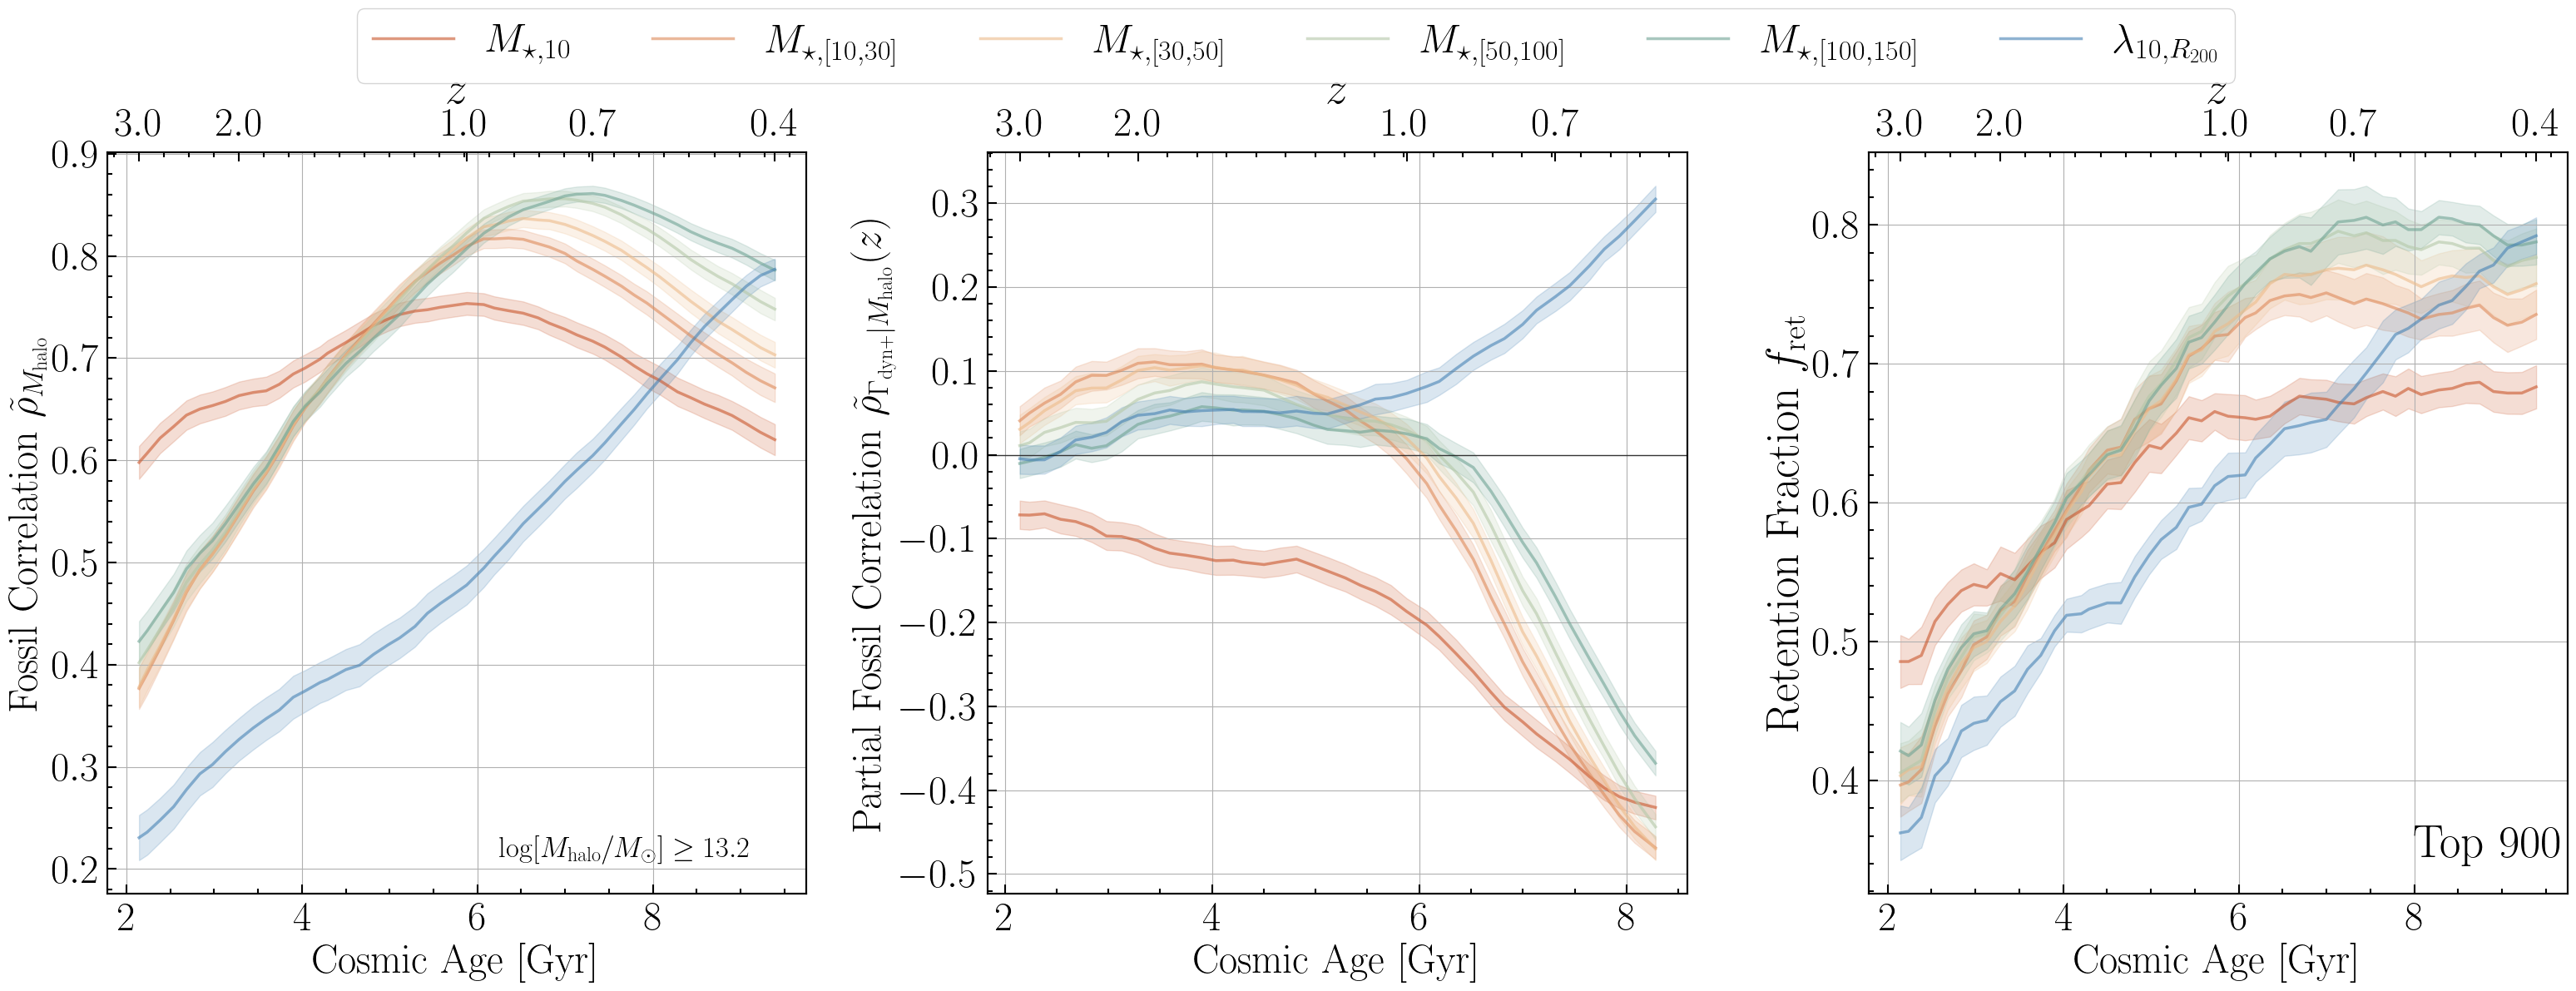

In [24]:
snap_list=np.arange(25,73,1)
fig, axlist = plt.subplots(1, 3, figsize=(32, 12),facecolor='none')
plt.subplots_adjust(hspace=0)
ax1=axlist[0]
sma_list=[10,30,50,100,150]
color_list = palettable.cartocolors.diverging.Geyser_6.mpl_colors[::-1]
for i in range(len(sma_list)):
    sma=sma_list[i]
    if i>0:
        sma0=sma_list[i-1]
    color=color_list[i]
    snapnum_tab=[]
    corr_tab=[]
    corr_err_tab=[]
    mask1=(tab2[mask_exl]['mass_halo']>10**13.2)
    if i>0:
        xdata=np.log10(tab2[mask_exl][mask1]['aper_'+str(sma)+'_gal']-tab2[mask_exl][mask1]['aper_'+str(sma0)+'_gal'])
        label=r'$M_{\star,['+str(sma0)+','+str(sma)+']}$'
    else:
        xdata=np.log10(tab2[mask_exl][mask1]['aper_'+str(sma)+'_gal'])
        label=r'$M_{\star,'+str(sma)+'}$'
    for snapnum in range(25,73,1):
        ydata=np.log10(tab_prog_mass[mask1]['mhalo_past_'+str(snapnum)])
        mask_pk=(xdata>0)
        corr,corr_err=bootstrap_corr(xdata[mask_pk],ydata[mask_pk],method='spearman')
        corr_tab.append(corr)
        corr_err_tab.append(corr_err)
        snapnum_tab.append(snapnum)
    # ax1.errorbar(age_tab[25:73],corr_tab,yerr=corr_err_tab, alpha=0.7, fmt='h-', color=color,
    #             capsize=3, capthick=1, elinewidth=1, markersize=9,label=label) 
    ax1.plot(age_tab[25:73],corr_tab,color=color, alpha=0.6, label=label,lw=2.5)
    ax1.fill_between(age_tab[25:73],np.array(corr_tab)-np.array(corr_err_tab),np.array(corr_tab)+np.array(corr_err_tab),color=color, alpha=0.2)
corr_tab=[]
corr_err_tab=[]
for snapnum in range(25,73,1):
    ydata=np.log10(tab_prog_mass[mask1]['mhalo_past_'+str(snapnum)])
    xdata=np.log10(tab2[mask_exl][mask1]['richness_cut_r200_10']+1)
    mask_pk=(xdata>=0)
    corr,corr_err=bootstrap_corr(xdata[mask_pk],ydata[mask_pk],method='spearman')
    corr_tab.append(corr)
    corr_err_tab.append(corr_err)
    snapnum_tab.append(snapnum)
# ax1.errorbar(age_tab[25:73],corr_tab,yerr=corr_err_tab,color='steelblue', alpha=0.25, fmt='h--',
#             capsize=3, capthick=1, elinewidth=1, markersize=9,label=r'$\lambda_{10,R_{200}}$')
ax1.plot(age_tab[25:73],corr_tab,color='steelblue', alpha=0.6, label=r'$\lambda_{10,R_{200}}$', lw=2.5)
ax1.fill_between(age_tab[25:73],np.array(corr_tab)-np.array(corr_err_tab),np.array(corr_tab)+np.array(corr_err_tab),color='steelblue', alpha=0.2)
# snapnum_tab=[]
# corr_tab=[]
# corr_err_tab=[]
# for snapnum in range(25,73,1):
#     ydata=np.log10(tab_prog_mass[mask1]['mhalo_past_'+str(snapnum)])
#     xdata=np.log10(tab2[mask_exl][mask1]['mass_halo'])
#     mask_pk=(xdata>0)
#     corr,corr_err=bootstrap_corr(xdata[mask_pk],ydata[mask_pk])
#     corr_tab.append(corr)
#     corr_err_tab.append(corr_err)
#     snapnum_tab.append(snapnum)
# ax1.errorbar(age_tab[25:73],corr_tab,yerr=corr_err_tab,color='black', alpha=0.6, fmt='h-',
#             capsize=3, capthick=1, elinewidth=1, markersize=9,label=r'$M_{\rm halo}$')
ax1.text(0.56,0.05,r'$\log[M_{\rm halo}/M_\odot]\geq13.2$',transform=ax1.transAxes,fontsize=25)
ax1.set_ylabel(r'{\rm Fossil\ Correlation} $\tilde{\rho}_{M_{\rm halo}}$ ')
ax2=ax1.twiny()
x1,x2=ax1.get_xlim()
ax2.set_xlim(x1,x2)
ax2.set_xticks(age_tab[[25,33,50,59,72]],[r'$3.0$',r'$2.0$',r'$1.0$',r'$0.7$',r'$0.4$'])
ax2.set_xlabel(r'$z$', fontsize=40)
ax1.set_facecolor('white')
ax1.grid()
ax1.set_xlabel(r'\rm Cosmic Age [Gyr]')
ax1=axlist[2]
N=900
for i in range(len(sma_list)):
    sma=sma_list[i]
    name1='aper_'+str(sma)+'_gal'
    if i>0:
        sma0=sma_list[i-1]
        label=r'$M_{\star,['+str(sma0)+','+str(sma)+r']}$'
        name2='aper_'+str(sma0)+'_gal'
        mass_halo=topNoutselect(tab2[mask_exl],name1,name2,N)
    else:
        label=r'$M_{\star,'+str(sma)+r'}$'
        mass_halo=topNselect(tab2[mask_exl],name1,N)
    gal_num_list=mass_halo['gal_num'].astype(int)
    mask_num = np.isin(tab2[mask_exl]['gal_num'], gal_num_list)
    color=color_list[i]
    massive_halo_fraction_evolve(ax1,N,pos_x[mask_exl],pos_y[mask_exl],pos_z[mask_exl],mask_num,snap_list,color=color,label=label)
# mass_halo=topNselect(tab2[mask_exl],'mass_halo',N)
# gal_num_list=mass_halo['gal_num'].astype(int)
# mask_num = np.isin(tab2[mask_exl]['gal_num'], gal_num_list)
# color='black'
# massive_halo_fraction_evolve(ax1,N,pos_x[mask_exl],pos_y[mask_exl],pos_z[mask_exl],mask_num,snap_list,color=color,label=r'$M_{\rm halo}$')
name='richness_cut_r200_10'
xdata=np.log10(tab2[mask_exl][name]+1)
mask_h1=(xdata>np.min(np.log10(topNselect(tab2[mask_exl],name,N)[name]+1)))
mask_h2=(xdata==np.min(np.log10(topNselect(tab2[mask_exl],name,N)[name]+1)))
index_list=np.where(mask_h2==True)[0]
true_num=N-len(xdata[mask_h1])
array=np.zeros(len(index_list))
array[:true_num]=1
np.random.shuffle(array)
for j in range(len(index_list)):
    index=index_list[j]
    mask_h2[index]=mask_h2[index]&bool(array[j])
mask_h=mask_h1|mask_h2
mask_num=mask_h
color='steelblue'
label=r'$\lambda_{10,R_{200}}$'
massive_halo_fraction_evolve(ax1,N,pos_x[mask_exl],pos_y[mask_exl],pos_z[mask_exl],mask_num,snap_list,color=color,label=label,alpha=0.25,fmt='h--')
ax1.set_ylabel(r'\rm Retention Fraction $f_{\rm ret}$',fontsize=40)
handles, labels = ax1.get_legend_handles_labels()
ax1.text(0.78,0.05,r'\rm Top %d'%N,transform=ax1.transAxes,fontsize=40)
ax1.grid()
ax1.set_xlabel(r'\rm Cosmic Age [Gyr]')
ax2=ax1.twiny()
x1,x2=ax1.get_xlim()
ax2.set_xlim(x1,x2)
ax2.set_xticks(age_tab[[25,33,50,59,72]],[r'$3.0$',r'$2.0$',r'$1.0$',r'$0.7$',r'$0.4$'])
ax2.set_xlabel(r'$z$', fontsize=40)
snap_list=np.arange(25,66,1)
colorlist=palettable.cartocolors.diverging.Geyser_6.mpl_colors[::-1]
sma_list=[10,30,50,100,150]
ax=axlist[1]
for i in range(len(sma_list)):
    sma=sma_list[i]
    if i>0:
        sma0=sma_list[i-1]
        xdata=np.log10(tab2[mask_exl]['aper_'+str(sma)+'_gal']-tab2[mask_exl]['aper_'+str(sma0)+'_gal'])
        label=r'$M_{\star,['+str(sma0)+','+str(sma)+r']~{\rm kpc}}$'
    else:
        xdata=np.log10(tab2[mask_exl]['aper_'+str(sma)+'_gal'])
        label=r'$M_{\star,'+str(sma)+r'~{\rm kpc}}$'
    partial_corr=[]
    partial_corr_up=[]
    partial_corr_down=[]
    for snap in snap_list:
        ydata=tab_prog_mass['mhalo_past_'+str(snap)]
        zdata=tab_prog_mass['macc_new_past_'+str(snap)]
        tab_x=QTable([xdata,ydata,zdata],names=['proxy','mhalo','macc'])
        tab_pd=tab_x.to_pandas()
        mean_corr, conf_up,conf_down=bootstrap_partial_corr(tab_pd,'proxy','macc',['mhalo'],method='spearman',times=1000)
        partial_corr.append(mean_corr)
        partial_corr_up.append(conf_up)
        partial_corr_down.append(conf_down)
    # ax.errorbar(age_tab[snap_list],partial_corr,yerr=[np.asarray(partial_corr)-np.asarray(partial_corr_down),np.asarray(partial_corr_up)-np.asarray(partial_corr)],
    #             color=colorlist[i],alpha=0.6, fmt='h-',capsize=3, capthick=1, elinewidth=1, markersize=9,label=label)
    ax.plot(age_tab[snap_list],partial_corr,color=colorlist[i], alpha=0.6, label=label,lw=2.5)
    ax.fill_between(age_tab[snap_list],np.array(partial_corr_down),np.array(partial_corr_up),color=colorlist[i], alpha=0.2)
xdata=np.log10(tab2[mask_exl]['richness_cut_r200_10']+1)
partial_corr=[]
partial_corr_up=[]
partial_corr_down=[]
for snap in snap_list:
    ydata=tab_prog_mass['mhalo_past_'+str(snap)]
    zdata=tab_prog_mass['macc_new_past_'+str(snap)]
    tab_x=QTable([xdata,ydata,zdata],names=['proxy','mhalo','macc'])
    tab_pd=tab_x.to_pandas()
    mean_corr, conf_up,conf_down=bootstrap_partial_corr(tab_pd,'proxy','macc',['mhalo'],method='spearman',times=1000)
    partial_corr.append(mean_corr)
    partial_corr_up.append(conf_up)
    partial_corr_down.append(conf_down)
# ax.errorbar(age_tab[snap_list],partial_corr,yerr=[np.asarray(partial_corr)-np.asarray(partial_corr_down),np.asarray(partial_corr_up)-np.asarray(partial_corr)],
#             color='steelblue', fmt='o--',capsize=3, capthick=1, elinewidth=1, markersize=9,label=r'$\lambda_{10,R_{200}}$')
ax.plot(age_tab[snap_list],partial_corr,color='steelblue', alpha=0.6, label=r'$\lambda_{10,R_{200}}$', lw=2.5)
ax.fill_between(age_tab[snap_list],np.array(partial_corr_down),np.array(partial_corr_up),color='steelblue', alpha=0.2)
ax.set_xlabel(r'\rm Cosmic Age [Gyr]')
ax.set_ylabel(r'{\rm Partial Fossil Correlation} $\tilde{\rho}_{\Gamma_{\rm dyn+}|M_{\rm halo}}(z)$')
ax.grid()
ax.axhline(0, color='black', linestyle='-', linewidth=1, alpha=0.7)
ax2=ax.twiny()
x1,x2=ax.get_xlim()
ax2.set_xlim(x1,x2)
ax2.set_xticks(age_tab[[25,33,50,59]],[r'$3.0$',r'$2.0$',r'$1.0$',r'$0.7$'])
ax2.set_xlabel(r'$z$', fontsize=40)
plt.tight_layout()
plt.subplots_adjust(hspace=0)
for ax in axlist:
    ax.set_facecolor('white')
fig.legend(handles, labels, loc='upper center', bbox_to_anchor=(0.5, 1.04), 
           ncol=len(handles), fontsize=35)

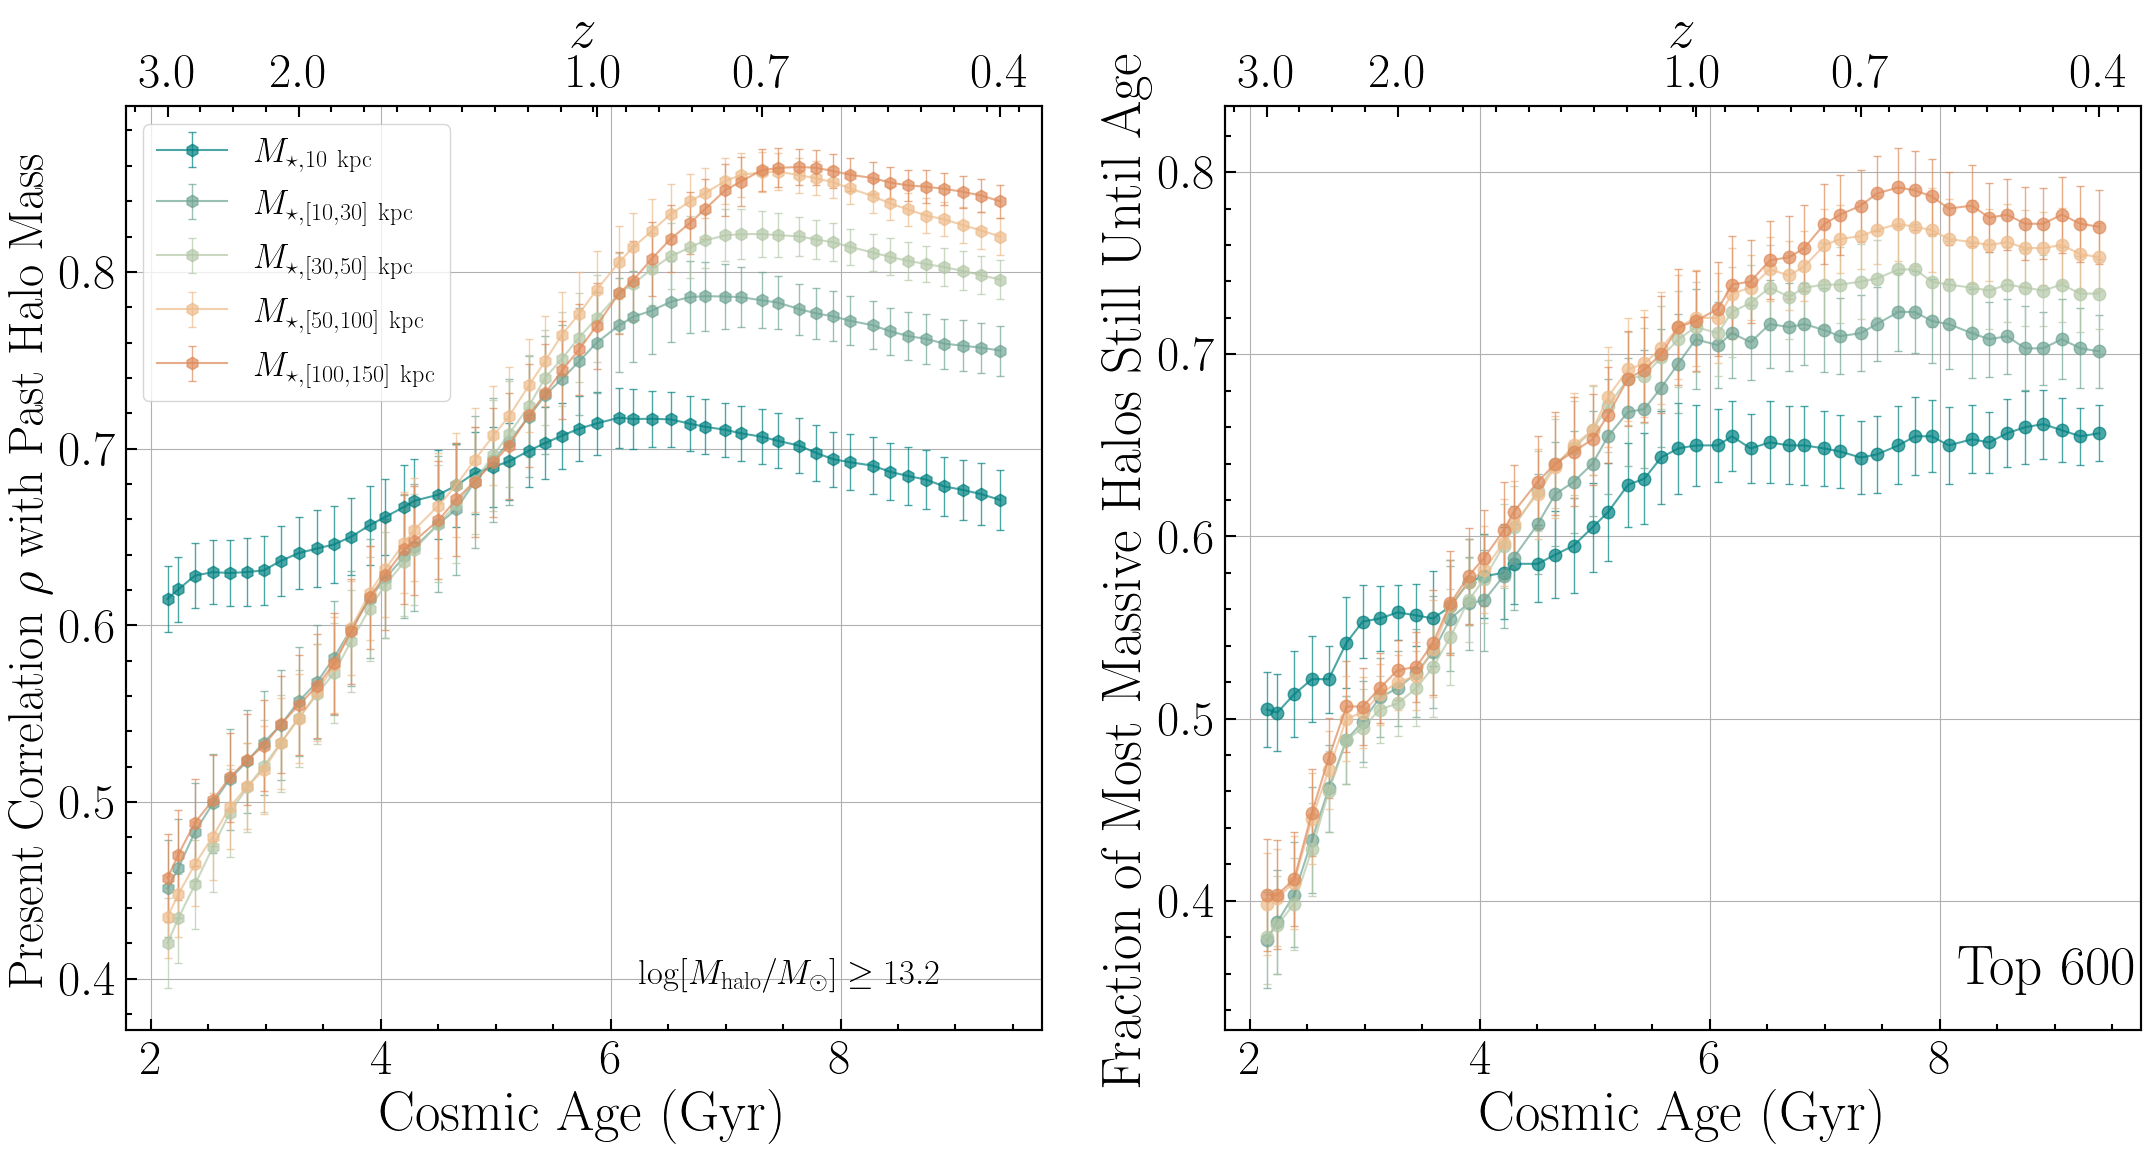

In [43]:
snap_list=np.arange(25,73,1)
fig, axlist = plt.subplots(1, 2, figsize=(26, 12),facecolor='none',sharex=True)
plt.subplots_adjust(hspace=0)
ax1=axlist[0]
sma_list=[10,30,50,100,150]
color_list = palettable.cartocolors.diverging.Geyser_6.mpl_colors
for i in range(len(sma_list)):
    sma=sma_list[i]
    if i>0:
        sma0=sma_list[i-1]
    color=color_list[i]
    snapnum_tab=[]
    corr_tab=[]
    corr_err_tab=[]
    mask1=(tab2[mask_exl]['mass_halo']>10**13.2)
    if i>0:
        xdata=np.log10(tab2[mask_exl][mask1]['aper_'+str(sma)+'_gal']-tab2[mask_exl][mask1]['aper_'+str(sma0)+'_gal'])
        label=r'$M_{\star,['+str(sma0)+','+str(sma)+r']~{\rm kpc}}$'
    else:
        xdata=np.log10(tab2[mask_exl][mask1]['aper_'+str(sma)+'_gal'])
        label=r'$M_{\star,'+str(sma)+r'~{\rm kpc}}$'
    for snapnum in range(25,73,1):
        ydata=np.log10(tab_prog_mass[mask1]['mhalo_past_'+str(snapnum)])
        mask_pk=(xdata>mpeakfind(xdata))
        corr,corr_err=bootstrap_corr(xdata[mask_pk],ydata[mask_pk])
        corr_tab.append(corr)
        corr_err_tab.append(corr_err)
        snapnum_tab.append(snapnum)
    ax1.errorbar(age_tab[25:73],corr_tab,yerr=corr_err_tab, alpha=0.7, fmt='h-', color=color,
                capsize=3, capthick=1, elinewidth=1, markersize=9,label=label) 
# snapnum_tab=[]
# corr_tab=[]
# corr_err_tab=[]
# for snapnum in range(25,73,1):
#     ydata=np.log10(tab_prog_mass[mask1]['mhalo_past_'+str(snapnum)])
#     xdata=np.log10(tab2[mask_exl][mask1]['mass_halo'])
#     mask_pk=(xdata>0)
#     corr,corr_err=bootstrap_corr(xdata[mask_pk],ydata[mask_pk])
#     corr_tab.append(corr)
#     corr_err_tab.append(corr_err)
#     snapnum_tab.append(snapnum)
# ax1.errorbar(age_tab[25:73],corr_tab,yerr=corr_err_tab,color='black', alpha=0.6, fmt='h-',
#             capsize=3, capthick=1, elinewidth=1, markersize=9,label=r'$M_{\rm halo}$')
ax1.text(0.56,0.05,r'$\log[M_{\rm halo}/M_\odot]\geq13.2$',transform=ax1.transAxes,fontsize=25)
ax1.set_ylabel(r'{\rm Present Correlation} $\rho$ {\rm with Past Halo Mass}')
ax2=ax1.twiny()
x1,x2=ax1.get_xlim()
ax2.set_xlim(x1,x2)
ax2.set_xticks(age_tab[[25,33,50,59,72]],[r'$3.0$',r'$2.0$',r'$1.0$',r'$0.7$',r'$0.4$'])
ax2.set_xlabel(r'$z$', fontsize=40)
ax1.set_facecolor('white')
ax1.grid()
ax1.set_xlabel(r'\rm Cosmic Age (Gyr)',fontsize=40)
ax1.legend(fontsize=25,loc='upper left')
ax1=axlist[1]
N=600
for i in range(len(sma_list)):
    sma=sma_list[i]
    name1='aper_'+str(sma)+'_gal'
    if i>0:
        sma0=sma_list[i-1]
        label=r'$M_{\star,['+str(sma0)+','+str(sma)+r']~{\rm kpc}}$'
        name2='aper_'+str(sma0)+'_gal'
        mass_halo=topNoutselect(tab2[mask_exl],name1,name2,N)
    else:
        label=r'$M_{\star,'+str(sma)+r'~{\rm kpc}}$'
        mass_halo=topNselect(tab2[mask_exl],name1,N)
    gal_num_list=mass_halo['gal_num'].astype(int)
    mask_num = np.isin(tab2[mask_exl]['gal_num'], gal_num_list)
    color=color_list[i]
    massive_halo_fraction_evolve(ax1,N,pos_x[mask_exl],pos_y[mask_exl],pos_z[mask_exl],mask_num,snap_list,color=color,label=label)
# mass_halo=topNselect(tab2[mask_exl],'mass_halo',N)
# gal_num_list=mass_halo['gal_num'].astype(int)
# mask_num = np.isin(tab2[mask_exl]['gal_num'], gal_num_list)
# color='black'
# massive_halo_fraction_evolve(ax1,N,pos_x[mask_exl],pos_y[mask_exl],pos_z[mask_exl],mask_num,snap_list,color=color,label=r'$M_{\rm halo}$')
ax1.set_xlabel(r'\rm Cosmic Age (Gyr)',fontsize=40)
ax1.set_ylabel(r'\rm Fraction of Most Massive Halos Still Until Age',fontsize=40)
ax1.text(0.8,0.05,r'\rm Top %d'%N,transform=ax1.transAxes,fontsize=40)
ax2=ax1.twiny()
x1,x2=ax1.get_xlim()
ax2.set_xlim(x1,x2)
ax2.set_xticks(age_tab[[25,33,50,59,72]],[r'$3.0$',r'$2.0$',r'$1.0$',r'$0.7$',r'$0.4$'])
ax2.set_xlabel(r'$z$', fontsize=40)
ax1.set_facecolor('white')
ax1.grid()

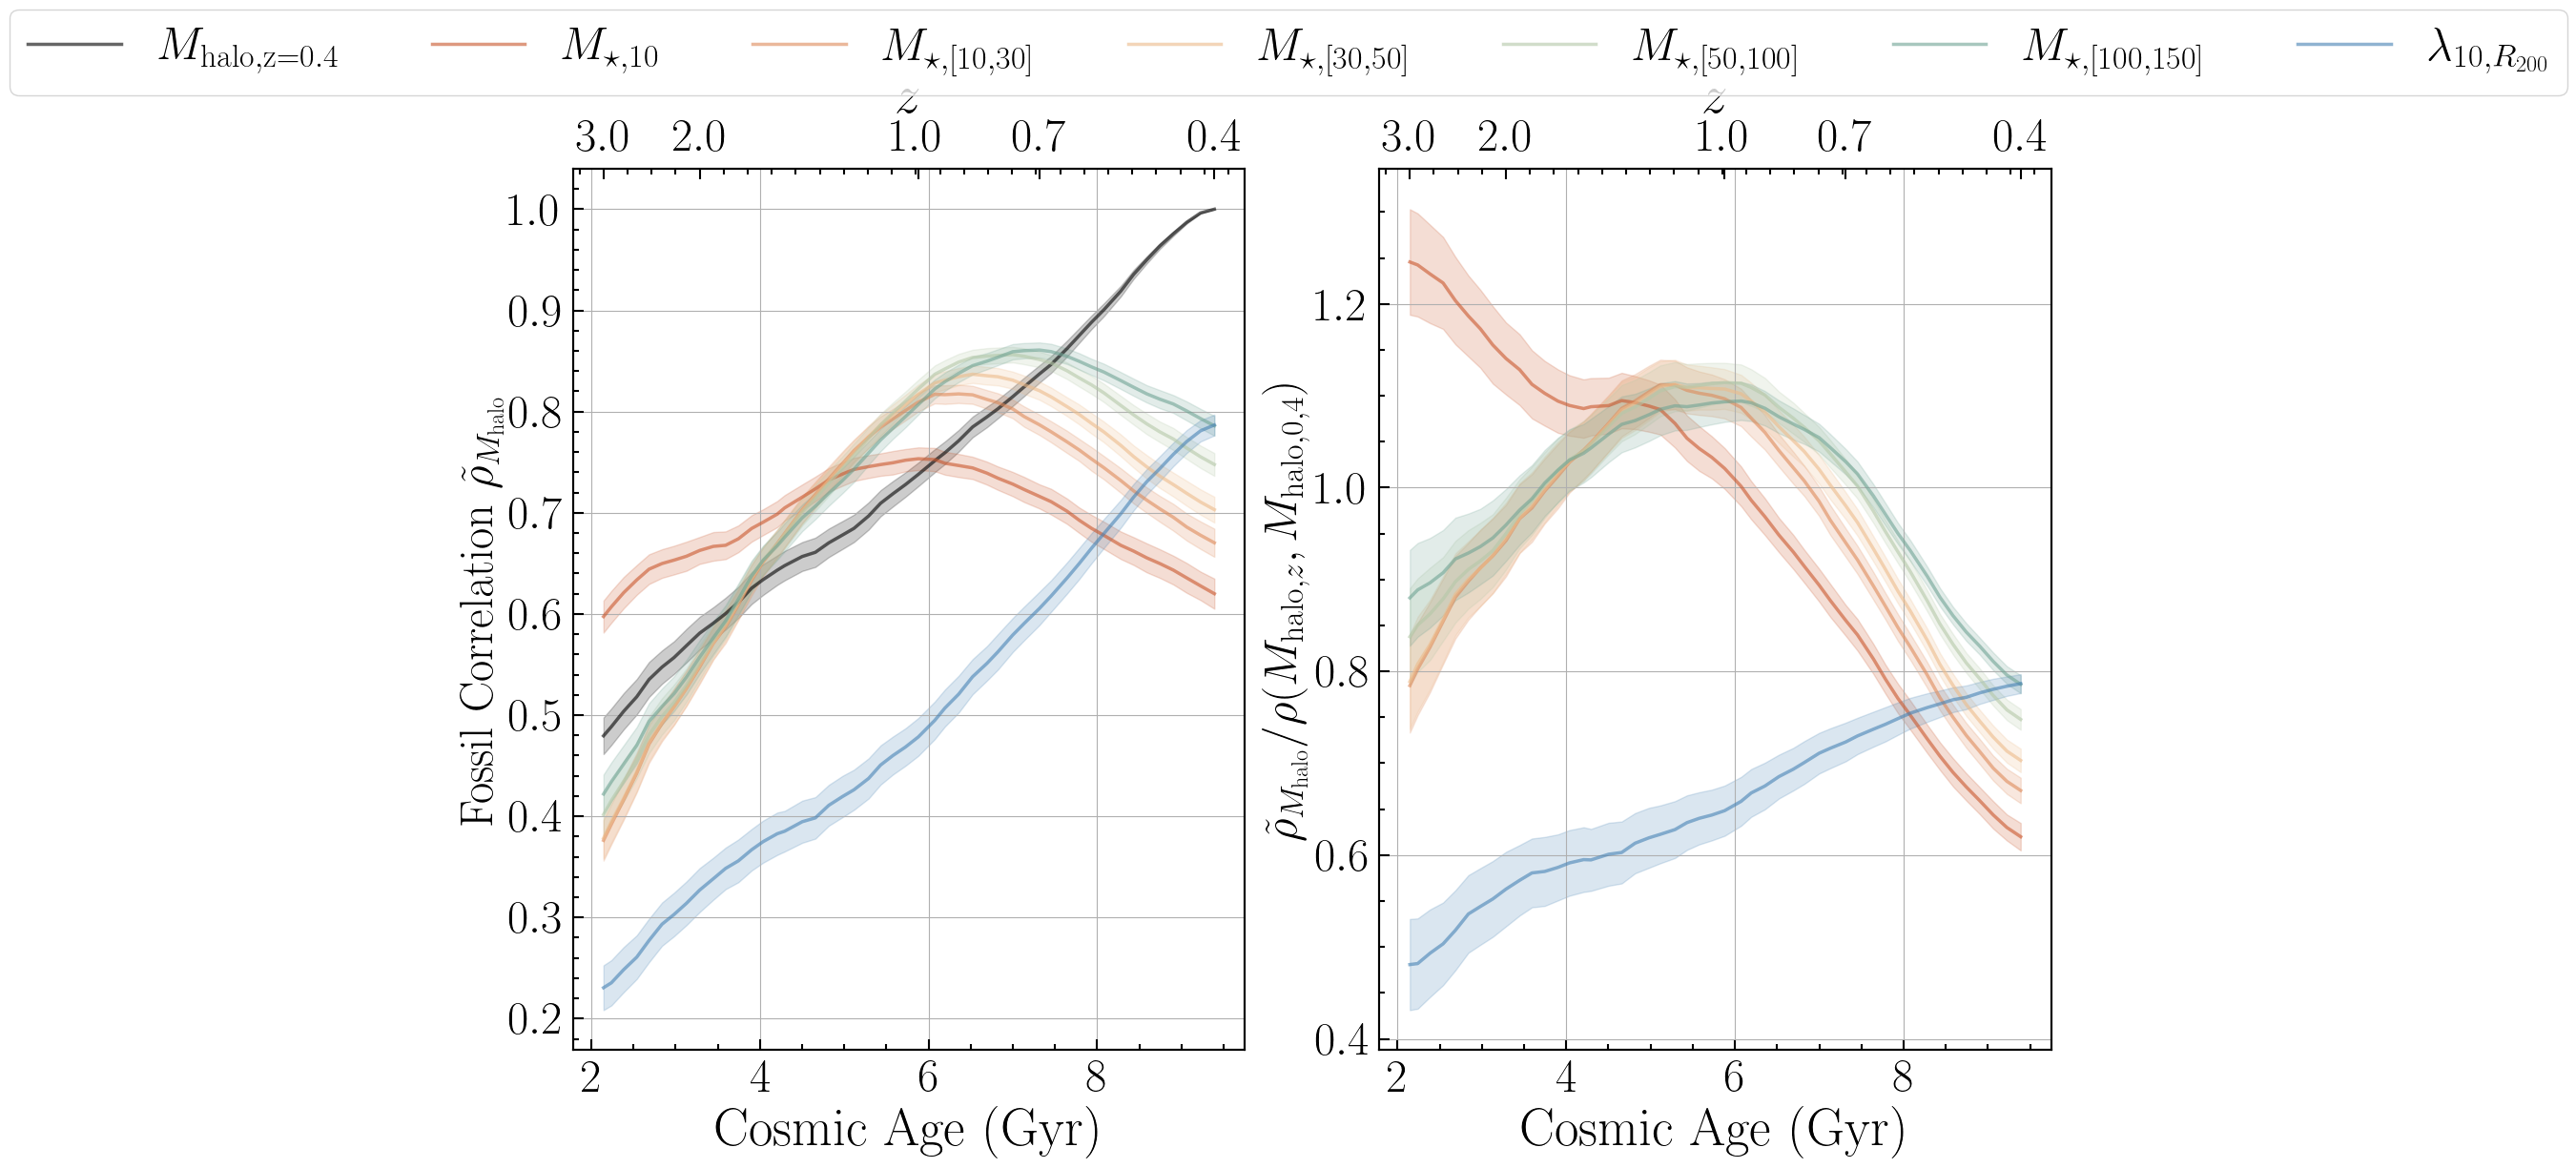

In [33]:
snap_list=np.arange(25,73,1)
fig, (ax1,ax2) = plt.subplots(1, 2, figsize=(20, 12),facecolor='none')
plt.subplots_adjust(hspace=0)
sma_list=[10,30,50,100,150]
color_list = palettable.cartocolors.diverging.Geyser_6.mpl_colors[::-1]
corr_halo_tab=[]
corr_halo_err_tab=[]
for snapnum in range(25,73,1):
    ydata=np.log10(tab_prog_mass[mask1]['mhalo_past_'+str(snapnum)])
    xdata=np.log10(tab2[mask_exl][mask1]['mass_halo'])
    mask_pk=(xdata>=0)
    corr,corr_err=bootstrap_corr(xdata[mask_pk],ydata[mask_pk],method='spearman')
    corr_halo_tab.append(corr)
    corr_halo_err_tab.append(corr_err)
    snapnum_tab.append(snapnum)
# ax1.errorbar(age_tab[25:73],corr_tab,yerr=corr_err_tab,color='steelblue', alpha=0.25, fmt='h--',
#             capsize=3, capthick=1, elinewidth=1, markersize=9,label=r'$\lambda_{10,R_{200}}$')
ax1.plot(age_tab[25:73],corr_halo_tab,color='black', alpha=0.6, label=r'$M_{\rm halo,z=0.4}$', lw=2.5)
ax1.fill_between(age_tab[25:73],np.array(corr_halo_tab)-np.array(corr_halo_err_tab),np.array(corr_halo_tab)+np.array(corr_halo_err_tab),color='black', alpha=0.2)
for i in range(len(sma_list)):
    sma=sma_list[i]
    if i>0:
        sma0=sma_list[i-1]
    color=color_list[i]
    snapnum_tab=[]
    corr_tab=[]
    corr_err_tab=[]
    mask1=(tab2[mask_exl]['mass_halo']>10**13.2)
    if i>0:
        xdata=np.log10(tab2[mask_exl][mask1]['aper_'+str(sma)+'_gal']-tab2[mask_exl][mask1]['aper_'+str(sma0)+'_gal'])
        label=r'$M_{\star,['+str(sma0)+','+str(sma)+']}$'
    else:
        xdata=np.log10(tab2[mask_exl][mask1]['aper_'+str(sma)+'_gal'])
        label=r'$M_{\star,'+str(sma)+'}$'
    for snapnum in range(25,73,1):
        ydata=np.log10(tab_prog_mass[mask1]['mhalo_past_'+str(snapnum)])
        mask_pk=(xdata>0)
        corr,corr_err=bootstrap_corr(xdata[mask_pk],ydata[mask_pk],method='spearman')
        corr_tab.append(corr)
        corr_err_tab.append(corr_err)
        snapnum_tab.append(snapnum)
    # ax1.errorbar(age_tab[25:73],corr_tab,yerr=corr_err_tab, alpha=0.7, fmt='h-', color=color,
    #             capsize=3, capthick=1, elinewidth=1, markersize=9,label=label) 
    ax1.plot(age_tab[25:73],corr_tab,color=color, alpha=0.6, label=label,lw=2.5)
    ax1.fill_between(age_tab[25:73],np.array(corr_tab)-np.array(corr_err_tab),np.array(corr_tab)+np.array(corr_err_tab),color=color, alpha=0.2)
    ratio_tab = np.asarray(corr_tab) / np.asarray(corr_halo_tab)
    ratio_err_tab = ratio_tab * np.sqrt((np.asarray(corr_err_tab) / np.asarray(corr_tab)) ** 2 + (np.asarray(corr_halo_err_tab) / np.asarray(corr_halo_tab)) ** 2)
    ax2.plot(age_tab[25:73], ratio_tab, color=color, alpha=0.6, label=label, lw=2.5)
    ax2.fill_between(age_tab[25:73], np.array(ratio_tab) - np.array(ratio_err_tab), np.array(ratio_tab) + np.array(ratio_err_tab), color=color, alpha=0.2)
corr_tab=[]
corr_err_tab=[]
for snapnum in range(25,73,1):
    ydata=np.log10(tab_prog_mass[mask1]['mhalo_past_'+str(snapnum)])
    xdata=np.log10(tab2[mask_exl][mask1]['richness_cut_r200_10']+1)
    mask_pk=(xdata>=0)
    corr,corr_err=bootstrap_corr(xdata[mask_pk],ydata[mask_pk],method='spearman')
    corr_tab.append(corr)
    corr_err_tab.append(corr_err)
    snapnum_tab.append(snapnum)
# ax1.errorbar(age_tab[25:73],corr_tab,yerr=corr_err_tab,color='steelblue', alpha=0.25, fmt='h--',
#             capsize=3, capthick=1, elinewidth=1, markersize=9,label=r'$\lambda_{10,R_{200}}$')
ax1.plot(age_tab[25:73],corr_tab,color='steelblue', alpha=0.6, label=r'$\lambda_{10,R_{200}}$', lw=2.5)
ax1.fill_between(age_tab[25:73],np.array(corr_tab)-np.array(corr_err_tab),np.array(corr_tab)+np.array(corr_err_tab),color='steelblue', alpha=0.2)
ratio_tab = np.asarray(corr_tab) / np.asarray(corr_halo_tab)
ratio_err_tab = ratio_tab * np.sqrt((np.asarray(corr_err_tab) / np.asarray(corr_tab)) **2+(np.asarray(corr_halo_err_tab) / np.asarray(corr_halo_tab)) ** 2)
ax2.plot(age_tab[25:73], ratio_tab, color='steelblue', alpha=0.6, label=r'$\lambda_{10,R_{200}}$', lw=2.5)
ax2.fill_between(age_tab[25:73], np.array(ratio_tab) - np.array(ratio_err_tab), np.array(ratio_tab) + np.array(ratio_err_tab), color='steelblue', alpha=0.2)
ax0=ax1.twiny()
x1,x2=ax1.get_xlim()
ax0.set_xlim(x1,x2)
ax0.set_xticks(age_tab[[25,33,50,59,72]],[r'$3.0$',r'$2.0$',r'$1.0$',r'$0.7$',r'$0.4$'])
ax0.set_xlabel(r'$z$', fontsize=40)
ax1.set_facecolor('white')
ax1.grid()
ax0=ax2.twiny()
x1,x2=ax2.get_xlim()
ax0.set_xlim(x1,x2)
ax0.set_xticks(age_tab[[25,33,50,59,72]],[r'$3.0$',r'$2.0$',r'$1.0$',r'$0.7$',r'$0.4$'])
ax0.set_xlabel(r'$z$', fontsize=40)
ax1.set_xlabel(r'\rm Cosmic Age (Gyr)',fontsize=40)
ax2.set_xlabel(r'\rm Cosmic Age (Gyr)',fontsize=40)
ax1.set_ylabel(r'{\rm Fossil\ Correlation} $\tilde{\rho}_{M_{\rm halo}}$ ')
ax2.set_ylabel(r'$\tilde{\rho}_{M_{\rm halo}}/\rho(M_{{\rm halo},z},M_{\rm halo,0,4})$ ')
ax2.grid()
handles, labels = ax1.get_legend_handles_labels()
fig.legend(handles, labels, loc='upper center', bbox_to_anchor=(0.5, 1.04), 
           ncol=len(handles), fontsize=35)

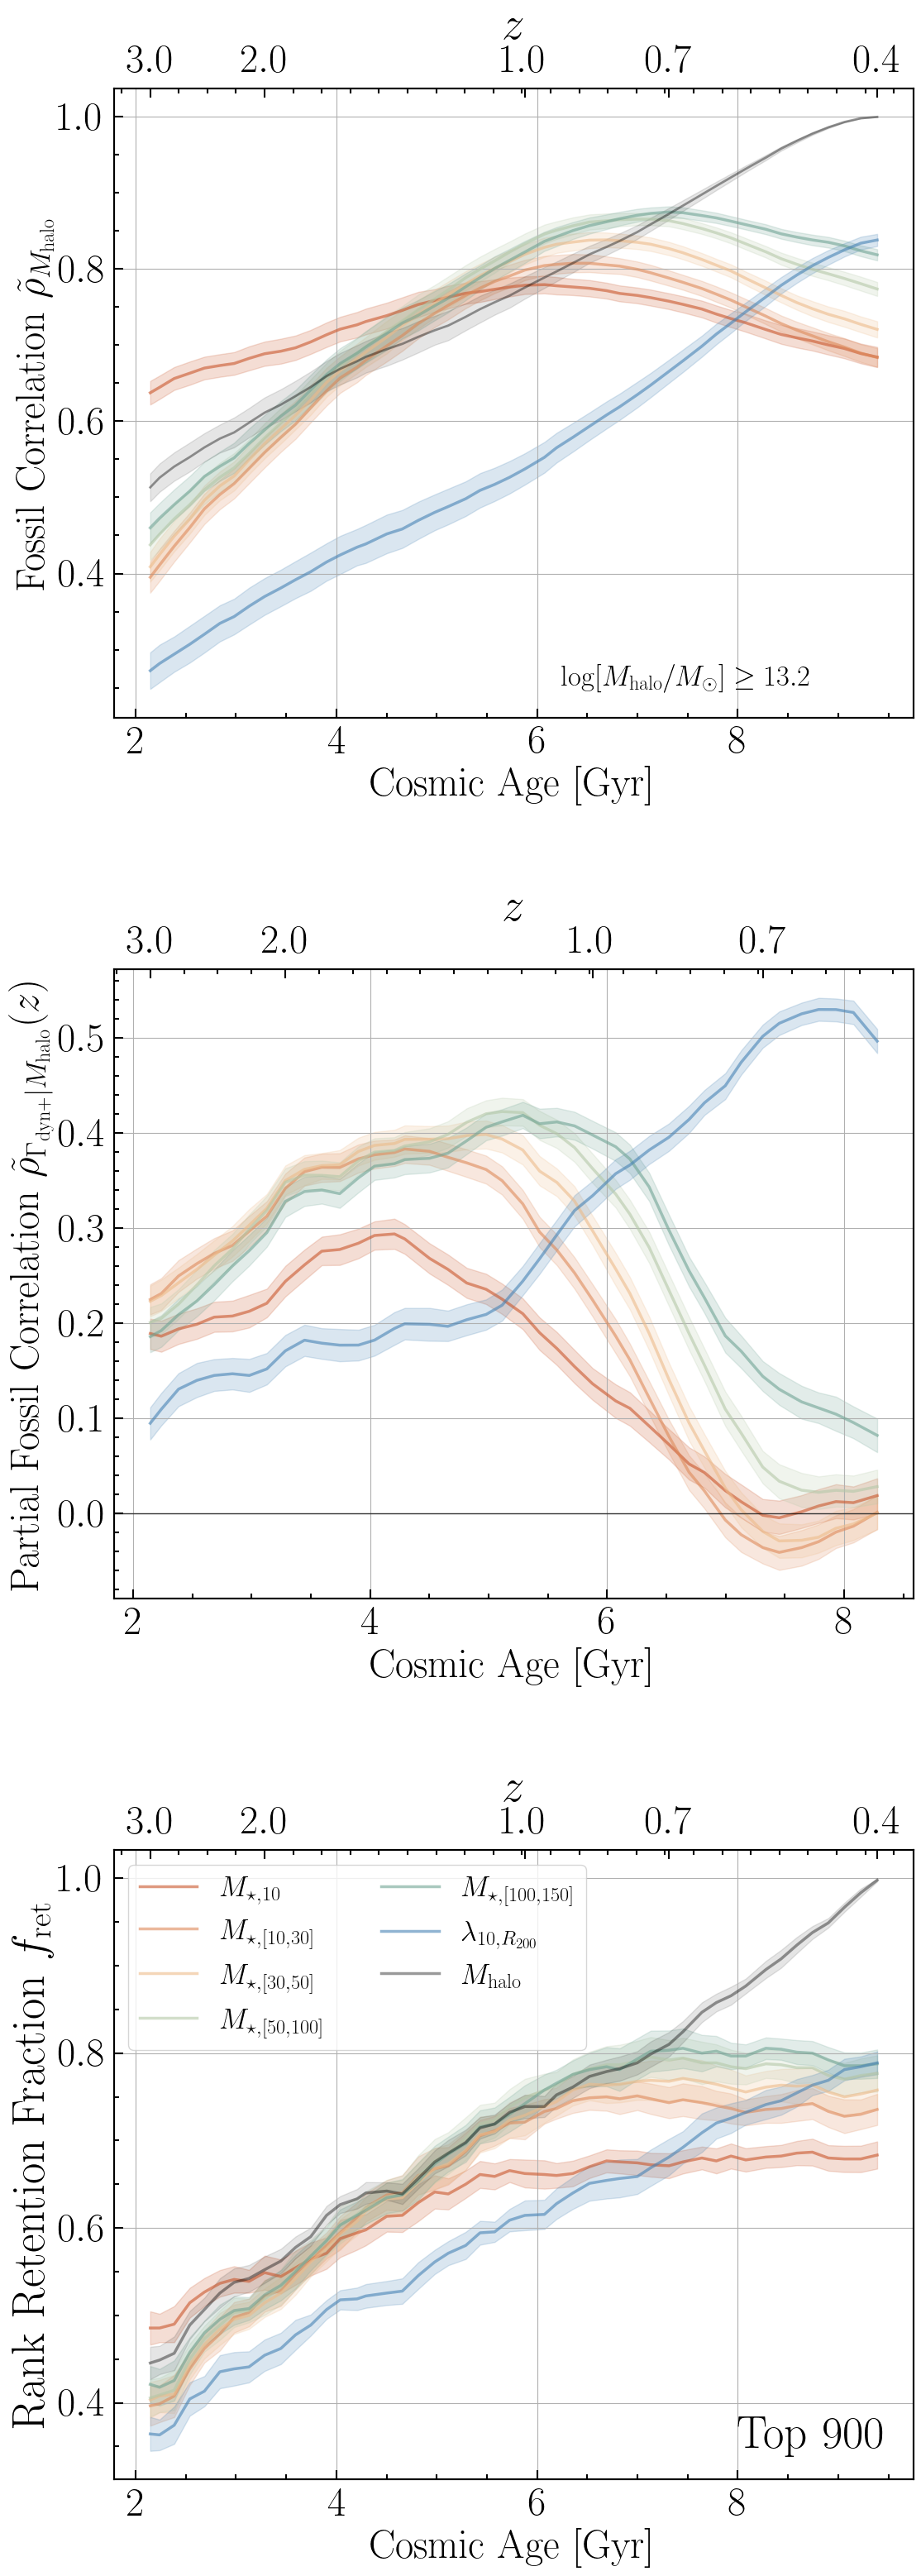

In [61]:
snap_list=np.arange(25,73,1)
fig, axlist = plt.subplots(3, 1, figsize=(12, 32),facecolor='none')
ax1=axlist[0]
sma_list=[10,30,50,100,150]
color_list = palettable.cartocolors.diverging.Geyser_6.mpl_colors[::-1]
for i in range(len(sma_list)):
    sma=sma_list[i]
    if i>0:
        sma0=sma_list[i-1]
    color=color_list[i]
    snapnum_tab=[]
    corr_tab=[]
    corr_err_tab=[]
    mask1=(tab2[mask_exl]['mass_halo']>10**13.2)
    if i>0:
        xdata=np.log10(tab2[mask_exl][mask1]['aper_'+str(sma)+'_gal']-tab2[mask_exl][mask1]['aper_'+str(sma0)+'_gal'])
        label=r'$M_{\star,['+str(sma0)+','+str(sma)+']}$'
    else:
        xdata=np.log10(tab2[mask_exl][mask1]['aper_'+str(sma)+'_gal'])
        label=r'$M_{\star,'+str(sma)+'}$'
    for snapnum in range(25,73,1):
        ydata=np.log10(tab_prog_mass[mask1]['mhalo_past_'+str(snapnum)])
        mask_pk=(xdata>0)
        corr,corr_err=bootstrap_corr(xdata[mask_pk],ydata[mask_pk])
        corr_tab.append(corr)
        corr_err_tab.append(corr_err)
        snapnum_tab.append(snapnum)
    # ax1.errorbar(age_tab[25:73],corr_tab,yerr=corr_err_tab, alpha=0.7, fmt='h-', color=color,
    #             capsize=3, capthick=1, elinewidth=1, markersize=9,label=label) 
    ax1.plot(age_tab[25:73],corr_tab,color=color, alpha=0.6, label=label,lw=2.5)
    ax1.fill_between(age_tab[25:73],np.array(corr_tab)-np.array(corr_err_tab),np.array(corr_tab)+np.array(corr_err_tab),color=color, alpha=0.2)
snapnum_tab=[]
corr_tab=[]
corr_err_tab=[]
for snapnum in range(25,73,1):
    ydata=np.log10(tab_prog_mass[mask1]['mhalo_past_'+str(snapnum)])
    xdata=np.log10(tab2[mask_exl][mask1]['richness_cut_r200_10']+1)
    mask_pk=(xdata>=0)
    corr,corr_err=bootstrap_corr(xdata[mask_pk],ydata[mask_pk])
    corr_tab.append(corr)
    corr_err_tab.append(corr_err)
    snapnum_tab.append(snapnum)
# ax1.errorbar(age_tab[25:73],corr_tab,yerr=corr_err_tab,color='steelblue', alpha=0.25, fmt='h--',
#             capsize=3, capthick=1, elinewidth=1, markersize=9,label=r'$\lambda_{10,R_{200}}$')
ax1.plot(age_tab[25:73],corr_tab,color='steelblue', alpha=0.6, label=r'$\lambda_{10,R_{200}}$', lw=2.5)
ax1.fill_between(age_tab[25:73],np.array(corr_tab)-np.array(corr_err_tab),np.array(corr_tab)+np.array(corr_err_tab),color='steelblue', alpha=0.2)
# snapnum_tab=[]
# corr_tab=[]
# corr_err_tab=[]
# for snapnum in range(25,73,1):
#     ydata=np.log10(tab_prog_mass[mask1]['mhalo_past_'+str(snapnum)])
#     xdata=np.log10(tab2[mask_exl][mask1]['mass_halo'])
#     mask_pk=(xdata>0)
#     corr,corr_err=bootstrap_corr(xdata[mask_pk],ydata[mask_pk])
#     corr_tab.append(corr)
#     corr_err_tab.append(corr_err)
#     snapnum_tab.append(snapnum)
# ax1.errorbar(age_tab[25:73],corr_tab,yerr=corr_err_tab,color='black', alpha=0.6, fmt='h-',
#             capsize=3, capthick=1, elinewidth=1, markersize=9,label=r'$M_{\rm halo}$')
snapnum_tab=[]
corr_halo_tab=[]
corr_halo_err_tab=[]
for snapnum in range(25,73,1):
    ydata=np.log10(tab_prog_mass[mask1]['mhalo_past_'+str(snapnum)])
    xdata=np.log10(tab2[mask_exl][mask1]['mass_halo'])
    mask_pk=(xdata>0)
    corr,corr_err=bootstrap_corr(xdata[mask_pk],ydata[mask_pk])
    corr_halo_tab.append(corr)
    corr_halo_err_tab.append(corr_err)
    snapnum_tab.append(snapnum)
ax1.plot(age_tab[25:73],corr_halo_tab,color='black', alpha=0.4, lw=2,
            label=r'$M_{\rm halo}$')
ax1.fill_between(age_tab[25:73],np.array(corr_halo_tab)-np.array(corr_halo_err_tab),np.array(corr_halo_tab)+np.array(corr_halo_err_tab),color='black', alpha=0.1)   
ax1.text(0.56,0.05,r'$\log[M_{\rm halo}/M_\odot]\geq13.2$',transform=ax1.transAxes,fontsize=25)
ax1.set_ylabel(r'{\rm Fossil\ Correlation} $\tilde{\rho}_{M_{\rm halo}}$ ')
ax2=ax1.twiny()
x1,x2=ax1.get_xlim()
ax2.set_xlim(x1,x2)
ax2.set_xticks(age_tab[[25,33,50,59,72]],[r'$3.0$',r'$2.0$',r'$1.0$',r'$0.7$',r'$0.4$'])
ax2.set_xlabel(r'$z$', fontsize=40)
ax1.set_facecolor('white')
ax1.grid()
ax1.set_xlabel(r'\rm Cosmic Age [Gyr]')
ax1=axlist[2]
N=900
for i in range(len(sma_list)):
    sma=sma_list[i]
    name1='aper_'+str(sma)+'_gal'
    if i>0:
        sma0=sma_list[i-1]
        label=r'$M_{\star,['+str(sma0)+','+str(sma)+r']}$'
        name2='aper_'+str(sma0)+'_gal'
        mass_halo=topNoutselect(tab2[mask_exl],name1,name2,N)
    else:
        label=r'$M_{\star,'+str(sma)+r'}$'
        mass_halo=topNselect(tab2[mask_exl],name1,N)
    gal_num_list=mass_halo['gal_num'].astype(int)
    mask_num = np.isin(tab2[mask_exl]['gal_num'], gal_num_list)
    color=color_list[i]
    massive_halo_fraction_evolve(ax1,N,pos_x[mask_exl],pos_y[mask_exl],pos_z[mask_exl],mask_num,snap_list,color=color,label=label)
# mass_halo=topNselect(tab2[mask_exl],'mass_halo',N)
# gal_num_list=mass_halo['gal_num'].astype(int)
# mask_num = np.isin(tab2[mask_exl]['gal_num'], gal_num_list)
# color='black'
# massive_halo_fraction_evolve(ax1,N,pos_x[mask_exl],pos_y[mask_exl],pos_z[mask_exl],mask_num,snap_list,color=color,label=r'$M_{\rm halo}$')
name='richness_cut_r200_10'
xdata=np.log10(tab2[mask_exl][name]+1)
mask_h1=(xdata>np.min(np.log10(topNselect(tab2[mask_exl],name,N)[name]+1)))
mask_h2=(xdata==np.min(np.log10(topNselect(tab2[mask_exl],name,N)[name]+1)))
index_list=np.where(mask_h2==True)[0]
true_num=N-len(xdata[mask_h1])
array=np.zeros(len(index_list))
array[:true_num]=1
np.random.shuffle(array)
for j in range(len(index_list)):
    index=index_list[j]
    mask_h2[index]=mask_h2[index]&bool(array[j])
mask_h=mask_h1|mask_h2
mask_num=mask_h
color='steelblue'
label=r'$\lambda_{10,R_{200}}$'
massive_halo_fraction_evolve(ax1,N,pos_x[mask_exl],pos_y[mask_exl],pos_z[mask_exl],mask_num,snap_list,color=color,label=label,fmt='h--')
name='mass_halo'
xdata=np.log10(tab2[mask_exl][name])
mass_halo=topNselect(tab2[mask_exl],name,N)
gal_num_list=mass_halo['gal_num'].astype(int)
mask_num = np.isin(tab2[mask_exl]['gal_num'], gal_num_list)
color='black'
massive_halo_fraction_evolve(ax1,N,pos_x[mask_exl],pos_y[mask_exl],pos_z[mask_exl],mask_num,snap_list,color=color,label=r'$M_{\rm halo}$',alpha1=0.4,alpha2=0.1,fmt='h--')
ax1.set_ylabel(r'\rm Rank Retention Fraction $f_{\rm ret}$',fontsize=40)
handles, labels = ax1.get_legend_handles_labels()
ax1.text(0.78,0.05,r'\rm Top %d'%N,transform=ax1.transAxes,fontsize=40)
ax1.grid()
ax1.set_xlabel(r'\rm Cosmic Age [Gyr]')
ax2=ax1.twiny()
x1,x2=ax1.get_xlim()
ax2.set_xlim(x1,x2)
ax2.set_xticks(age_tab[[25,33,50,59,72]],[r'$3.0$',r'$2.0$',r'$1.0$',r'$0.7$',r'$0.4$'])
ax2.set_xlabel(r'$z$', fontsize=40)
snap_list=np.arange(25,66,1)
colorlist=palettable.cartocolors.diverging.Geyser_6.mpl_colors[::-1]
sma_list=[10,30,50,100,150]
ax=axlist[1]
for i in range(len(sma_list)):
    sma=sma_list[i]
    if i>0:
        sma0=sma_list[i-1]
        xdata=np.log10(tab2[mask_exl]['aper_'+str(sma)+'_gal']-tab2[mask_exl]['aper_'+str(sma0)+'_gal'])
        label=r'$M_{\star,['+str(sma0)+','+str(sma)+r']~{\rm kpc}}$'
    else:
        xdata=np.log10(tab2[mask_exl]['aper_'+str(sma)+'_gal'])
        label=r'$M_{\star,'+str(sma)+r'~{\rm kpc}}$'
    partial_corr=[]
    partial_corr_up=[]
    partial_corr_down=[]
    for snap in snap_list:
        ydata=tab_prog_mass['mhalo_past_'+str(snap)]
        zdata=tab_prog_mass['macc_new3_past_'+str(snap)]
        tab_x=QTable([xdata,ydata,zdata],names=['proxy','mhalo','macc'])
        tab_pd=tab_x.to_pandas()
        mean_corr, conf_up,conf_down=bootstrap_partial_corr(tab_pd,'proxy','macc',['mhalo'],method='spearman',times=1000)
        partial_corr.append(mean_corr)
        partial_corr_up.append(conf_up)
        partial_corr_down.append(conf_down)
    # ax.errorbar(age_tab[snap_list],partial_corr,yerr=[np.asarray(partial_corr)-np.asarray(partial_corr_down),np.asarray(partial_corr_up)-np.asarray(partial_corr)],
    #             color=colorlist[i],alpha=0.6, fmt='h-',capsize=3, capthick=1, elinewidth=1, markersize=9,label=label)
    ax.plot(age_tab[snap_list],partial_corr,color=colorlist[i], alpha=0.6, label=label,lw=2.5)
    ax.fill_between(age_tab[snap_list],np.array(partial_corr_down),np.array(partial_corr_up),color=colorlist[i], alpha=0.2)
xdata=np.log10(tab2[mask_exl]['richness_cut_r200_10']+1)
partial_corr=[]
partial_corr_up=[]
partial_corr_down=[]
for snap in snap_list:
    ydata=tab_prog_mass['mhalo_past_'+str(snap)]
    zdata=tab_prog_mass['macc_new3_past_'+str(snap)]
    tab_x=QTable([xdata,ydata,zdata],names=['proxy','mhalo','macc'])
    tab_pd=tab_x.to_pandas()
    mean_corr, conf_up,conf_down=bootstrap_partial_corr(tab_pd,'proxy','macc',['mhalo'],method='spearman',times=1000)
    partial_corr.append(mean_corr)
    partial_corr_up.append(conf_up)
    partial_corr_down.append(conf_down)
# ax.errorbar(age_tab[snap_list],partial_corr,yerr=[np.asarray(partial_corr)-np.asarray(partial_corr_down),np.asarray(partial_corr_up)-np.asarray(partial_corr)],
#             color='steelblue', fmt='o--',capsize=3, capthick=1, elinewidth=1, markersize=9,label=r'$\lambda_{10,R_{200}}$')
ax.plot(age_tab[snap_list],partial_corr,color='steelblue', alpha=0.6, label=r'$\lambda_{10,R_{200}}$', lw=2.5)
ax.fill_between(age_tab[snap_list],np.array(partial_corr_down),np.array(partial_corr_up),color='steelblue', alpha=0.2)
ax.set_xlabel(r'\rm Cosmic Age [Gyr]')
ax.set_ylabel(r'{\rm Partial Fossil Correlation} $\tilde{\rho}_{\Gamma_{\rm dyn+}|M_{\rm halo}}(z)$')
ax.grid()
ax.axhline(0, color='black', linestyle='-', linewidth=1, alpha=0.7)
ax2=ax.twiny()
x1,x2=ax.get_xlim()
ax2.set_xlim(x1,x2)
ax2.set_xticks(age_tab[[25,33,50,59]],[r'$3.0$',r'$2.0$',r'$1.0$',r'$0.7$'])
ax2.set_xlabel(r'$z$', fontsize=40)
plt.tight_layout()
plt.subplots_adjust(hspace=0)
for ax in axlist:
    ax.set_facecolor('white')
ax1.legend(loc='upper left',fontsize=25,ncol=2)
plt.subplots_adjust(hspace=0.4)

In [28]:
tab_prog_mass

gal_num,mhalo_past_25,mhalo_past_26,mhalo_past_27,mhalo_past_28,mhalo_past_29,mhalo_past_30,mhalo_past_31,mhalo_past_32,mhalo_past_33,mhalo_past_34,mhalo_past_35,mhalo_past_36,mhalo_past_37,mhalo_past_38,mhalo_past_39,mhalo_past_40,mhalo_past_41,mhalo_past_42,mhalo_past_43,mhalo_past_44,mhalo_past_45,mhalo_past_46,mhalo_past_47,mhalo_past_48,mhalo_past_49,mhalo_past_50,mhalo_past_51,mhalo_past_52,mhalo_past_53,mhalo_past_54,mhalo_past_55,mhalo_past_56,mhalo_past_57,mhalo_past_58,mhalo_past_59,mhalo_past_60,mhalo_past_61,mhalo_past_62,mhalo_past_63,mhalo_past_64,mhalo_past_65,mhalo_past_66,mhalo_past_67,mhalo_past_68,mhalo_past_69,mhalo_past_70,mhalo_past_71,mhalo_past_72,mstar_past_25,mstar_past_26,mstar_past_27,mstar_past_28,mstar_past_29,mstar_past_30,mstar_past_31,mstar_past_32,mstar_past_33,mstar_past_34,mstar_past_35,mstar_past_36,mstar_past_37,mstar_past_38,mstar_past_39,mstar_past_40,mstar_past_41,mstar_past_42,mstar_past_43,mstar_past_44,mstar_past_45,mstar_past_46,mstar_past_47,mstar_past_48,mstar_past_49,mstar_past_50,mstar_past_51,mstar_past_52,mstar_past_53,mstar_past_54,mstar_past_55,mstar_past_56,mstar_past_57,mstar_past_58,mstar_past_59,mstar_past_60,mstar_past_61,mstar_past_62,mstar_past_63,mstar_past_64,mstar_past_65,mstar_past_66,mstar_past_67,mstar_past_68,mstar_past_69,mstar_past_70,mstar_past_71,mstar_past_72,msfr_past_25,msfr_past_26,msfr_past_27,msfr_past_28,msfr_past_29,msfr_past_30,msfr_past_31,msfr_past_32,msfr_past_33,msfr_past_34,msfr_past_35,msfr_past_36,msfr_past_37,msfr_past_38,msfr_past_39,msfr_past_40,msfr_past_41,msfr_past_42,msfr_past_43,msfr_past_44,msfr_past_45,msfr_past_46,msfr_past_47,msfr_past_48,msfr_past_49,msfr_past_50,msfr_past_51,msfr_past_52,msfr_past_53,msfr_past_54,msfr_past_55,msfr_past_56,msfr_past_57,msfr_past_58,msfr_past_59,msfr_past_60,msfr_past_61,msfr_past_62,msfr_past_63,msfr_past_64,msfr_past_65,msfr_past_66,msfr_past_67,msfr_past_68,msfr_past_69,msfr_past_70,msfr_past_71,msfr_past_72,msfr_inrad_past_25,msfr_inrad_past_26,msfr_inrad_past_27,msfr_inrad_past_28,msfr_inrad_past_29,msfr_inrad_past_30,msfr_inrad_past_31,msfr_inrad_past_32,msfr_inrad_past_33,msfr_inrad_past_34,msfr_inrad_past_35,msfr_inrad_past_36,msfr_inrad_past_37,msfr_inrad_past_38,msfr_inrad_past_39,msfr_inrad_past_40,msfr_inrad_past_41,msfr_inrad_past_42,msfr_inrad_past_43,msfr_inrad_past_44,msfr_inrad_past_45,msfr_inrad_past_46,msfr_inrad_past_47,msfr_inrad_past_48,msfr_inrad_past_49,msfr_inrad_past_50,msfr_inrad_past_51,msfr_inrad_past_52,msfr_inrad_past_53,msfr_inrad_past_54,msfr_inrad_past_55,msfr_inrad_past_56,msfr_inrad_past_57,msfr_inrad_past_58,msfr_inrad_past_59,msfr_inrad_past_60,msfr_inrad_past_61,msfr_inrad_past_62,msfr_inrad_past_63,msfr_inrad_past_64,msfr_inrad_past_65,msfr_inrad_past_66,msfr_inrad_past_67,msfr_inrad_past_68,msfr_inrad_past_69,msfr_inrad_past_70,msfr_inrad_past_71,msfr_inrad_past_72,richness_past_25,richness_past_26,richness_past_27,richness_past_28,richness_past_29,richness_past_30,richness_past_31,richness_past_32,richness_past_33,richness_past_34,richness_past_35,richness_past_36,richness_past_37,richness_past_38,richness_past_39,richness_past_40,richness_past_41,richness_past_42,richness_past_43,richness_past_44,richness_past_45,richness_past_46,richness_past_47,richness_past_48,richness_past_49,richness_past_50,richness_past_51,richness_past_52,richness_past_53,richness_past_54,richness_past_55,richness_past_56,richness_past_57,richness_past_58,richness_past_59,richness_past_60,richness_past_61,richness_past_62,richness_past_63,richness_past_64,richness_past_65,richness_past_66,richness_past_67,richness_past_68,richness_past_69,richness_past_70,richness_past_71,richness_past_72,macc_past_21,macc_past_22,macc_past_23,macc_past_24,macc_past_25,macc_past_26,macc_past_27,macc_past_28,macc_past_29,macc_past_30,macc_past_31,macc_past_32,macc_past_33,macc_past_34,macc_past_35,macc_past_36,macc_past_37,macc_past_38,macc_past_39,macc_past_40,macc_past_41,macc_past_42,macc_past_

$\rho(x,t) = \sum_{q \in x_t^{-1}(x)} \frac{\bar{\rho}(q)}{|\det \nabla_q x_t(q)|}$
